# Multi-Label Hate Speech and Abusive Language Detection in Indonesian Tweets

This notebook contains the whole study, from the data and preprocessing to the methods, experiments, evaluation, statistical tests, error analysis, follow-up experiments and cross-corpus evaluation. The dataset is the Indonesian Twitter corpus of Ibrohim and Budi (2019), with 12 hate speech and abusive language labels.

The study answers four research questions.

RQ1. How do four algorithm families, namely Bayesian, support vector machine, tree ensemble and neural network, perform on the 12 labels when they are evaluated with metrics suited to imbalanced data?

RQ2. Do class weighting, MLSMOTE and per-label threshold tuning improve performance, especially on the minority labels?

RQ3. Are the differences between the algorithms statistically significant?

RQ4. How well do the models generalise to another corpus, IndoToxic2024?

The first part of the notebook defines every function, grouped by topic. The second part runs the study: exploratory analysis, preprocessing, folds, MLSMOTE inspection, the classical model grid, evaluation, error analysis, follow-up experiments and the cross-corpus evaluation. In the second part every topic is split into small cells: cells that set values, cells that compute without showing anything, and cells that show one table or one chart.

To run the study, run all cells from the top. The expensive parts resume where they stopped. Runs already recorded in results/experiments.csv or results/experiments_ext.csv are skipped, so the notebook can be rerun safely. XGBoost, the MLP and the transformers use CUDA when it is available.

Leakage rule. TF-IDF, resampling, hyperparameter selection, threshold selection, epoch selection and ensemble thresholds use only the training part of each outer fold. The outer test fold is never used to choose anything.

# Naming Conventions

The results files store short codes. This notebook and the paper use the standard terms below.

Algorithms. cnb is Complement Naive Bayes, svm is the linear support vector machine LinearSVC, xgb is XGBoost, mlp is the multilayer perceptron and rf is the random forest.

Transformers. tf is a transformer fine-tuned with the revised protocol, and ens is an ensemble that averages the probabilities of several tf models. The main run log also holds rows with the code bert from an earlier IndoBERTweet protocol. That protocol stopped at its epoch limit in every fold, so those rows stay in the file but are excluded from every analysis.

Multi-label strategies. br is Binary Relevance, cc is Classifier Chains and lp is Label Powerset. mo means one multi-label output layer, which is how the transformers predict all labels at once.

Imbalance treatment. The condition column holds none, weight, mlsmote, mlsmote_raw or mlros. These mean no treatment, class weighting, MLSMOTE with hierarchy repair, the original MLSMOTE without repair, and ML-ROS. Tables in this notebook call this column imbalance_treatment.

Tuning. fixed means the fixed hyperparameters and the default decision threshold. thr means the fixed hyperparameters with one decision threshold per label chosen on inner validation data. tuned means a small hyperparameter search plus one decision threshold per label, both chosen on inner validation data. Comparing fixed with thr isolates the effect of threshold tuning, and comparing thr with tuned isolates the effect of the hyperparameter search.

Features. word is word unigram and bigram TF-IDF, char is character 3 to 5 gram TF-IDF, and wordchar combines both.

Metrics. jaccard_acc is the Jaccard index, also called example-based accuracy, which equals Equation 1 of Ibrohim and Budi (2019). subset_acc is subset accuracy, also called the exact match ratio. minority_macro_f1 is the macro F1 over the five minority labels. pred_hierarchy_violation_rate is the share of predicted label sets that break the annotation hierarchy.

Nested evaluation. Inner validation data are the 15 percent of each outer training fold that is held out for tuning. The outer fold is used only for testing.

Configuration IDs are built from these codes, for example svm__br__none__thr or svm__br__none__tuned. Transformer runs use the prefixes tf and ens. The IDs are kept unchanged so that stored runs are reused.

# Changes From the Previous Notebook

This notebook replaces Deteksi_Ujaran_Kebencian_MultiLabel.ipynb. It reads the same run logs, processed data, folds and stored scores.

Code structure. All imports are in one place, and every component is a short function defined once, with its own heading. The previous notebook used classes and had parallel copies of the experiment runner, the grid runner, the threshold search, the seeding function, the transformer prediction function and the pairwise comparison code. Options that were never used were removed after checking that they change no result.

Layout. In the second part the settings, the computations and the tables and charts of every topic are in separate cells. Nested loops over settings are written as one loop over their combinations. Every variable has a descriptive name, apart from X and Y for the features and labels, the metric names tp, fp, fn and f1, and lr for the learning rate, which is also its key in the settings.

Features. Every TF-IDF step uses the deterministic TF-IDF. The previous notebook defined it but called the scikit-learn TfidfVectorizer in the main grid, the tuning step, the MLSMOTE inspection and the feature inspection. The stored results in experiments.csv were produced with the deterministic TF-IDF. Rerunning four configurations reproduces them exactly with it, and not with the scikit-learn one.

Design. The thresholds-only mode thr separates threshold tuning from the hyperparameter search for Complement Naive Bayes and LinearSVC. To keep the GPU time within about two hours, the thresholds-only mode, ML-ROS and character features are not run for XGBoost and the MLP. XGBoost and the MLP get a small hyperparameter search like the other algorithms. Algorithms are compared through reference configurations fixed in advance instead of the best configuration on the test folds. The earlier IndoBERTweet protocol is excluded because it stopped at its epoch limit in every fold. Tuned XGBoost and MLP runs made with the old empty search are stale and can be removed so that they are rerun.

Statistics. Every comparison uses a paired permutation test on the out-of-fold predictions of all tweets and the corrected resampled t-test on the five folds, with a confidence interval and an equivalence test. The 12 labels are no longer used as statistical units. The corrected t-test uses the size of the outer training fold. Identity term bias is tested on the out-of-fold predictions, the cross-corpus results report confidence intervals, average precision and the F1 of a trivial classifier, and the prediction time of every reference model is measured on one machine.

Outputs. Results are shown in the notebook as tables and figures instead of being saved as CSV files. The notebook still writes the run logs, the processed data, the folds and the stored scores, because it needs them to resume, and the figures, because the paper needs them. CSV tables left in the results folder by the previous notebook are no longer updated.

Smaller fixes. The follow-up analyses use the algorithms present in the results, not only those that run on the current machine. The manual cause column of the false negatives was dropped, because no coding protocol was used, so the false negatives are shown as examples only. IRLbl and MeanIR are also reported for the deduplicated data.

# Configuration

All switches that decide which parts of the study run are in the cell below. A switch set to None is decided automatically from the available hardware.

In [1]:
# Configuration. Edit values in this cell only.
RANDOM_STATE = 42
RESULTS_CSV = "experiments.csv"  # run log of the main grid, one row per configuration and fold
EXTENDED_CSV = "experiments_ext.csv"  # run log of the follow-up experiments
RUN_GRID = True  # classical grid, resumes automatically
RUN_GPU_MODELS = None  # XGBoost and MLP, None means run them when CUDA is available
RUN_EXTENDED_GRID = True  # ML-ROS and character n-gram grid, resumes automatically
RUN_TRANSFORMERS = None  # transformer protocol and ensembles, None means automatic
RUN_CROSS_CORPUS = None  # None means run when the IndoToxic2024 file is available
RUN_INFERENCE_BENCHMARK = True  # time the prediction of 1,000 tweets for every reference model
REMOVE_STALE_RUNS = True  # True removes runs made with an older tuning grid so that they are rerun
REMOVE_OTHER_DEVICE_RUNS = True  # True reruns here the XGBoost and MLP runs made on another GPU
THRESHOLD_ONLY_ALGOS = ["cnb", "svm"]  # algorithms in the thresholds-only ablation
MLROS_ALGOS = ["cnb", "svm"]  # algorithms in the ML-ROS experiment
CHAR_FEATURE_ALGOS = ["svm"]  # algorithms in the character n-gram experiment
EQUIVALENCE_MARGIN = 0.01  # smallest difference in macro F1 that counts as meaningful
N_PERMUTATIONS = 5000  # permutations of the paired permutation test
N_BOOTSTRAP = 2000  # bootstrap samples of the cross-corpus confidence intervals
N_JOBS_CPU = None  # None means the number of CPUs minus one, at most four
DATA_REPO = (
    "https://github.com/okkyibrohim/id-multi-label-hate-speech-and-abusive-language-detection"
)

# Setup

This part imports the libraries, creates the folders, downloads the dataset, sets the random seeds and detects the computing device. PyTorch and transformers are optional. Without them the MLP and transformer parts are skipped and their stored results are used.

## Import Libraries

Every library used in the notebook is imported here. On Google Colab the packages that are missing there are installed first.

In [2]:
import ast
import json
import math
import os
import random
import re
import shutil
import subprocess
import sys
import time
from itertools import combinations, product
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "iterative-stratification",
            "xgboost>=2.0",
            "emoji>=2.10",
        ],
        check=True,
    )

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
from IPython.display import display
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold, MultilabelStratifiedShuffleSplit
from joblib import Parallel, delayed
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    hamming_loss,
    jaccard_score,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
)
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

try:
    import torch
    from torch import nn
except ImportError:  # PyTorch is installed separately, see requirements.txt
    torch = nn = None
try:
    from transformers import (
        AutoModelForSequenceClassification,
        AutoTokenizer,
        get_linear_schedule_with_warmup,
    )
except ImportError:
    AutoModelForSequenceClassification = AutoTokenizer = get_linear_schedule_with_warmup = None
try:
    import emoji
except ImportError:
    emoji = None

c:\Users\Luthfi\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Prepare Folders and Dataset

Folders for data, results and figures are created, and the dataset is cloned from the repository of the dataset authors on the first run.

In [3]:
ROOT = Path.cwd()
RAW, PROC, EXTERNAL = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "data" / "external"
RES, FIG = ROOT / "results", ROOT / "figures"
FOLDS_PATH = RES / "folds.json"
for folder in [RAW, PROC, RES, FIG, RES / "preds", RES / "preds_ext"]:
    folder.mkdir(parents=True, exist_ok=True)

if not (RAW / "re_dataset.csv").exists():  # download the dataset on the first run
    source_dir = ROOT / "data" / "_src"
    if not source_dir.exists():
        subprocess.run(
            ["git", "clone", "-q", "--depth", "1", DATA_REPO, str(source_dir)], check=True
        )
    for name in ["re_dataset.csv", "new_kamusalay.csv", "abusive.csv", "citation.bib"]:
        (RAW / name).write_bytes((source_dir / name).read_bytes())

## Set Seeds and Device

Random seeds and display options are set, and the computing device is detected. On a GPU, cuDNN runs in deterministic mode so that the MLP gives the same results on every run. Switches left at None in the configuration are decided from the device.

In [4]:
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 500)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})

DEVICE = "cuda" if torch is not None and torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    GPU_NAME = torch.cuda.get_device_name(0)
    torch.backends.cudnn.deterministic = True  # reproducible MLP training
    torch.backends.cudnn.benchmark = False
else:
    GPU_NAME = "-" if torch is not None else "- (PyTorch not installed)"
DEVICE_LABEL = f"cuda ({GPU_NAME})" if DEVICE == "cuda" else "cpu"
if RUN_GPU_MODELS is None:
    RUN_GPU_MODELS = DEVICE == "cuda"
if RUN_TRANSFORMERS is None:
    RUN_TRANSFORMERS = DEVICE == "cuda"
if N_JOBS_CPU is None:
    N_JOBS_CPU = max(1, min(4, (os.cpu_count() or 2) - 1))
pd.DataFrame(
    [
        {
            "root": str(ROOT),
            "device": DEVICE,
            "gpu": GPU_NAME,
            "gpu_models": RUN_GPU_MODELS,
            "transformers": RUN_TRANSFORMERS,
            "cpu_jobs": N_JOBS_CPU,
        }
    ]
)

,root,device,gpu,gpu_models,transformers,cpu_jobs
0,c:\Users\Luthfi\OneDrive\Dokumen\ML\UTS\FInal-Project-Machine-Learning-UNPAD,cuda,NVIDIA GeForce RTX 3050 Laptop GPU,True,True,4


# Labels and Annotation Hierarchy

The 12 labels follow a hierarchy that is checked against the data in the exploratory analysis. When HS is negative, every HS child label is negative. When HS is positive, a tweet has exactly one target, exactly one level and at least one category. HS_Other never occurs together with a specific category, and Abusive is independent of HS.

The rules are used in three places: to validate the data, to repair synthetic label sets inside MLSMOTE and to post-process predictions in the follow-up experiments.

## Label Groups

The 12 labels and their groups. The five minority labels are those whose imbalance ratio IRLbl is above the mean imbalance ratio MeanIR.

In [5]:
LABELS = [
    "HS",
    "Abusive",
    "HS_Individual",
    "HS_Group",
    "HS_Religion",
    "HS_Race",
    "HS_Physical",
    "HS_Gender",
    "HS_Other",
    "HS_Weak",
    "HS_Moderate",
    "HS_Strong",
]
LABEL_INDEX = {name: index for index, name in enumerate(LABELS)}
TARGET_LABELS = ["HS_Individual", "HS_Group"]
SPECIFIC_CATEGORIES = ["HS_Religion", "HS_Race", "HS_Physical", "HS_Gender"]
OTHER_CATEGORY = "HS_Other"
LEVEL_LABELS = ["HS_Weak", "HS_Moderate", "HS_Strong"]
HS_CHILDREN = TARGET_LABELS + SPECIFIC_CATEGORIES + [OTHER_CATEGORY] + LEVEL_LABELS
CATEGORY_LABELS = SPECIFIC_CATEGORIES + [OTHER_CATEGORY]
MINORITY_LABELS = ["HS_Religion", "HS_Race", "HS_Physical", "HS_Gender", "HS_Strong"]

## Label Indices

Turns label names into column positions. The positions of each label group are computed once.

In [6]:
def label_indices(names):
    return [LABEL_INDEX[name] for name in names]


HS_INDEX = LABEL_INDEX["HS"]
CHILD_INDICES = label_indices(HS_CHILDREN)
TARGET_INDICES = label_indices(TARGET_LABELS)
LEVEL_INDICES = label_indices(LEVEL_LABELS)
SPECIFIC_INDICES = label_indices(SPECIFIC_CATEGORIES)
OTHER_INDEX = LABEL_INDEX[OTHER_CATEGORY]
MINORITY_INDICES = label_indices(MINORITY_LABELS)

## Hierarchy Rule Masks

Returns one boolean mask per annotation rule. A row is true when it breaks that rule.

In [7]:
def hierarchy_rule_masks(Y):
    Y = np.asarray(Y).astype(int)
    hate_speech = Y[:, HS_INDEX]
    n_children = Y[:, CHILD_INDICES].sum(axis=1)
    n_targets = Y[:, TARGET_INDICES].sum(axis=1)
    n_levels = Y[:, LEVEL_INDICES].sum(axis=1)
    n_specific = Y[:, SPECIFIC_INDICES].sum(axis=1)
    other = Y[:, OTHER_INDEX]
    is_hs = hate_speech == 1
    return {
        "hs0_but_child1": (hate_speech == 0) & (n_children > 0),
        "hs1_target_not_exactly_one": is_hs & (n_targets != 1),
        "hs1_level_not_exactly_one": is_hs & (n_levels != 1),
        "hs1_no_category": is_hs & (n_specific + other == 0),
        "other_with_specific": (other == 1) & (n_specific > 0),
    }

## Hierarchy Violation Mask

Marks the rows that break at least one annotation rule.

In [8]:
def hierarchy_violation_mask(Y):
    return np.logical_or.reduce(list(hierarchy_rule_masks(Y).values()))

## Count Hierarchy Violations

Counts the rows that break each rule and the rows that break any rule.

In [9]:
def count_hierarchy_violations(Y):
    masks = hierarchy_rule_masks(Y)
    counts = {rule: int(mask.sum()) for rule, mask in masks.items()}
    counts["any_violation_rows"] = int(np.logical_or.reduce(list(masks.values())).sum())
    return counts

## Keep the Highest Label in a Group

Sets the label with the highest score in a group to positive and the rest of the group to negative. The row is changed in place.

In [10]:
def keep_highest(y_row, scores, group):
    best = group[int(np.argmax(scores[group]))]
    y_row[group] = 0
    y_row[best] = 1

## Resolve Categories

Makes sure a hate speech row has at least one category. When HS_Other occurs together with a specific category, the side with the higher score is kept. The row is changed in place.

In [11]:
def resolve_categories(y_row, scores):
    has_specific = y_row[SPECIFIC_INDICES].sum() > 0
    has_other = y_row[OTHER_INDEX] == 1
    if has_specific and has_other:
        if scores[OTHER_INDEX] > scores[SPECIFIC_INDICES].max():
            y_row[SPECIFIC_INDICES] = 0
        else:
            y_row[OTHER_INDEX] = 0
    elif not has_specific and not has_other:
        categories = SPECIFIC_INDICES + [OTHER_INDEX]
        y_row[categories[int(np.argmax(scores[categories]))]] = 1

## Repair Synthetic Label Set

Makes one synthetic label set from MLSMOTE follow the hierarchy. The scores are the label frequencies among the seed and its neighbours, and the label set of the seed breaks ties, so the repair follows the seed.

In [12]:
def repair_synthetic_labelset(labelset, scores, seed_y):
    labelset = np.asarray(labelset).astype(int).copy()
    priority = np.asarray(scores, dtype=float) + 0.5 * np.asarray(seed_y).astype(
        int
    )  # the seed wins ties
    if labelset[CHILD_INDICES].sum() > 0:
        labelset[HS_INDEX] = 1
    if labelset[HS_INDEX] == 0:
        labelset[CHILD_INDICES] = 0
        return labelset
    keep_highest(labelset, priority, TARGET_INDICES)
    keep_highest(labelset, priority, LEVEL_INDICES)
    resolve_categories(labelset, priority)
    return labelset

## Enforce Label Hierarchy

Turns decision scores into label sets that follow the hierarchy. A positive score means the label is above its threshold. In topdown mode HS is decided by the HS score alone, and a negative HS clears every HS child label. In bottomup mode HS becomes positive when the HS score or any HS child score is positive. The rules come from the annotation guideline of the dataset, not from the test data.

In [13]:
def enforce_label_hierarchy(scores, mode="topdown"):
    scores = np.asarray(scores, dtype=float)
    Y = (scores > 0).astype(int)
    hate_speech = Y[:, HS_INDEX].astype(bool)
    if mode == "bottomup":
        hate_speech = hate_speech | (Y[:, CHILD_INDICES].sum(1) > 0)
    elif mode != "topdown":
        raise ValueError(mode)
    Y[:, HS_INDEX] = hate_speech.astype(int)
    Y[np.ix_(~hate_speech, CHILD_INDICES)] = 0
    for row in np.where(hate_speech)[0]:
        keep_highest(Y[row], scores[row], TARGET_INDICES)
        keep_highest(Y[row], scores[row], LEVEL_INDICES)
        resolve_categories(Y[row], scores[row])
    return Y

# Text Preprocessing

The classical models use the cleaned and slang normalised text. There is no stemming and no stopword removal, following Hana et al. (2020) and Hendrawan et al. (2020). The transformers receive the original tweet with the light normalisation used by IndoBERTweet (Koto et al., 2021).

## Load Raw Dataset

Loads re_dataset.csv. The file is latin-1 encoded, so UTF-8 decoding fails and the second encoding is used.

In [14]:
def load_raw_dataset(path):
    try:
        table = pd.read_csv(path, encoding="utf-8")
    except UnicodeDecodeError:
        table = pd.read_csv(path, encoding="latin-1")
    missing = [column for column in ["Tweet"] + LABELS if column not in table.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")
    return table

## Load Slang Dictionary

Loads new_kamusalay.csv, which has no header and holds a slang word and its standard form on each row.

In [15]:
def load_slang_dictionary(path):
    table = pd.read_csv(path, encoding="latin-1", header=None, names=["slang", "standard"])
    table = table.dropna().drop_duplicates("slang", keep="first")
    return dict(zip(table["slang"].str.strip(), table["standard"].str.strip()))

## Load Abusive Lexicon

Loads the list of abusive words distributed with the dataset. It is used only to mask abusive words in displayed examples.

In [16]:
def load_abusive_lexicon(path):
    return set(pd.read_csv(path, encoding="latin-1")["ABUSIVE"].str.strip().str.lower())

## Remove Escaped Emoji and Newlines

The dataset stores emoji as escaped byte text and newlines as escaped text. Both are replaced by a space.

In [17]:
_RE_ESCAPED_BYTES = re.compile(r"\\x[0-9a-fA-F]{2}")
_RE_ESCAPED_NEWLINE = re.compile(r"\\n")


def remove_escaped_bytes(text):
    return _RE_ESCAPED_NEWLINE.sub(" ", _RE_ESCAPED_BYTES.sub(" ", text))

## Remove URLs and HTML Entities

Web addresses and HTML entities such as the encoded ampersand are replaced by a space.

In [18]:
_RE_HTTP = re.compile(r"https?://\S+|www\.\S+")
_RE_HTML_ENTITY = re.compile(r"&[a-z]+;")


def remove_urls_and_entities(text):
    return _RE_HTML_ENTITY.sub(" ", _RE_HTTP.sub(" ", text))

## Remove Twitter Tokens

The dataset replaces user names with USER and links with URL, and keeps RT for retweets. These tokens carry no meaning and are removed.

In [19]:
_RE_SPECIAL_TOKENS = re.compile(r"\b(?:user|url|rt)\b")


def remove_twitter_tokens(text):
    return _RE_SPECIAL_TOKENS.sub(" ", text)

## Expand Reduplicated Words

Indonesian writes reduplication with the digit 2, so kita2 becomes kita kita and lucu2an becomes lucu lucuan.

In [20]:
_RE_REDUPLICATION = re.compile(r"\b([a-z]{2,})2(?![0-9])")


def expand_reduplication(text):
    return _RE_REDUPLICATION.sub(r"\1 \1", text)

## Remove Digits and Punctuation

Digits are removed without splitting words, so g30spki becomes gspki. Punctuation, symbols and leftover non ASCII characters are then replaced by a space.

In [21]:
_RE_DIGIT = re.compile(r"[0-9]+")
_RE_NON_ALPHA = re.compile(r"[^a-z\s]")


def remove_digits_and_punctuation(text):
    return _RE_NON_ALPHA.sub(" ", _RE_DIGIT.sub("", text))

## Collapse Repeated Letters

A letter repeated three or more times is reduced to one, so bangeeett becomes banget.

In [22]:
_RE_REPEATED_CHAR = re.compile(r"([a-z])\1{2,}")


def collapse_repeated_letters(text):
    return _RE_REPEATED_CHAR.sub(r"\1", text)

## Clean Text

Runs the cleaning steps above in order after lowercasing, then removes extra spaces.

In [23]:
_RE_SPACES = re.compile(r"\s+")


def clean_text(text):
    cleaned = remove_escaped_bytes(str(text)).lower()
    cleaned = remove_twitter_tokens(remove_urls_and_entities(cleaned))
    cleaned = remove_digits_and_punctuation(expand_reduplication(cleaned))
    return _RE_SPACES.sub(" ", collapse_repeated_letters(cleaned)).strip()

## Normalize Slang

Replaces each slang token with its standard form. A replacement can contain more than one word.

In [24]:
def normalize_slang(text, slang_dict):
    return " ".join(slang_dict.get(token, token) for token in text.split())

## Build Preprocessor

Returns the preprocessing function for the classical models: cleaning followed by slang normalisation.

In [25]:
def build_preprocessor(slang_dict):
    def preprocess(text):
        return normalize_slang(clean_text(text), slang_dict)

    return preprocess

## Normalize Text for Transformers

Light normalisation in the style of IndoBERTweet. Escaped bytes are decoded so that emoji become real characters, emoji are turned into words, USER becomes @USER and URL becomes HTTPURL.

In [26]:
_RE_ESCAPED_BYTE_RUN = re.compile(r"(?:\\x[0-9a-fA-F]{2})+")


def decode_escaped_bytes(match):
    raw = bytes(
        int(hex_pair, 16) for hex_pair in re.findall(r"\\x([0-9a-fA-F]{2})", match.group(0))
    )
    return " " + raw.decode("utf-8", errors="ignore") + " "


def normalize_for_transformer(text):
    normalized = re.sub(r"^b['\"]", "", str(text)).rstrip("'\"")
    normalized = _RE_ESCAPED_BYTE_RUN.sub(decode_escaped_bytes, normalized.replace("\\n", " "))
    if emoji is not None:
        normalized = emoji.demojize(normalized, delimiters=(" ", " "))
    normalized = re.sub(r"\bRT\b", " ", normalized)
    normalized = re.sub(r"\bUSER\b", "@USER", normalized)
    normalized = re.sub(r"\bURL\b", "HTTPURL", normalized)
    return re.sub(r"\s+", " ", normalized).strip()

## Remove Duplicates

Duplicates of the cleaned text with identical labels keep one copy. Duplicates with different labels are annotation conflicts and are all dropped, because there is no basis for choosing the correct label set. Rows whose text is empty after cleaning are dropped. Duplicates spread over training and test folds would leak information, since the model could memorise the text.

In [27]:
def deduplicate(table, text_col="text_clean"):
    n_raw = len(table)
    empty = table[text_col].str.len() == 0
    table = table[~empty]
    n_label_variants = table.groupby(text_col)[LABELS].nunique().max(axis=1)
    conflict_texts = set(n_label_variants[n_label_variants > 1].index)
    is_conflict = table[text_col].isin(conflict_texts)
    df_ok = table[~is_conflict]
    same_label_dup = df_ok.duplicated(text_col, keep="first")
    df_out = df_ok[~same_label_dup].reset_index(drop=True)
    report = {
        "rows_raw": n_raw,
        "rows_empty_after_clean": int(empty.sum()),
        "conflicting_texts": len(conflict_texts),
        "rows_dropped_conflict": int(is_conflict.sum()),
        "rows_dropped_same_label_dup": int(same_label_dup.sum()),
        "rows_final": len(df_out),
    }
    return df_out, report

## Mask Abusive Words

Masks abusive words for display, keeping only their first and last letter.

In [28]:
def mask_abusive_words(text, abusive_lexicon):
    out = []
    for word in str(text).split():
        core = re.sub(r"[^a-zA-Z]", "", word).lower()
        if core in abusive_lexicon and len(core) > 2:
            out.append(word[0] + "*" * (len(word) - 2) + word[-1])
        else:
            out.append(word)
    return " ".join(out)

## Label Matrix

Returns the 12 labels of a data frame as an integer matrix.

In [29]:
def label_matrix(table):
    return table[LABELS].to_numpy(dtype=int)

# Features

The scikit-learn TfidfVectorizer selects its vocabulary with an unstable sort. This dataset has hundreds of terms with equal frequency at the cut-off. In fold 0, 921 terms have frequency 6 and only 202 of them are kept, so results can differ between machines by up to 0.014 macro F1. The deterministic TF-IDF below uses the same criterion, the term frequency in the training texts, and breaks ties alphabetically, which makes the vocabulary reproducible.

## Deterministic TF-IDF

Keeps the most frequent training terms, breaks ties alphabetically and fits a TF-IDF with that fixed vocabulary.

In [30]:
def fit_deterministic_tfidf(texts, ngram_range, max_features, sublinear_tf, analyzer, min_df=1):
    counter = CountVectorizer(ngram_range=ngram_range, min_df=min_df, analyzer=analyzer)
    counts = counter.fit_transform(texts)
    terms = counter.get_feature_names_out()
    term_freq = np.asarray(counts.sum(axis=0)).ravel()
    order = np.lexsort((terms, -term_freq))  # highest frequency first, ties in alphabetical order
    keep = order[:max_features] if max_features else order
    vocabulary = sorted(terms[keep].tolist())
    return TfidfVectorizer(
        ngram_range=ngram_range, sublinear_tf=sublinear_tf, analyzer=analyzer, vocabulary=vocabulary
    ).fit(texts)

## Feature Sets

Word features are unigrams and bigrams with 5,000 terms and sublinear term frequency. Character features are character 3 to 5 grams within word boundaries with 20,000 terms. The wordchar set stacks both. The function fits one TF-IDF per part of the chosen set on the training texts.

In [31]:
WORD_TFIDF_PARAMS = {
    "ngram_range": (1, 2),
    "max_features": 5000,
    "sublinear_tf": True,
    "analyzer": "word",
}
CHAR_TFIDF_PARAMS = {
    "ngram_range": (3, 5),
    "max_features": 20000,
    "sublinear_tf": True,
    "analyzer": "char_wb",
}
FEATURE_SETS = {
    "word": [WORD_TFIDF_PARAMS],
    "char": [CHAR_TFIDF_PARAMS],
    "wordchar": [WORD_TFIDF_PARAMS, CHAR_TFIDF_PARAMS],
}


def fit_features(texts, features="word"):
    return [fit_deterministic_tfidf(texts, **params) for params in FEATURE_SETS[features]]

## Transform Features

Turns texts into a feature matrix with fitted TF-IDF models, stacking the parts side by side when there is more than one.

In [32]:
def transform_features(vectorizers, texts):
    matrices = [vectorizer.transform(texts) for vectorizer in vectorizers]
    return matrices[0] if len(matrices) == 1 else sp.hstack(matrices, format="csr")

# Resampling

MLSMOTE (Charte et al., 2015, Knowledge-Based Systems) follows Algorithms 1 and 2 of the original paper. Minority labels are those whose IRLbl is above MeanIR, which is computed once. Neighbours are searched within the instances of each minority label, synthetic features interpolate the seed and a random neighbour, and synthetic label sets follow the ranking rule of the paper. Two additions are an optional hierarchy repair and a deterministic neighbour search.

ML-ROS (Charte et al., 2015, Neurocomputing) clones random instances of each minority label in turn until the clones reach 20 percent of the training set. This is close to the share that MLSMOTE adds, which is 20.6 percent on average.

## Imbalance Ratio per Label

IRLbl divides the count of the most frequent label by the count of each label. Labels without positive instances get infinity.

In [33]:
def irlbl(Y):
    counts = np.asarray(Y).sum(axis=0).astype(float)
    with np.errstate(divide="ignore"):
        return np.where(counts > 0, counts.max() / counts, np.inf)

## Mean Imbalance Ratio

MeanIR is the mean of the finite IRLbl values.

In [34]:
def mean_ir(Y):
    ratios = irlbl(Y)
    return float(ratios[np.isfinite(ratios)].mean())

## Nearest Neighbours

Finds the nearest neighbours of each instance by Euclidean distance. Distances are rounded to remove last digit floating point differences, and ties are broken by index, so the result is the same on every machine.

In [35]:
def nearest_neighbours(X_bag, n_neighbours):
    distances = np.round(euclidean_distances(X_bag), 9)
    np.fill_diagonal(distances, np.inf)
    return np.argsort(distances, axis=1, kind="stable")[:, :n_neighbours]

## Synthetic Label Set

A label is given to a synthetic instance when it appears in more than half of the seed and its neighbours, which is the formula of Algorithm 2 of the paper. With repair the label set is then made to follow the hierarchy.

In [36]:
def synthetic_labelset(Y_bag, seed_index, neighbours, repair):
    counts = Y_bag[seed_index].astype(int) + Y_bag[neighbours].sum(axis=0)
    y_new = (counts > (len(neighbours) + 1) / 2.0).astype(np.int8)
    if not repair:
        return y_new, False
    repaired = np.asarray(repair_synthetic_labelset(y_new, counts, Y_bag[seed_index])).astype(
        np.int8
    )
    return repaired, not np.array_equal(repaired, y_new)

## MLSMOTE for One Label

Creates one synthetic instance for every instance of one minority label. The features lie on the line between the seed and a random neighbour.

In [37]:
def mlsmote_for_label(X_bag, Y_bag, n_neighbours, repair, rng):
    neighbours = nearest_neighbours(X_bag, min(n_neighbours, X_bag.shape[0] - 1))
    new_X, new_Y, n_repaired = [], [], 0
    for seed_index in range(X_bag.shape[0]):
        neigh = list(neighbours[seed_index])
        ref = neigh[rng.integers(len(neigh))]
        gap = rng.random()
        new_X.append(X_bag[seed_index] + gap * (X_bag[ref] - X_bag[seed_index]))
        y_new, was_repaired = synthetic_labelset(Y_bag, seed_index, neigh, repair)
        new_Y.append(y_new)
        n_repaired += was_repaired
    return new_X, new_Y, n_repaired

## MLSMOTE

Visits the labels in order and oversamples each label that is still a minority label. IRLbl is updated after each label, while MeanIR stays at its starting value. Returns the resampled data and a summary.

In [38]:
def mlsmote(X, Y, n_neighbours=5, repair=True, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    is_sparse = sp.issparse(X)
    stack = (lambda parts: sp.vstack(parts, format="csr")) if is_sparse else np.vstack
    X = sp.csr_matrix(X, dtype=np.float64) if is_sparse else np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y).astype(np.int8)
    m_ir = mean_ir(Y)  # computed once, as in Algorithm 1
    X_parts, Y_parts = [X], [Y]
    counts = Y.sum(axis=0).astype(float)
    summary = {
        "mean_ir": m_ir,
        "irlbl_before": irlbl(Y).tolist(),
        "processed_labels": [],
        "n_synthetic": 0,
        "n_repaired": 0,
        "n_skipped_small_bag": 0,
    }
    for label in range(Y.shape[1]):
        with np.errstate(divide="ignore"):
            ir_now = counts.max() / counts[label] if counts[label] > 0 else np.inf
        if not (ir_now > m_ir) or not np.isfinite(ir_now):
            continue
        Y_all = np.vstack(Y_parts)
        bag = np.where(Y_all[:, label] == 1)[0]
        if len(bag) < 2:
            summary["n_skipped_small_bag"] += 1
            continue
        new_X, new_Y, n_repaired = mlsmote_for_label(
            stack(X_parts)[bag], Y_all[bag], n_neighbours, repair, rng
        )
        X_parts.append(stack(new_X))
        Y_parts.append(np.vstack(new_Y).astype(np.int8))
        counts += Y_parts[-1].sum(axis=0)
        summary["processed_labels"].append(int(label))
        summary["n_synthetic"] += len(new_Y)
        summary["n_repaired"] += n_repaired
    Y_out = np.vstack(Y_parts).astype(int)
    summary["irlbl_after"] = irlbl(Y_out).tolist()
    summary["mean_ir_after"] = mean_ir(Y_out)
    return stack(X_parts), Y_out, summary

## ML-ROS

Clones random instances of each minority label in turn. A label leaves the rotation once its IRLbl is no longer above MeanIR. Returns the resampled data and a summary.

In [39]:
MLROS_PERCENTAGE = 0.20  # clones as a share of the training set


def mlros(X, Y, percentage=MLROS_PERCENTAGE, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    Y = np.asarray(Y).astype(int)
    m_ir = mean_ir(Y)
    counts = Y.sum(0).astype(float)
    ir_start = irlbl(Y)
    is_minority = np.isfinite(ir_start) & (ir_start > m_ir)
    bags = {
        label_index: np.where(Y[:, label_index] == 1)[0]
        for label_index in range(Y.shape[1])
        if is_minority[label_index]
    }
    n_clones = int(round(percentage * len(Y)))
    picked = []
    while len(picked) < n_clones and bags:
        for label_index in list(bags):
            if len(picked) >= n_clones:
                break
            row_index = int(bags[label_index][rng.integers(len(bags[label_index]))])
            picked.append(row_index)
            counts += Y[row_index]
            if counts.max() / counts[label_index] <= m_ir:
                del bags[label_index]
    picked = np.asarray(picked, dtype=int)
    summary = {
        "n_synthetic": len(picked),
        "n_repaired": 0,
        "mean_ir": m_ir,
        "minority_labels": [LABELS[label_index] for label_index in np.where(is_minority)[0]],
    }
    if len(picked) == 0:
        return X, Y, summary
    X_out = sp.vstack([X, X[picked]], format="csr") if sp.issparse(X) else np.vstack([X, X[picked]])
    return X_out, np.vstack([Y, Y[picked]]), summary

## Resample Training Data

Applies the resampling of an imbalance treatment to training data. mlsmote uses the hierarchy repair, mlsmote_raw is the original algorithm and mlros is ML-ROS.

In [40]:
RESAMPLING_CONDITIONS = {"mlsmote", "mlsmote_raw", "mlros"}


def resample(X, Y, condition):
    if condition == "mlros":
        return mlros(X, Y)
    return mlsmote(X, Y, n_neighbours=5, repair=(condition == "mlsmote"))

# Base Classifiers

The Bayesian model is Complement Naive Bayes, the support vector machine is LinearSVC, the tree ensemble is XGBoost and the neural network is an MLP written in PyTorch. XGBoost and the MLP use CUDA when it is available. The random forest is used only to replicate the Label Powerset baseline.

Class weighting means balanced sample weights for Complement Naive Bayes, balanced class weights for LinearSVC, scale_pos_weight for XGBoost and a positive class weight in the binary cross-entropy loss of the MLP.

## Hyperparameters and Display Names

Fixed hyperparameters, the small search spaces used for inner validation tuning, and the names shown in tables and figures. Every algorithm has a search space of three or four values that includes its fixed value, so tuning can always keep the fixed setting. XGBoost searches the tree depth and the MLP searches the size of the hidden layer.

In [41]:
BASE_PARAMS = {
    "cnb": {"alpha": 1.0},
    "svm": {"C": 1.0, "max_iter": 5000, "random_state": RANDOM_STATE},
    "xgb": {
        "n_estimators": 300,
        "learning_rate": 0.1,
        "max_depth": 6,
        "subsample": 0.8,
        "colsample_bytree": 0.5,
        "min_child_weight": 1,
        "tree_method": "hist",
        "random_state": RANDOM_STATE,
        "n_jobs": 4,
        "verbosity": 0,
    },
    "mlp": {
        "hidden": 256,
        "dropout": 0.3,
        "lr": 1e-3,
        "weight_decay": 1e-5,
        "batch_size": 128,
        "max_epochs": 30,
        "patience": 3,
        "val_fraction": 0.1,
        "random_state": RANDOM_STATE,
    },
    "rf": {
        "n_estimators": 100,
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
    },  # Label Powerset baseline only
}
HYPERPARAMETER_GRID = {
    "cnb": [{"alpha": alpha} for alpha in (0.1, 0.3, 1.0)],
    "svm": [{"C": c_value} for c_value in (0.1, 0.3, 1.0, 3.0)],
    "xgb": [{"max_depth": depth} for depth in (4, 6, 8)],
    "mlp": [{"hidden": hidden_size} for hidden_size in (128, 256, 512)],
    "rf": [{}],
}
ALGO_NAMES = {
    "cnb": "Complement NB",
    "svm": "LinearSVC",
    "xgb": "XGBoost",
    "mlp": "MLP",
    "rf": "Random Forest",
    "tf": "Transformer (revised protocol)",
    "ens": "Transformer ensemble",
}
IMBALANCE_NAMES = {
    "none": "No treatment",
    "weight": "Class weighting",
    "mlsmote": "MLSMOTE + repair",
    "mlsmote_raw": "MLSMOTE (original)",
    "mlros": "ML-ROS",
}

## MLP Batches

Yields the rows of a sparse matrix in batches as dense tensors on the device.

In [42]:
def mlp_batches(X, idx, batch_size):
    for start in range(0, len(idx), batch_size):
        batch_idx = idx[start : start + batch_size]
        batch_features = X[batch_idx]
        batch_features = (
            batch_features.toarray() if sp.issparse(batch_features) else np.asarray(batch_features)
        )
        yield batch_idx, torch.from_numpy(batch_features.astype(np.float32)).to(
            DEVICE, non_blocking=True
        )

## MLP Validation Split

Holds out a stratified share of the training rows for early stopping.

In [43]:
def mlp_validation_split(labels, val_fraction, rng):
    pos, neg = np.where(labels == 1)[0], np.where(labels == 0)[0]
    n_val_pos = max(1, int(round(len(pos) * val_fraction)))
    n_val_neg = max(1, int(round(len(neg) * val_fraction)))
    val_idx = np.concatenate([rng.permutation(pos)[:n_val_pos], rng.permutation(neg)[:n_val_neg]])
    return np.setdiff1d(np.arange(len(labels)), val_idx), val_idx

## MLP Training Epoch

One pass over the training rows in random order.

In [44]:
def mlp_train_epoch(model, X, y_tensor, fit_idx, rng, batch_size, loss_fn, optimizer):
    model.train()
    for batch_idx, batch_features in mlp_batches(X, rng.permutation(fit_idx), batch_size):
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(model(batch_features).squeeze(1), y_tensor[batch_idx])
        loss.backward()
        optimizer.step()

## MLP Validation Loss

Mean loss on the held out rows.

In [45]:
def mlp_validation_loss(model, X, y_tensor, val_idx, batch_size, loss_fn):
    model.eval()
    total = 0.0
    with torch.no_grad():
        for batch_idx, batch_features in mlp_batches(X, val_idx, batch_size):
            total += loss_fn(model(batch_features).squeeze(1), y_tensor[batch_idx]).item() * len(
                batch_idx
            )
    return total / len(val_idx)

## Train MLP

Trains an MLP with one hidden layer for one binary label. Training stops when the validation loss has not improved for a number of epochs, and the best weights are kept.

In [46]:
def train_mlp(
    X,
    labels,
    weight=False,
    hidden=256,
    dropout=0.3,
    lr=1e-3,
    weight_decay=1e-5,
    batch_size=128,
    max_epochs=30,
    patience=3,
    val_fraction=0.1,
    random_state=RANDOM_STATE,
):
    torch.manual_seed(random_state)
    if DEVICE == "cuda":
        torch.cuda.manual_seed_all(random_state)
    rng = np.random.default_rng(random_state)
    X = sp.csr_matrix(X, dtype=np.float32)
    labels = np.asarray(labels).astype(np.float32)
    fit_idx, val_idx = mlp_validation_split(labels, val_fraction, rng)
    model = nn.Sequential(
        nn.Linear(X.shape[1], hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1)
    ).to(DEVICE)
    pos_weight = None
    if weight:
        n_pos = max(labels[fit_idx].sum(), 1.0)
        pos_weight = torch.tensor([(len(fit_idx) - n_pos) / n_pos], device=DEVICE)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    y_tensor = torch.from_numpy(labels).to(DEVICE)
    best_loss, best_state, bad_epochs = np.inf, None, 0
    for _ in range(max_epochs):
        mlp_train_epoch(model, X, y_tensor, fit_idx, rng, batch_size, loss_fn, optimizer)
        val_loss = mlp_validation_loss(model, X, y_tensor, val_idx, batch_size, loss_fn)
        if val_loss < best_loss - 1e-4:
            best_loss, bad_epochs = val_loss, 0
            best_state = {
                key: tensor.detach().clone() for key, tensor in model.state_dict().items()
            }
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model

## MLP Probabilities

Predicted probability of the positive class for every row.

In [47]:
def mlp_probabilities(model, X, batch_size):
    X = sp.csr_matrix(X, dtype=np.float32)
    model.eval()
    out = []
    with torch.no_grad():
        for _, batch_features in mlp_batches(X, np.arange(X.shape[0]), batch_size):
            out.append(torch.sigmoid(model(batch_features).squeeze(1)).float().cpu().numpy())
    return np.concatenate(out)

## Make Estimator

Creates the scikit-learn or XGBoost model of an algorithm, with class weighting when it is requested.

In [48]:
def make_estimator(algo, weight, labels, params):
    params = dict(params)
    if algo == "cnb":
        return ComplementNB(**params)
    if algo == "svm":
        if weight:
            params["class_weight"] = "balanced"
        return LinearSVC(**params)
    if algo == "xgb":
        if weight:
            pos = max(int(labels.sum()), 1)
            params["scale_pos_weight"] = (len(labels) - pos) / pos
        return XGBClassifier(device=DEVICE, **params)
    if algo == "rf":
        return RandomForestClassifier(**params)
    raise ValueError(algo)

## Train Binary Model

Trains one binary model for one label. A label that is constant in the training data becomes a constant prediction, and the MLP is returned together with its batch size.

In [49]:
def train_binary_model(algo, X, labels, weight, override=None):
    if labels.min() == labels.max():
        return ("constant", int(labels[0]))
    params = {**BASE_PARAMS[algo], **(override or {})}
    if algo == "mlp":
        return ("mlp", train_mlp(X, labels, weight=weight, **params), params["batch_size"])
    estimator = make_estimator(algo, weight, labels, params)
    if algo == "xgb":
        X = sp.csr_matrix(X, dtype=np.float32)
    if weight and algo == "cnb":
        estimator.fit(X, labels, sample_weight=compute_sample_weight("balanced", labels))
    else:
        estimator.fit(X, labels)
    return estimator

## Binary Scores

Decision scores of one binary model, where a positive score means the label is predicted at the default threshold. LinearSVC uses its decision function and the other models use the probability minus 0.5.

In [50]:
def binary_scores(model, X):
    if isinstance(model, tuple) and model[0] == "constant":
        return np.full(X.shape[0], 1.0 if model[1] == 1 else -1.0)
    if isinstance(model, tuple) and model[0] == "mlp":
        return mlp_probabilities(model[1], X, model[2]) - 0.5
    if isinstance(model, LinearSVC):
        return model.decision_function(X)
    if isinstance(model, XGBClassifier):
        X = sp.csr_matrix(X, dtype=np.float32)
    return model.predict_proba(X)[:, 1] - 0.5

# Multi-Label Strategies

Binary Relevance trains one independent binary model per label. Classifier Chains (Read et al., 2011) give each model the predictions for the earlier labels, and the chain follows the order of LABELS. Label Powerset treats every label combination as one class and is used only for the comparison with the baseline of Ibrohim and Budi (2019).

## Binary Relevance

One binary model per label, trained independently.

In [51]:
def fit_binary_relevance(algo, X, Y, weight, override=None):
    return [
        train_binary_model(algo, X, Y[:, label_index], weight, override)
        for label_index in range(Y.shape[1])
    ]

## Add Previous Labels

Appends the labels of the earlier links in the chain to the feature matrix.

In [52]:
def with_previous_labels(X, Y_previous):
    if Y_previous.shape[1] == 0:
        return sp.csr_matrix(X)
    return sp.hstack([sp.csr_matrix(X), sp.csr_matrix(Y_previous.astype(np.float64))], format="csr")

## Classifier Chains

Each model in the chain is trained on the features plus the true values of the earlier labels.

In [53]:
def fit_classifier_chain(algo, X, Y, weight, override=None):
    return [
        train_binary_model(
            algo, with_previous_labels(X, Y[:, :label_index]), Y[:, label_index], weight, override
        )
        for label_index in range(Y.shape[1])
    ]

## Chain Label Scores

Scores of one label in the chain, given the predictions for the earlier labels.

In [54]:
def chain_label_scores(models, label_index, X, previous_predictions):
    return binary_scores(models[label_index], with_previous_labels(X, previous_predictions))

## Label Powerset

Every label combination seen in training is one class. Returns the trained model and the label set of each class.

In [55]:
def fit_label_powerset(algo, X, Y, override=None):
    keys = ["".join(map(str, row)) for row in Y]
    classes, class_index = np.unique(keys, return_inverse=True)
    codes = np.array([[int(digit) for digit in key] for key in classes])
    params = {**BASE_PARAMS[algo], **(override or {})}
    estimator_class = {"cnb": ComplementNB, "svm": LinearSVC, "rf": RandomForestClassifier}[algo]
    return estimator_class(**params).fit(X, class_index), codes

## Fit Multi-Label Model

Trains a model with the chosen strategy and keeps the strategy name with it.

In [56]:
def fit_multilabel(strategy, algo, X, Y, weight, override=None):
    if strategy == "br":
        return {"strategy": "br", "models": fit_binary_relevance(algo, X, Y, weight, override)}
    if strategy == "cc":
        return {"strategy": "cc", "models": fit_classifier_chain(algo, X, Y, weight, override)}
    if strategy == "lp":
        return {"strategy": "lp", "models": fit_label_powerset(algo, X, Y, override)}
    raise ValueError(strategy)

## Decision Scores

One score per label, where a positive score means the label is predicted. Thresholds are subtracted from the scores. In Classifier Chains each prediction feeds the next link, so the thresholds are applied along the chain.

In [57]:
def decision_scores(model, X, thresholds=None):
    models = model["models"]
    if model["strategy"] == "lp":
        estimator, codes = models
        return np.where(codes[estimator.predict(X)] == 1, 1.0, -1.0)
    if model["strategy"] == "br":
        scores = np.column_stack([binary_scores(binary_model, X) for binary_model in models])
        return scores if thresholds is None else scores - np.asarray(thresholds)[None, :]
    label_thresholds = np.zeros(len(models)) if thresholds is None else np.asarray(thresholds)
    scores = np.zeros((X.shape[0], len(models)))
    predictions = np.zeros((X.shape[0], len(models)), dtype=int)
    for label_index in range(len(models)):
        scores[:, label_index] = (
            chain_label_scores(models, label_index, X, predictions[:, :label_index])
            - label_thresholds[label_index]
        )
        predictions[:, label_index] = (scores[:, label_index] > 0).astype(int)
    return scores

# Inner Validation Tuning

Inside the training part of each outer fold, 15 percent of the data is held out as inner validation data with multi-label stratification. A small set of hyperparameters and one decision threshold per label are chosen there, and the model is then retrained on the whole outer training fold.

## Inner Validation Split

Splits training data into a fitting part and a 15 percent inner validation part with multi-label stratification.

In [58]:
INNER_VALIDATION_SIZE = 0.15


def inner_validation_split(Y, seed=RANDOM_STATE):
    splitter = MultilabelStratifiedShuffleSplit(
        n_splits=1, test_size=INNER_VALIDATION_SIZE, random_state=seed
    )
    return next(splitter.split(np.zeros(len(Y)), Y))

## F1 Optimal Threshold

Searches 100 candidate thresholds, namely the 1st to 99th percentiles of the scores plus zero, and keeps the one with the highest F1. Among equally good candidates, the one closest to zero, the default threshold, is kept.

In [59]:
def f1_optimal_threshold(labels, scores):
    labels, scores = np.asarray(labels), np.asarray(scores)
    if labels.sum() == 0:
        return 0.0
    candidates = np.unique(
        np.concatenate([np.quantile(scores, np.linspace(0.01, 0.99, 99)), [0.0]])
    )
    predicted = scores[None, :] > candidates[:, None]
    tp = (predicted & (labels[None, :] == 1)).sum(1)
    fp = (predicted & (labels[None, :] == 0)).sum(1)
    fn = labels.sum() - tp
    f1 = np.where(2 * tp + fp + fn > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 0)
    best = candidates[np.abs(f1 - f1.max()) <= 1e-12]
    return float(best[np.argmin(np.abs(best))])

## Tune Label Thresholds

One threshold per label on the decision scores of a trained model. For Classifier Chains the thresholds are chosen in chain order, because each prediction feeds the next link.

In [60]:
def tune_label_thresholds(model, X_val, Y_val):
    n_labels = Y_val.shape[1]
    if model["strategy"] != "cc":
        scores = decision_scores(model, X_val)
        return np.array(
            [
                f1_optimal_threshold(Y_val[:, label_index], scores[:, label_index])
                for label_index in range(n_labels)
            ]
        )
    thresholds = np.zeros(n_labels)
    predictions = np.zeros_like(Y_val)
    for label_index in range(n_labels):
        label_scores = chain_label_scores(
            model["models"], label_index, X_val, predictions[:, :label_index]
        )
        thresholds[label_index] = f1_optimal_threshold(Y_val[:, label_index], label_scores)
        predictions[:, label_index] = (label_scores > thresholds[label_index]).astype(int)
    return thresholds

## Tune Probability Thresholds

The same threshold search on the probability scale, used for the transformers.

In [61]:
def tune_probability_thresholds(Y, probabilities):
    return (
        np.array(
            [
                f1_optimal_threshold(Y[:, label_index], probabilities[:, label_index] - 0.5)
                for label_index in range(Y.shape[1])
            ]
        )
        + 0.5
    )

## Select on Inner Validation

Tries every hyperparameter candidate on the inner split, tunes the thresholds for each and keeps the candidate with the highest inner validation macro F1. Without the hyperparameter search only the fixed hyperparameters are tried, so only the thresholds are tuned. Returns the chosen hyperparameters, the thresholds and a log of the search.

In [62]:
def select_on_inner_validation(
    algo, strategy, condition, texts_train, Y_train, features="word", tune_hyperparameters=True
):
    i_fit, i_val = inner_validation_split(Y_train)
    vectorizers = fit_features(texts_train.iloc[i_fit], features)
    X_fit = transform_features(vectorizers, texts_train.iloc[i_fit])
    X_val = transform_features(vectorizers, texts_train.iloc[i_val])
    Y_fit, Y_val = Y_train[i_fit], Y_train[i_val]
    if condition in RESAMPLING_CONDITIONS:
        X_fit, Y_fit, _ = resample(X_fit, Y_fit, condition)
    log, best = [], None
    for override in HYPERPARAMETER_GRID[algo] if tune_hyperparameters else [{}]:
        model = fit_multilabel(strategy, algo, X_fit, Y_fit, condition == "weight", override)
        thresholds = (
            np.zeros(Y_train.shape[1])
            if strategy == "lp"
            else tune_label_thresholds(model, X_val, Y_val)
        )
        predictions = (decision_scores(model, X_val, thresholds) > 0).astype(int)
        score = f1_score(Y_val, predictions, average="macro", zero_division=0)
        log.append({"override": override, "inner_macro_f1": round(float(score), 4)})
        if best is None or score > best[0]:
            best = (score, override, thresholds)
    return best[1], best[2], log

# Evaluation Metrics

The label-based metrics are macro F1, micro F1, the macro F1 over the five minority labels, and precision, recall and F1 for each label. The example-based metrics are Hamming loss, the Jaccard index and subset accuracy. The Jaccard index per document equals Equation 1 of Ibrohim and Budi (2019), so it can be compared with their baseline of 66.12 percent. A document with no true labels and no predicted labels counts as correct. The hierarchy violation rate is the share of predicted label sets that break the annotation rules.

## Evaluate Predictions

Computes every metric for one set of predictions.

In [63]:
def evaluate_predictions(Y_true, Y_pred):
    Y_true = np.asarray(Y_true).astype(int)
    Y_pred = np.asarray(Y_pred).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        Y_true, Y_pred, average=None, zero_division=0
    )
    out = {
        "macro_f1": f1_score(Y_true, Y_pred, average="macro", zero_division=0),
        "micro_f1": f1_score(Y_true, Y_pred, average="micro", zero_division=0),
        "minority_macro_f1": float(
            np.mean([f1[minority_index] for minority_index in MINORITY_INDICES])
        ),
        "hamming_loss": hamming_loss(Y_true, Y_pred),
        "jaccard_acc": jaccard_score(Y_true, Y_pred, average="samples", zero_division=1),
        "subset_acc": accuracy_score(Y_true, Y_pred),
        "pred_hierarchy_violation_rate": float(hierarchy_violation_mask(Y_pred).mean()),
    }
    for label_index, label in enumerate(LABELS):
        out[f"f1__{label}"] = f1[label_index]
        out[f"p__{label}"] = precision[label_index]
        out[f"r__{label}"] = recall[label_index]
    return out

## Macro F1 at Thresholds

A fast macro F1 for probabilities and thresholds, counting a label without true or predicted positives as zero.

In [64]:
def macro_f1_at(Y, probabilities, thresholds):
    predicted = probabilities > thresholds
    tp = (predicted & (Y == 1)).sum(0)
    fp = (predicted & (Y == 0)).sum(0)
    fn = (~predicted & (Y == 1)).sum(0)
    return float(
        np.mean(np.where(2 * tp + fp + fn > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 0))
    )

# Statistical Tests

The tests follow common practice for comparing models on one dataset (Dror et al., 2018; Nadeau and Bengio, 2003). Every comparison has two parts. The paired permutation test uses the out-of-fold predictions of all 12,773 tweets, so its unit is the tweet. It shows whether two models differ by more than the variation of the test data allows. The corrected resampled t-test uses the five per-fold macro F1 values, so it also reflects the variation that comes from the training data. It gives the 95 percent confidence interval of the difference and an equivalence test against the margin set in the configuration. The Holm-Bonferroni correction is applied within each family of comparisons. The 12 labels are not used as statistical units, because they depend on each other through the hierarchy.

A comparison is called better when both tests are significant after the correction, equivalent when the equivalence test is significant, and inconclusive otherwise.

## Count Matrices

True positives, false positives and false negatives of every tweet and label. Their sums give the counts behind macro F1, which makes the permutation test fast.

In [65]:
def count_matrices(Y, pred):
    Y, pred = np.asarray(Y).astype(bool), np.asarray(pred).astype(bool)
    return np.stack([pred & Y, pred & ~Y, ~pred & Y], axis=1).astype(np.float32)

## Macro F1 From Counts

Macro F1 from summed counts, for one set of counts or many at once. A label without true or predicted positives counts as zero.

In [66]:
def macro_f1_from_counts(totals):
    tp, fp, fn = totals[..., 0, :], totals[..., 1, :], totals[..., 2, :]
    denominator = 2 * tp + fp + fn
    return np.where(denominator > 0, 2 * tp / np.maximum(denominator, 1), 0).mean(axis=-1)

## Paired Permutation Test

Under the null hypothesis the two models are exchangeable, so the predictions of the two models are swapped at random for each tweet. The p-value is the share of random swaps whose difference in macro F1 is at least as large as the observed one.

In [67]:
def permutation_test_macro_f1(
    Y, pred_a, pred_b, n_permutations=N_PERMUTATIONS, seed=RANDOM_STATE, chunk=500
):
    counts_a, counts_b = count_matrices(Y, pred_a), count_matrices(Y, pred_b)
    total_a, total_b = counts_a.sum(axis=0), counts_b.sum(axis=0)
    observed = macro_f1_from_counts(total_b) - macro_f1_from_counts(total_a)
    difference = (counts_b - counts_a).reshape(len(counts_a), -1)
    rng = np.random.default_rng(seed)
    n_extreme = 0
    for start in range(0, n_permutations, chunk):
        size = min(chunk, n_permutations - start)
        swap = (rng.random((size, len(counts_a))) < 0.5).astype(np.float32)
        shift = (swap @ difference).reshape(size, *total_a.shape)
        statistic = macro_f1_from_counts(total_b - shift) - macro_f1_from_counts(total_a + shift)
        n_extreme += int((np.abs(statistic) >= abs(observed) - 1e-12).sum())
    return float(observed), (n_extreme + 1) / (n_permutations + 1)

## Corrected Resampled t Interval

The corrected resampled t-test of Nadeau and Bengio (2003) on per-fold differences. It returns the 95 percent confidence interval of the mean difference, the p-value of the difference and the p-value of the two one-sided equivalence test against the margin.

In [68]:
def corrected_t_interval(differences, n_train, n_test, margin=EQUIVALENCE_MARGIN):
    fold_differences = np.asarray(differences, float)
    n_folds, mean = len(fold_differences), fold_differences.mean()
    standard_error = np.sqrt((1 / n_folds + n_test / n_train) * fold_differences.var(ddof=1))
    if standard_error == 0:
        return {
            "low": mean,
            "high": mean,
            "p": 1.0 if mean == 0 else 0.0,
            "p_equivalence": 0.0 if abs(mean) < margin else 1.0,
        }
    half_width = stats.t.ppf(0.975, n_folds - 1) * standard_error
    p_equivalence = max(
        stats.t.sf((mean + margin) / standard_error, n_folds - 1),
        stats.t.cdf((mean - margin) / standard_error, n_folds - 1),
    )
    return {
        "low": mean - half_width,
        "high": mean + half_width,
        "p": float(2 * stats.t.sf(abs(mean) / standard_error, n_folds - 1)),
        "p_equivalence": float(p_equivalence),
    }

## Holm-Bonferroni Correction

Adjusts a list of p-values for multiple comparisons.

In [69]:
def holm_bonferroni(pvals):
    p_values = np.asarray(pvals, float)
    order = np.argsort(p_values)
    adjusted = np.empty(len(p_values))
    running = 0.0
    for rank, index in enumerate(order):
        running = max(running, (len(p_values) - rank) * p_values[index])
        adjusted[index] = min(running, 1.0)
    return adjusted

## Add Holm Columns

Adds a corrected copy of each p-value column, corrected within each group of a column or over all rows.

In [70]:
def add_holm_columns(table, p_columns, by=None):
    groups = (
        [np.ones(len(table), dtype=bool)]
        if by is None
        else [(table[by] == group).to_numpy() for group in table[by].unique()]
    )
    for mask in groups:
        for col in p_columns:
            table.loc[mask, f"{col}_holm"] = holm_bonferroni(table.loc[mask, col].to_numpy())
    return table

## Compare Two Models

Compares model B with model A. The difference and its interval come from the per-fold macro F1, the permutation test from the out-of-fold predictions. The number of labels where B is better is a description, not a test.

In [71]:
def compare_models(Y, pred_a, pred_b, folds_a, folds_b, n_train, n_test):
    folds_a, folds_b = np.asarray(folds_a, float), np.asarray(folds_b, float)
    interval = corrected_t_interval(folds_b - folds_a, n_train, n_test)
    _, p_permutation = permutation_test_macro_f1(Y, pred_a, pred_b)
    f1_a = f1_score(Y, pred_a, average=None, zero_division=0)
    f1_b = f1_score(Y, pred_b, average=None, zero_division=0)
    return {
        "macro_f1_a": folds_a.mean(),
        "macro_f1_b": folds_b.mean(),
        "delta_macro_f1": (folds_b - folds_a).mean(),
        "ci95_low": interval["low"],
        "ci95_high": interval["high"],
        "n_labels_improved": int((f1_b > f1_a).sum()),
        "p_permutation": p_permutation,
        "p_corrected_t": interval["p"],
        "p_equivalence": interval["p_equivalence"],
    }

## Add Verdicts

Corrects the three p-values with Holm-Bonferroni and gives each comparison a verdict: B better, A better, equivalent or inconclusive.

In [72]:
def add_verdicts(table, by=None):
    table = add_holm_columns(table, ["p_permutation", "p_corrected_t", "p_equivalence"], by=by)
    significant = (table.p_permutation_holm < 0.05) & (table.p_corrected_t_holm < 0.05)
    conditions = [
        significant & (table.delta_macro_f1 > 0),
        significant & (table.delta_macro_f1 < 0),
        table.p_equivalence_holm < 0.05,
    ]
    table["verdict"] = np.select(
        conditions, ["B better", "A better", "equivalent"], default="inconclusive"
    )
    return table

## Verdict Colours

The colour of each verdict in the comparison charts.

In [73]:
VERDICT_COLORS = {
    "B better": "#2e86c1",
    "A better": "#c0392b",
    "equivalent": "#27ae60",
    "inconclusive": "#7f8c8d",
}

## Plot Comparisons

Draws the differences in macro F1 with their 95 percent intervals. The green band is the equivalence margin, and the colour shows the verdict.

In [74]:
def plot_comparisons(comparisons, label_col, title, ax):
    positions = np.arange(len(comparisons))[::-1]
    ax.axvspan(-EQUIVALENCE_MARGIN, EQUIVALENCE_MARGIN, color="#d5f5e3", zorder=0)
    ax.axvline(0, color="black", lw=0.8)
    for position, (_, row) in zip(positions, comparisons.iterrows()):
        error = [[row.delta_macro_f1 - row.ci95_low], [row.ci95_high - row.delta_macro_f1]]
        ax.errorbar(
            row.delta_macro_f1,
            position,
            xerr=error,
            fmt="o",
            ms=4,
            capsize=2,
            color=VERDICT_COLORS[row.verdict],
        )
    ax.set_yticks(positions)
    ax.set_yticklabels(comparisons[label_col], fontsize=7)
    ax.set_xlabel("Difference in macro F1, B minus A, with 95% interval", fontsize=8)
    ax.set_title(title, fontsize=9)

# Experiment Runner

One run is one combination of algorithm, strategy, imbalance treatment, tuning, features and fold. Rows are appended to results/experiments.csv for the main grid or to results/experiments_ext.csv for the follow-up experiments. The decision scores on the test fold are stored in results/preds or results/preds_ext. Runs that are already in the results file are skipped. CPU models run in parallel and GPU models run one at a time.

## Results File Layout

The column order of the two run logs, used when a log file is created from scratch.

In [75]:
GPU_ALGOS = {"xgb", "mlp"}
METRIC_COLUMNS = [
    "macro_f1",
    "micro_f1",
    "minority_macro_f1",
    "hamming_loss",
    "jaccard_acc",
    "subset_acc",
    "pred_hierarchy_violation_rate",
] + [f"{metric}__{label}" for label in LABELS for metric in ("f1", "p", "r")]
RESULT_COLUMNS = {
    RESULTS_CSV: [
        "config",
        "algo",
        "strategy",
        "condition",
        "tuned",
        "fold",
        "n_train",
        "n_test",
        "device",
        "train_time_s",
        "tune_time_s",
        "total_time_s",
        "n_synthetic",
        "n_repaired",
        "override",
        "thresholds",
        "inner_log",
    ]
    + METRIC_COLUMNS,
    EXTENDED_CSV: [
        "config",
        "algo",
        "strategy",
        "condition",
        "features",
        "tuned",
        "fold",
        "n_train",
        "n_test",
        "device",
        "train_time_s",
        "tune_time_s",
        "total_time_s",
        "n_synthetic",
        "override",
        "thresholds",
        "inner_log",
        "inner_macro_f1",
        "best_epoch",
    ]
    + METRIC_COLUMNS,
}

## Configuration ID

Builds the identifier of a run, for example svm__br__none__tuned. The features are added only when they are not word, and the suffix shows the tuning mode: none for fixed, thr for thresholds only and tuned for hyperparameters and thresholds.

In [76]:
TUNING_SUFFIX = {"fixed": "", "thr": "__thr", "tuned": "__tuned"}


def config_id(algo, strategy, condition, tuning="fixed", features="word"):
    feature_part = "" if features == "word" else f"__{features}"
    return f"{algo}__{strategy}__{condition}{feature_part}{TUNING_SUFFIX[tuning]}"

## Load Inputs

Reads the deduplicated data and the stored folds.

In [77]:
def load_inputs(root):
    data = pd.read_csv(root / "data" / "processed" / "data_clean.csv", keep_default_na=False)
    folds = json.loads((root / "results" / "folds.json").read_text())
    return data, folds

## Fold Rows

Turns the training and test ids of one fold into row positions.

In [78]:
def fold_rows(data, fold):
    row_of_id = pd.Series(np.arange(len(data)), index=data["id"])
    return row_of_id[fold["train_ids"]].to_numpy(), row_of_id[fold["test_ids"]].to_numpy()

## Completed Runs

The configuration and fold of every run already recorded in a run log.

In [79]:
def completed_runs(path):
    if not path.exists():
        return set()
    previous = pd.read_csv(path)
    return set(zip(previous.config, previous.fold))

## Append Rows

Appends result rows to a run log, keeping the column order of the existing file.

In [80]:
def append_rows(path, rows):
    table = pd.DataFrame(rows)
    if path.exists():
        columns = pd.read_csv(path, nrows=0).columns.tolist()
    else:
        columns = RESULT_COLUMNS.get(path.name, table.columns.tolist())
    table.reindex(columns=columns).to_csv(path, mode="a", header=not path.exists(), index=False)

## Train and Score

Fits the features on the training fold, resamples the training fold when the imbalance treatment asks for it, trains the model and scores the test fold. Nothing is fitted on the test fold.

In [81]:
def train_and_score(
    algo, strategy, condition, override, thresholds, texts_train, Y_train, texts_test, features
):
    vectorizers = fit_features(texts_train, features)
    X_train = transform_features(vectorizers, texts_train)
    X_test = transform_features(vectorizers, texts_test)
    resample_summary = {}
    if condition in RESAMPLING_CONDITIONS:
        X_train, Y_train, resample_summary = resample(X_train, Y_train, condition)
    start_time = time.time()
    model = fit_multilabel(strategy, algo, X_train, Y_train, condition == "weight", override)
    train_time = time.time() - start_time
    return (
        decision_scores(model, X_test, thresholds),
        X_train.shape[0],
        train_time,
        resample_summary,
    )

## Run One Experiment

Runs one configuration on one fold and returns the result row. The tuning mode fixed uses no inner validation, thr tunes only the thresholds and tuned also searches the hyperparameters. The test scores are saved for later analysis.

In [82]:
def run_experiment(
    root, algo, strategy, condition, tuning, features, fold_id, data, folds, preds_subdir="preds"
):
    train_rows, test_rows = fold_rows(data, folds[fold_id])
    Y, texts = label_matrix(data), data["text_clean"]
    start_time = time.time()
    override, thresholds, tuning_log = None, None, []
    if tuning != "fixed":
        override, thresholds, tuning_log = select_on_inner_validation(
            algo,
            strategy,
            condition,
            texts.iloc[train_rows].reset_index(drop=True),
            Y[train_rows],
            features,
            tune_hyperparameters=(tuning == "tuned"),
        )
    tune_time = time.time() - start_time
    scores, n_train, train_time, resample_summary = train_and_score(
        algo,
        strategy,
        condition,
        override,
        thresholds,
        texts.iloc[train_rows],
        Y[train_rows],
        texts.iloc[test_rows],
        features,
    )
    row = {
        "config": config_id(algo, strategy, condition, tuning, features),
        "algo": algo,
        "strategy": strategy,
        "condition": condition,
        "features": features,
        "tuned": tuning != "fixed",
        "fold": fold_id,
        "n_train": n_train,
        "n_test": len(test_rows),
        "device": DEVICE_LABEL if algo in GPU_ALGOS else "cpu",
        "train_time_s": round(train_time, 2),
        "tune_time_s": round(tune_time, 2),
        "total_time_s": round(time.time() - start_time, 2),
        "n_synthetic": resample_summary.get("n_synthetic", 0),
        "n_repaired": resample_summary.get("n_repaired", 0),
        "override": json.dumps(override or {}),
        "thresholds": (
            json.dumps([round(float(threshold), 4) for threshold in thresholds])
            if thresholds is not None
            else ""
        ),
        "inner_log": json.dumps(tuning_log),
        "inner_macro_f1": max(
            [candidate["inner_macro_f1"] for candidate in tuning_log], default=np.nan
        ),
    }
    row.update(evaluate_predictions(Y[test_rows], (scores > 0).astype(int)))
    np.savez_compressed(
        root / "results" / preds_subdir / f"{row['config']}__f{fold_id}.npz",
        test_ids=np.asarray(folds[fold_id]["test_ids"]),
        scores=scores.astype(np.float32),
    )
    return row

## Build Grid

Lists every combination of algorithm, strategy, imbalance treatment, tuning mode, features and fold.

In [83]:
def build_grid(algos, strategies, conditions, tuning=("fixed",), features=("word",), n_folds=5):
    return [
        (algo, strategy, condition, tuning_mode, feature_set, fold)
        for algo in algos
        for strategy in strategies
        for condition in conditions
        for tuning_mode in tuning
        for feature_set in features
        for fold in range(n_folds)
    ]

## Print Run Summary

Prints one line per finished run.

In [84]:
def print_run(row):
    print(
        f"{row['config']:<36} f{row['fold']} macro-F1={row['macro_f1']:.3f} "
        f"minority={row['minority_macro_f1']:.3f} jaccard={row['jaccard_acc']:.3f} "
        f"{row['total_time_s']:.0f}s [{row['device']}]",
        flush=True,
    )

## Run Grid

Runs every entry of the grid that is not yet in the results file. CPU models run in parallel batches and GPU models run one at a time.

In [85]:
def run_grid(root, grid, n_jobs_cpu=2, csv_name=RESULTS_CSV, preds_subdir="preds", verbose=True):
    out = Path(root) / "results" / csv_name
    (Path(root) / "results" / preds_subdir).mkdir(parents=True, exist_ok=True)
    done = completed_runs(out)
    todo = [entry for entry in grid if (config_id(*entry[:5]), entry[5]) not in done]
    print(
        f"{csv_name}: {len(grid)} runs in grid, {len(grid) - len(todo)} done, {len(todo)} to run "
        f"| device: {DEVICE}",
        flush=True,
    )
    if not todo:
        return pd.read_csv(out)
    data, folds = load_inputs(Path(root))

    def job(entry):
        return run_experiment(Path(root), *entry, data=data, folds=folds, preds_subdir=preds_subdir)

    def record(rows):
        append_rows(out, rows)
        if verbose:
            for row in rows:
                print_run(row)

    cpu_runs = [entry for entry in todo if entry[0] not in GPU_ALGOS]
    batch = max(n_jobs_cpu, 1) * 2
    for start in range(0, len(cpu_runs), batch):
        record(
            Parallel(n_jobs=n_jobs_cpu)(
                delayed(job)(entry) for entry in cpu_runs[start : start + batch]
            )
        )
    for entry in [entry for entry in todo if entry[0] in GPU_ALGOS]:
        record([job(entry)])
    return pd.read_csv(out)

## Load Complete Runs

Reads a run log, drops configurations without all five folds and adds a tuning column with fixed, thr or tuned. The thresholds-only mode is recognised by its suffix in the configuration ID.

In [86]:
def tuning_label(runs):
    tuned = np.where(runs.tuned.astype(bool), "tuned", "fixed")
    return np.where(runs.config.str.endswith("__thr"), "thr", tuned)


def load_complete_runs(path):
    runs = pd.read_csv(path)
    n_folds = runs.groupby("config").fold.nunique()
    incomplete = n_folds[n_folds < 5]
    if len(incomplete):
        print(
            f"WARNING: configurations without five folds in {path.name} (ignored):",
            incomplete.to_dict(),
        )
        runs = runs[~runs.config.isin(incomplete.index)].copy()
    runs["tuning"] = tuning_label(runs)
    return runs

## Load Fold Scores

Returns the test ids and decision scores of one fold, where a positive score is a positive prediction. Transformer runs store probabilities, so their thresholds are subtracted here.

In [87]:
def load_fold_scores(config, fold):
    path = RES / "preds" / f"{config}__f{fold}.npz"
    if path.exists():
        stored = np.load(path)
        return stored["test_ids"], stored["scores"]
    base = config[: -len("__tuned")] if config.endswith("__tuned") else config
    if base.startswith(("tf__", "ens__")):
        stored = np.load(RES / "preds_ext" / f"{base}__f{fold}.npz")
        thresholds = stored["thresholds"] if config.endswith("__tuned") else 0.5
        return (
            stored["test_ids"],
            stored["test_prob"] - np.atleast_1d(np.asarray(thresholds, dtype=float))[None, :],
        )
    stored = np.load(RES / "preds_ext" / f"{config}__f{fold}.npz")
    return stored["test_ids"], stored["scores"]

## Out-of-Fold Predictions

Puts the test predictions of the five folds together, so that every tweet has exactly one prediction from a model that did not see it during training.

In [88]:
def oof_predictions(config, data):
    row_of_id = pd.Series(np.arange(len(data)), index=data["id"])
    pred = np.zeros((len(data), len(LABELS)), dtype=int)
    for fold in range(5):
        test_ids, scores = load_fold_scores(config, fold)
        pred[row_of_id[test_ids].to_numpy()] = (scores > 0).astype(int)
    return pred

## Model Arrays

The out-of-fold predictions and the per-fold macro F1 of one configuration, the two inputs of a model comparison.

In [89]:
def model_arrays(config, runs, data):
    return oof_predictions(config, data), per_label_and_folds(runs, config)[1]

## Compare Configurations

Compares configuration B with configuration A for every pair in which both configurations have all five folds. Each pair is a dictionary with the keys config_a and config_b, and its other entries are kept as columns of the result.

In [90]:
def compare_configs(pairs, runs, data, n_train, n_test):
    Y_all = label_matrix(data)
    folds_per_config = runs.groupby("config").fold.nunique()
    complete = set(folds_per_config[folds_per_config == 5].index)
    rows = []
    for pair in pairs:
        if pair["config_a"] in complete and pair["config_b"] in complete:
            pred_a, folds_a = model_arrays(pair["config_a"], runs, data)
            pred_b, folds_b = model_arrays(pair["config_b"], runs, data)
            rows.append(
                {**pair, **compare_models(Y_all, pred_a, pred_b, folds_a, folds_b, n_train, n_test)}
            )
    return pd.DataFrame(rows)

## Show Table

Rounds a table, renames the condition column to imbalance_treatment and shows it, in full or only its first rows.

In [91]:
COLUMN_RENAMES = {"condition": "imbalance_treatment"}


def show_table(table, decimals=4, head=None):
    out = table.round(decimals) if decimals is not None else table.copy()
    out = out.rename(columns=COLUMN_RENAMES)
    out.index = out.index.set_names([COLUMN_RENAMES.get(name, name) for name in out.index.names])
    display(out.head(head) if head else out)

## Load Extended Results

Reads the run log of the follow-up experiments, or an empty table when it does not exist yet.

In [92]:
def load_extended():
    path = RES / EXTENDED_CSV
    return pd.read_csv(path) if path.exists() else pd.DataFrame(columns=["config", "algo", "fold"])

## Load All Runs

Both run logs together, without the rows of the earlier IndoBERTweet protocol.

In [93]:
def load_all_runs():
    runs = pd.concat([pd.read_csv(RES / RESULTS_CSV), load_extended()], ignore_index=True)
    return runs[runs.algo != "bert"].reset_index(drop=True)

## Find Stale Runs

A tuned run is stale when its search log has a different number of candidates from the current search space, and a thresholds-only run is stale when it tried more than one candidate. This finds tuned XGBoost and MLP runs made before they had a search space.

In [94]:
def find_stale_runs(path):
    if not path.exists():
        return pd.DataFrame(columns=["config", "fold"])
    runs = pd.read_csv(path)
    tuning = tuning_label(runs)
    n_candidates = runs.inner_log.map(
        lambda log_text: (
            len(json.loads(log_text))
            if isinstance(log_text, str) and log_text.startswith("[")
            else 0
        )
    )
    expected = runs.algo.map(lambda algo: len(HYPERPARAMETER_GRID.get(algo, [])))
    classical = runs.algo.isin(list(HYPERPARAMETER_GRID))
    stale = classical & (
        ((tuning == "tuned") & (n_candidates != expected))
        | ((tuning == "thr") & (n_candidates != 1))
    )
    return runs[stale]

## Remove Runs

Deletes the given runs from a run log together with their stored test scores, so that the grid runs them again.

In [95]:
def remove_runs(path, runs_to_remove, preds_subdir):
    drop = set(zip(runs_to_remove.config, runs_to_remove.fold))
    runs = pd.read_csv(path)
    keep = [(config, fold) not in drop for config, fold in zip(runs.config, runs.fold)]
    runs[keep].to_csv(path, index=False)
    for config, fold in drop:
        (RES / preds_subdir / f"{config}__f{fold}.npz").unlink(missing_ok=True)

# Transformer Fine-Tuning

The transformers are fine-tuned with one protocol that holds out 15 percent of each outer training fold as inner validation data. An earlier protocol trained IndoBERTweet on the cleaned text for at most four epochs and stopped at that limit in every fold, so it is not used.

The protocol uses the original tweets with IndoBERTweet normalisation. It selects the epoch by inner validation macro F1 after threshold tuning, with at most 6 or 10 epochs and a patience of 2. Its positive class weight is the square root of the negative to positive ratio, capped at 10, and it stores the inner validation probabilities for ensembles and threshold selection.

## Set Global Seed

Seeds Python, NumPy and PyTorch.

In [96]:
def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

## Encode Texts

Tokenises all texts once, padded to the same length.

In [97]:
def encode_texts(tokenizer, texts, max_len):
    enc = tokenizer(
        list(texts), truncation=True, max_length=max_len, padding="max_length", return_tensors="pt"
    )
    return {
        key: tensor
        for key, tensor in enc.items()
        if key in ("input_ids", "attention_mask", "token_type_ids")
    }

## Predict Probabilities

Sigmoid outputs for the given rows of the encoded texts, computed in batches with mixed precision on the GPU.

In [98]:
def predict_probabilities(model, enc, idx, batch_size, device):
    model.eval()
    out = []
    with torch.inference_mode():
        for start in range(0, len(idx), batch_size):
            batch_idx = torch.as_tensor(idx[start : start + batch_size])
            batch = {key: tensor[batch_idx].to(device) for key, tensor in enc.items()}
            with torch.autocast(
                device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")
            ):
                logits = model(**batch).logits
            out.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(out)

## Training Tools

Creates the AdamW optimizer, the linear schedule with warmup and the gradient scaler for mixed precision.

In [99]:
def make_training_tools(model, n_rows, batch_size, epochs, lr, weight_decay, warmup, device):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps = math.ceil(n_rows / batch_size) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(warmup * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))
    return optimizer, scheduler, scaler

## Train One Epoch

One pass over the given rows in random order, with mixed precision and gradient clipping. Returns the summed loss.

In [100]:
def train_one_epoch(model, enc, Y_tensor, rows, rng, batch_size, loss_fn, tools, device):
    optimizer, scheduler, scaler = tools
    model.train()
    order = rng.permutation(rows)
    total = 0.0
    for start in range(0, len(order), batch_size):
        batch_idx = torch.as_tensor(order[start : start + batch_size])
        batch = {key: tensor[batch_idx].to(device) for key, tensor in enc.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            logits = model(**batch).logits
        loss = loss_fn(logits.float(), Y_tensor[batch_idx].to(device))
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total += float(loss.detach())
    return total

## Copy Model State

A copy of the model weights on the CPU, used to keep the best epoch.

In [101]:
def copy_model_state(model):
    return {key: tensor.detach().cpu().clone() for key, tensor in model.state_dict().items()}

## Positive Class Weights

Weights for the positive class in the binary cross-entropy loss: the square root of the ratio of negative to positive examples, capped at 10.

In [102]:
def positive_class_weights(Y, device):
    pos = Y.sum(0).clip(min=1)
    ratio = np.minimum(np.sqrt((len(Y) - pos) / pos), 10.0)
    return torch.tensor(ratio, dtype=torch.float32, device=device)

## Protocol Defaults

Default settings of the protocol. Each configuration overrides some of them. The text, loss and pos_weight entries record the fixed choices of the protocol in the run log, namely the original tweets, binary cross-entropy and square root class weights.

In [103]:
TRANSFORMER_DEFAULTS = {
    "model": "indolem/indobertweet-base-uncased",
    "text": "bert",
    "max_len": 128,
    "lr": 2e-5,
    "epochs": 6,
    "patience": 2,
    "batch": 16,
    "pos_weight": "sqrt10",
    "loss": "bce",
    "seed": RANDOM_STATE,
    "warmup": 0.1,
    "weight_decay": 0.01,
}

## Fine-Tune With Epoch Selection

Fine-tunes and keeps the epoch with the best inner validation macro F1 after threshold tuning. Returns the record of the best epoch, the training history and the training time, and loads the weights of the best epoch into the model.

In [104]:
def fine_tune_with_epoch_selection(cfg, model, enc, Y, fit_rows, val_rows, device, log, tag):
    Y_tensor = torch.from_numpy(Y)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=positive_class_weights(Y[fit_rows], device))
    tools = make_training_tools(
        model,
        len(fit_rows),
        cfg["batch"],
        cfg["epochs"],
        cfg["lr"],
        cfg["weight_decay"],
        cfg["warmup"],
        device,
    )
    start_time = time.time()
    best, history, bad_epochs = None, [], 0
    rng = np.random.default_rng(cfg["seed"])
    y_val = Y[val_rows].astype(int)
    for epoch in range(cfg["epochs"]):
        total_loss = train_one_epoch(
            model, enc, Y_tensor, fit_rows, rng, cfg["batch"], loss_fn, tools, device
        )
        p_val = predict_probabilities(model, enc, val_rows, cfg["batch"] * 4, device)
        thresholds = tune_probability_thresholds(y_val, p_val)
        f1_tuned, f1_default = macro_f1_at(y_val, p_val, thresholds), macro_f1_at(y_val, p_val, 0.5)
        history.append(
            {
                "epoch": epoch + 1,
                "loss": round(total_loss / math.ceil(len(fit_rows) / cfg["batch"]), 4),
                "inner_f1_tuned": round(f1_tuned, 4),
                "inner_f1_05": round(f1_default, 4),
            }
        )
        log(
            f"  {tag} epoch {epoch + 1}: inner macro-F1 tuned={f1_tuned:.4f} "
            f"(0.5: {f1_default:.4f}) {(time.time() - start_time) / 60:.1f} min"
        )
        if best is None or f1_tuned > best["f"] + 1e-4:
            best, bad_epochs = {
                "f": f1_tuned,
                "epoch": epoch + 1,
                "thr": thresholds,
                "pv": p_val,
                "state": copy_model_state(model),
            }, 0
        else:
            bad_epochs += 1
            if bad_epochs >= cfg["patience"]:
                break
    model.load_state_dict(best["state"])
    return best, history, time.time() - start_time

## Revised Result Rows

Builds one row with threshold 0.5 and one row with the tuned thresholds of the best epoch.

In [105]:
def revised_result_rows(name, cfg, fold_id, best, history, p_test, Y_test, info):
    rows = []
    for tuned, thresholds in [(False, np.full(len(LABELS), 0.5)), (True, best["thr"])]:
        row = {
            "config": f"tf__{name}" + ("__tuned" if tuned else ""),
            "algo": "tf",
            "strategy": "mo",
            "condition": name,
            "features": cfg["text"],
            "tuned": tuned,
            "fold": fold_id,
            "n_train": info["n_train"],
            "n_test": len(Y_test),
            "device": info["device"],
            "train_time_s": round(info["train_time"], 1),
            "tune_time_s": 0.0,
            "total_time_s": round(time.time() - info["t0"], 1),
            "n_synthetic": 0,
            "override": json.dumps({key: cfg[key] for key in sorted(cfg)}),
            "thresholds": (
                json.dumps([round(float(threshold), 4) for threshold in thresholds])
                if tuned
                else ""
            ),
            "inner_log": json.dumps(history),
            "inner_macro_f1": round(best["f"], 4),
            "best_epoch": best["epoch"],
        }
        row.update(evaluate_predictions(Y_test, (p_test > thresholds[None, :]).astype(int)))
        rows.append(row)
    return rows

## Run Transformer Fold

Runs one configuration of the protocol on one outer fold. Appends the two result rows and stores the inner validation and test probabilities.

In [106]:
def run_transformer_fold(
    root, name, cfg, data, folds, fold_id, device, done, csv_name=EXTENDED_CSV, log=print
):
    settings = {**TRANSFORMER_DEFAULTS, **cfg}
    if (f"tf__{name}__tuned", fold_id) in done:
        log(f"skip tf__{name} f{fold_id} (already done)")
        return
    set_global_seed(settings["seed"])
    train_rows, test_rows = fold_rows(data, folds[fold_id])
    Y = data[LABELS].to_numpy(dtype=np.float32)
    i_fit, i_val = inner_validation_split(Y[train_rows].astype(int))
    fit_rows, val_rows = train_rows[i_fit], train_rows[i_val]
    tokenizer = AutoTokenizer.from_pretrained(settings["model"])
    model = AutoModelForSequenceClassification.from_pretrained(
        settings["model"], num_labels=len(LABELS), problem_type="multi_label_classification"
    ).to(device)
    texts = data["Tweet"].map(normalize_for_transformer)
    enc = encode_texts(tokenizer, texts, settings["max_len"])
    best, history, train_time = fine_tune_with_epoch_selection(
        settings, model, enc, Y, fit_rows, val_rows, device, log, f"tf__{name} f{fold_id}"
    )
    start_time = time.time() - train_time
    p_test = predict_probabilities(model, enc, test_rows, settings["batch"] * 4, device)
    ids = data["id"].to_numpy()
    np.savez_compressed(
        root / "results" / "preds_ext" / f"tf__{name}__f{fold_id}.npz",
        test_ids=ids[test_rows],
        test_prob=p_test.astype(np.float32),
        inner_ids=ids[val_rows],
        inner_prob=best["pv"].astype(np.float32),
        thresholds=best["thr"].astype(np.float32),
    )
    info = {"n_train": len(fit_rows), "device": device, "train_time": train_time, "t0": start_time}
    rows = revised_result_rows(
        name, settings, fold_id, best, history, p_test, Y[test_rows].astype(int), info
    )
    append_rows(root / "results" / csv_name, rows)
    log(
        f"tf__{name} f{fold_id}: best epoch {best['epoch']}, inner {best['f']:.4f}, "
        f"test macro-F1 tuned={rows[1]['macro_f1']:.4f} (0.5: {rows[0]['macro_f1']:.4f}), "
        f"{train_time / 60:.1f} min"
    )
    del model
    if device == "cuda":
        torch.cuda.empty_cache()

## Run Transformer Configurations

Runs every configuration of the protocol on every fold, skipping the folds that are already done.

In [107]:
def run_transformer_configs(root, configs, folds_to_run=range(5), csv_name=EXTENDED_CSV, log=print):
    data, folds = load_inputs(root)
    out = root / "results" / csv_name
    for name, cfg in configs.items():
        for fold in folds_to_run:
            run_transformer_fold(
                root, name, cfg, data, folds, fold, DEVICE, completed_runs(out), csv_name, log
            )

## Ensemble One Fold

Averages the stored probabilities of the members on one fold and tunes the thresholds on the pooled inner validation data. Returns the result rows.

In [108]:
def ensemble_fold(root, members, name, fold, Y_by_id, out):
    preds_dir = root / "results" / "preds_ext"
    member_files = [np.load(preds_dir / f"tf__{member}__f{fold}.npz") for member in members]
    assert all(
        (member_file["inner_ids"] == member_files[0]["inner_ids"]).all()
        and (member_file["test_ids"] == member_files[0]["test_ids"]).all()
        for member_file in member_files
    )
    p_val = np.mean([member_file["inner_prob"] for member_file in member_files], 0)
    p_test = np.mean([member_file["test_prob"] for member_file in member_files], 0)
    y_val = Y_by_id.loc[member_files[0]["inner_ids"]].to_numpy(int)
    y_test = Y_by_id.loc[member_files[0]["test_ids"]].to_numpy(int)
    thresholds = tune_probability_thresholds(y_val, p_val)
    np.savez_compressed(
        preds_dir / f"ens__{name}__f{fold}.npz",
        test_ids=member_files[0]["test_ids"],
        test_prob=p_test.astype(np.float32),
        inner_ids=member_files[0]["inner_ids"],
        inner_prob=p_val.astype(np.float32),
        thresholds=thresholds.astype(np.float32),
    )
    previous = pd.read_csv(out)
    member_rows = previous.config.isin([f"tf__{member}__tuned" for member in members]) & (
        previous.fold == fold
    )
    rows = []
    for tuned, label_thresholds in [(False, np.full(len(LABELS), 0.5)), (True, thresholds)]:
        row = {
            "config": f"ens__{name}" + ("__tuned" if tuned else ""),
            "algo": "ens",
            "strategy": "mo",
            "condition": name,
            "features": "+".join(members),
            "tuned": tuned,
            "fold": fold,
            "n_test": len(y_test),
            "train_time_s": float(previous[member_rows].train_time_s.sum()),
            "inner_macro_f1": round(macro_f1_at(y_val, p_val, thresholds), 4),
            "thresholds": (
                json.dumps([round(float(threshold), 4) for threshold in label_thresholds])
                if tuned
                else ""
            ),
        }
        row.update(evaluate_predictions(y_test, (p_test > label_thresholds[None, :]).astype(int)))
        rows.append(row)
    return rows

## Ensemble Transformers

Builds an ensemble on every fold whose members are complete and appends the result rows.

In [109]:
def ensemble_transformers(root, members, name, csv_name=EXTENDED_CSV, log=print):
    data, _ = load_inputs(root)
    Y_by_id = data.set_index("id")[LABELS]
    out = root / "results" / csv_name
    done = completed_runs(out)
    for fold in range(5):
        if (f"ens__{name}__tuned", fold) in done:
            continue
        if not all(
            (root / "results" / "preds_ext" / f"tf__{member}__f{fold}.npz").exists()
            for member in members
        ):
            log(f"ens__{name} f{fold}: members incomplete, skipped")
            continue
        rows = ensemble_fold(root, members, name, fold, Y_by_id, out)
        append_rows(out, rows)
        log(
            f"ens__{name} f{fold}: test macro-F1 tuned={rows[1]['macro_f1']:.4f}, "
            f"inner={rows[1]['inner_macro_f1']:.4f}"
        )

# Threshold Strategies

Per-label thresholds tuned on about 1,500 inner validation tweets can overfit, especially for rare labels. Four strategies are compared for the transformers. The first keeps the default threshold of 0.5. The second uses the F1 optimal thresholds on the inner validation data. The third moves the tuned thresholds halfway towards 0.5. The fourth averages the tuned thresholds over 30 bootstrap samples of the inner validation data.

Each strategy is estimated inside the inner validation data. Thresholds are chosen on one half and scored on the other half, and this two-fold split is repeated five times. Only this estimate is used to choose a strategy, and the test score is reported afterwards.

## Bootstrap Mean Thresholds

Averages the tuned thresholds over bootstrap samples of the inner validation data.

In [110]:
def bootstrap_mean_thresholds(Y, probabilities, n_boot=30, seed=0):
    rng = np.random.default_rng(seed)
    n_rows = len(Y)
    samples = (rng.integers(0, n_rows, n_rows) for _ in range(n_boot))
    return np.mean(
        [tune_probability_thresholds(Y[sample], probabilities[sample]) for sample in samples], 0
    )

## Strategy Table

The four strategies as functions of the inner validation labels and probabilities.

In [111]:
def fixed_thresholds(Y, probabilities):
    return np.full(Y.shape[1], 0.5)


def shrunk_thresholds(Y, probabilities):
    return (tune_probability_thresholds(Y, probabilities) + 0.5) / 2


THRESHOLD_STRATEGIES = {
    "fixed_0.5": fixed_thresholds,
    "tuned": tune_probability_thresholds,
    "shrunk": shrunk_thresholds,
    "bootstrap_mean": bootstrap_mean_thresholds,
}

## Evaluate Threshold Strategies

Evaluates every strategy on one fold. inner_2fold is the honest estimate from repeated two-fold splits inside the inner validation data, and only this value may be used to choose a strategy. The test score uses thresholds chosen on all inner validation data.

In [112]:
def evaluate_threshold_strategies(Y_by_id, npz_path, reps=5, seed=0):
    stored = np.load(npz_path)
    y_val, p_val = Y_by_id.loc[stored["inner_ids"]].to_numpy(int), stored["inner_prob"]
    y_test, p_test = Y_by_id.loc[stored["test_ids"]].to_numpy(int), stored["test_prob"]
    rng = np.random.default_rng(seed)
    splits = []
    for _ in range(reps):
        idx = rng.permutation(len(y_val))
        first_half, second_half = idx[: len(idx) // 2], idx[len(idx) // 2 :]
        splits += [(first_half, second_half), (second_half, first_half)]
    out = {}
    for strategy, choose in THRESHOLD_STRATEGIES.items():
        t_full = choose(y_val, p_val)
        inner = np.mean(
            [
                macro_f1_at(
                    y_val[score_half], p_val[score_half], choose(y_val[fit_half], p_val[fit_half])
                )
                for fit_half, score_half in splits
            ]
        )
        out[strategy] = {
            "inner_2fold": inner,
            "test_macro_f1": macro_f1_at(y_test, p_test, t_full),
            "thresholds": t_full,
            "test_ids": stored["test_ids"],
            "test_prob": p_test,
        }
    return out

# Hierarchy Post-Processing

These functions apply the annotation hierarchy to the stored scores of a configuration after training. They are used in the follow-up experiments.

## Post-Processing Rules

The plain decision rule and the two hierarchy rules. The topdown rule was fixed as the main variant before the results were seen, and the bottomup rule is used for comparison.

In [113]:
POSTPROCESSING_RULES = {
    "original": lambda scores: (scores > 0).astype(int),
    "topdown": lambda scores: enforce_label_hierarchy(scores, "topdown"),
    "bottomup": lambda scores: enforce_label_hierarchy(scores, "bottomup"),
}

## Post-Process One Configuration

Applies every rule to the stored scores of one configuration, fold by fold. Returns the out-of-fold predictions and the per-fold metrics of each rule.

In [114]:
def postprocess_config(config, data):
    row_of_id = pd.Series(np.arange(len(data)), index=data["id"])
    Y_all = label_matrix(data)
    oof = {rule: np.zeros_like(Y_all) for rule in POSTPROCESSING_RULES}
    fold_metrics = {rule: [] for rule in POSTPROCESSING_RULES}
    for fold in range(5):
        ids, scores = load_fold_scores(config, fold)
        rows = row_of_id[ids].to_numpy()
        for rule, apply_rule in POSTPROCESSING_RULES.items():
            pred = apply_rule(scores)
            oof[rule][rows] = pred
            fold_metrics[rule].append(evaluate_predictions(Y_all[rows], pred))
    return oof, fold_metrics

## Post-Processing Summary Row

Summarises one configuration: the mean metrics of each rule and the change caused by the hierarchy rules. The variant column holds the imbalance treatment for the classical models and the configuration name for the transformers.

In [115]:
def postprocessing_row(config, meta, fold_metrics):
    row = {
        "config": config,
        "algo": meta.algo,
        "strategy": meta.strategy,
        "variant": meta.condition,
        "tuning": meta.tuning,
    }
    f1 = {
        rule: np.mean(
            [[fold_result[f"f1__{label}"] for label in LABELS] for fold_result in metrics], 0
        )
        for rule, metrics in fold_metrics.items()
    }
    for rule, metrics in fold_metrics.items():
        for metric in [
            "macro_f1",
            "minority_macro_f1",
            "jaccard_acc",
            "subset_acc",
            "pred_hierarchy_violation_rate",
        ]:
            row[f"{metric}__{rule}"] = np.mean([fold_result[metric] for fold_result in metrics])
    for rule in ["topdown", "bottomup"]:
        row[f"delta_macro__{rule}"] = row[f"macro_f1__{rule}"] - row["macro_f1__original"]
        row[f"delta_jacc__{rule}"] = row[f"jaccard_acc__{rule}"] - row["jaccard_acc__original"]
        row[f"n_labels_improved__{rule}"] = int((f1[rule] > f1["original"] + 1e-9).sum())
    return row

# Reference Configurations

The algorithms are compared through reference configurations that are fixed before the test results are seen. Every classical reference uses Binary Relevance, word features, no imbalance treatment and inner validation tuning of hyperparameters and thresholds. Binary Relevance is the standard multi-label baseline, no imbalance treatment keeps the comparison about the algorithms, and the same tuning gives every algorithm the same chance. The transformer reference is IndoBERTweet with the default settings of the protocol and thresholds tuned on inner validation data. It keeps the class weighting that is part of the protocol.

## Reference Settings

The configuration ID of every reference, keyed by the name shown in tables and figures.

In [116]:
REFERENCE_ALGOS = ["cnb", "svm", "xgb", "mlp"]
REFERENCE_CONFIGS = {
    ALGO_NAMES[algo]: config_id(algo, "br", "none", "tuned") for algo in REFERENCE_ALGOS
}
REFERENCE_CONFIGS["IndoBERTweet"] = "tf__indobertweet_v2__tuned"

## Per-Label F1 and Fold Scores

Returns the mean F1 of each label and the per-fold macro F1 of one configuration.

In [117]:
def per_label_and_folds(runs, config):
    config_runs = runs[runs.config == config]
    return (
        np.array([config_runs[f"f1__{label}"].mean() for label in LABELS]),
        config_runs.sort_values("fold").macro_f1.to_numpy(),
    )

## Reference Colours

The colour of each reference configuration in the figures.

In [118]:
ALGO_COLORS = {
    "Complement NB": "#7f8c8d",
    "LinearSVC": "#2e86c1",
    "XGBoost": "#c0392b",
    "MLP": "#27ae60",
    "IndoBERTweet": "#8e44ad",
}

## Reference Models

The out-of-fold predictions and the per-fold macro F1 of every reference configuration that has all five folds.

In [119]:
def reference_models(runs, data):
    models = {}
    for name, config in REFERENCE_CONFIGS.items():
        fold_f1 = per_label_and_folds(runs, config)[1]
        if len(fold_f1) == 5:
            models[name] = (oof_predictions(config, data), fold_f1)
    return models

# Inference Benchmark

The cost of a model in a moderation system depends mostly on how fast it labels new texts. These functions time the prediction of 1,000 tweets on the current machine, including feature extraction or tokenisation. Inference time does not depend on the trained weights, so the transformer is timed with its pretrained weights.

## Time Classical Inference

Trains a reference algorithm with its fixed hyperparameters on the training data of fold 0 and times the prediction of 1,000 test tweets. The median of several repeats is returned.

In [120]:
def time_classical_inference(algo, data, folds, n_texts=1000, repeats=5):
    train_rows, test_rows = fold_rows(data, folds[0])
    texts_train, texts_test = (
        data.text_clean.iloc[train_rows],
        data.text_clean.iloc[test_rows[:n_texts]],
    )
    vectorizers = fit_features(texts_train)
    model = fit_multilabel(
        "br",
        algo,
        transform_features(vectorizers, texts_train),
        label_matrix(data)[train_rows],
        False,
    )
    seconds = []
    for _ in range(repeats):
        start_time = time.perf_counter()
        decision_scores(model, transform_features(vectorizers, texts_test))
        seconds.append(time.perf_counter() - start_time)
    return float(np.median(seconds))

## Time Transformer Inference

Times the tokenisation and prediction of the given texts with a pretrained transformer. The first pass warms up the device and is not counted.

In [121]:
def time_transformer_inference(model_name, texts, repeats=3, batch_size=64):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(LABELS), problem_type="multi_label_classification"
    ).to(DEVICE)
    seconds = []
    for _ in range(repeats + 1):
        start_time = time.perf_counter()
        enc = encode_texts(tokenizer, texts, 128)
        predict_probabilities(model, enc, np.arange(len(texts)), batch_size, DEVICE)
        seconds.append(time.perf_counter() - start_time)
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return float(np.median(seconds[1:]))

# Cross-Corpus Helpers

These functions are used in the cross-corpus evaluation. The IndoToxic2024 annotations are aggregated by majority vote for each label. Texts with tied votes and texts that most annotators marked as noise or spam are removed. Every model returns decision scores, where a positive score means a positive prediction, so that the threshold-free average precision can be reported next to F1.

## Cross-Corpus Settings

The label mapping and the models that are scored on the 2024 corpus. The classical models are the four reference configurations. The transformers and ensembles use threshold 0.5, as chosen by the threshold strategy evaluation.

In [122]:
CROSS_CORPUS_FILE = EXTERNAL / "IndoDiscourse__indotoxic2024_annotated_data_v2_final.csv"
CROSS_LABEL_PAIRS = [
    ("HS", "toxicity"),
    ("HS", "identity_attack"),
    ("Abusive", "profanity_obscenity"),
]
CROSS_CLASSICAL = [(algo, "br", "word", "none") for algo in REFERENCE_ALGOS]
CROSS_TRANSFORMERS = {
    "indobertweet_v2": {"model": "indolem/indobertweet-base-uncased"},
    "indobert_p1_v2": {"model": "indobenchmark/indobert-base-p1"},
    "indobertweet_v2_e10": {"model": "indolem/indobertweet-base-uncased", "epochs": 10},
    "indobertweet_v2_e10_s1": {
        "model": "indolem/indobertweet-base-uncased",
        "epochs": 10,
        "seed": 1,
    },
    "indobertweet_v2_e10_s2": {
        "model": "indolem/indobertweet-base-uncased",
        "epochs": 10,
        "seed": 2,
    },
    "indobert_p1_v2_e10": {"model": "indobenchmark/indobert-base-p1", "epochs": 10},
}
FINAL_ENSEMBLE_NAME = "ensemble 3-seed IndoBERTweet + IndoBERT-p1, 10 epochs (final model)"
CROSS_ENSEMBLES = {
    "ensemble IndoBERTweet + IndoBERT-p1 (6 epochs)": ["indobertweet_v2", "indobert_p1_v2"],
    FINAL_ENSEMBLE_NAME: [
        "indobertweet_v2_e10",
        "indobertweet_v2_e10_s1",
        "indobertweet_v2_e10_s2",
        "indobert_p1_v2_e10",
    ],
}

## Majority Vote

Majority vote over the annotators of one label. A tie gives a missing value.

In [123]:
def majority_vote(cell):
    votes = [int(vote) for vote in ast.literal_eval(cell)] if isinstance(cell, str) else [int(cell)]
    positives = sum(votes)
    if 2 * positives == len(votes):
        return np.nan
    return int(2 * positives > len(votes))

## Load IndoToxic2024

Loads the corpus, aggregates the votes and removes noise or spam and empty texts.

In [124]:
def load_indotoxic2024(path):
    raw_table = pd.read_csv(path, keep_default_na=False)
    out = pd.DataFrame({"text_id": raw_table.text_id, "text": raw_table.text.astype(str)})
    for col in ["is_noise_or_spam_text", "toxicity", "identity_attack", "profanity_obscenity"]:
        out[col] = raw_table[col].map(majority_vote)
    keep = (out.is_noise_or_spam_text != 1) & (out.text.str.strip().str.len() > 0)
    return out[keep].reset_index(drop=True)

## Bootstrap Interval for F1

95 percent bootstrap interval of the F1 of the positive class, resampling the texts.

In [125]:
def bootstrap_interval_f1(labels, pred, n_boot=N_BOOTSTRAP, seed=RANDOM_STATE, chunk=200):
    labels, pred = np.asarray(labels).astype(bool), np.asarray(pred).astype(bool)
    rng = np.random.default_rng(seed)
    values = []
    for start in range(0, n_boot, chunk):
        idx = rng.integers(0, len(labels), (min(chunk, n_boot - start), len(labels)))
        tp, fp, fn = (
            (pred & labels)[idx].sum(1),
            (pred & ~labels)[idx].sum(1),
            (~pred & labels)[idx].sum(1),
        )
        values.append(np.where(2 * tp + fp + fn > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 0))
    return np.percentile(np.concatenate(values), [2.5, 97.5])

## Binary Metrics

F1 of the positive class with its bootstrap interval, precision, recall, average precision, the prevalence, the F1 of a trivial classifier that always predicts positive, and the share of positive predictions.

In [126]:
def binary_metrics(labels, scores):
    labels, scores = np.asarray(labels).astype(int), np.asarray(scores, float)
    pred = (scores > 0).astype(int)
    low, high = bootstrap_interval_f1(labels, pred)
    prevalence = float(labels.mean())
    return {
        "f1_pos": f1_score(labels, pred, zero_division=0),
        "f1_ci95_low": low,
        "f1_ci95_high": high,
        "precision": precision_score(labels, pred, zero_division=0),
        "recall": recall_score(labels, pred, zero_division=0),
        "average_precision": average_precision_score(labels, scores),
        "prevalence": prevalence,
        "f1_always_positive": 2 * prevalence / (1 + prevalence),
        "predicted_positive_rate": float(pred.mean()),
        "n": int(len(labels)),
    }

## Score Cross-Corpus Predictions

Scores one model for every label pair of the mapping, using only the texts with a rated label.

In [127]:
def score_cross_corpus(corpus, scores, model_name):
    rows = []
    for source, target in CROSS_LABEL_PAIRS:
        rated = corpus[target].notna().to_numpy()
        y_true = corpus.loc[rated, target].astype(int).to_numpy()
        rows.append(
            {
                "model": model_name,
                "source_label": source,
                "target_label": target,
                **binary_metrics(y_true, scores[rated, LABEL_INDEX[source]]),
            }
        )
    return rows

## Train Classical Model on All Data

Trains on all Ibrohim and Budi data with hyperparameters and thresholds from inner validation data, then returns the decision scores on the 2024 corpus.

In [128]:
def train_classical_full(
    root, corpus, algo="svm", strategy="br", features="word", condition="none"
):
    data, _ = load_inputs(root)
    Y = label_matrix(data)
    override, thresholds, _ = select_on_inner_validation(
        algo, strategy, condition, data.text_clean.reset_index(drop=True), Y, features
    )
    vectorizers = fit_features(data.text_clean, features)
    model = fit_multilabel(
        strategy,
        algo,
        transform_features(vectorizers, data.text_clean),
        Y,
        condition == "weight",
        override,
    )
    return decision_scores(model, transform_features(vectorizers, corpus.text_clean), thresholds)

## Train Transformer on All Data

Trains a transformer on all Ibrohim and Budi data, with 15 percent held out for epoch selection, and stores its probabilities on the 2024 corpus. A stored result is reused.

In [129]:
def train_transformer_full(root, name, cfg, corpus, log=print):
    out = root / "results" / "crosscorpus" / f"tf__{name}.npz"
    if out.exists():
        return np.load(out)["prob"]
    out.parent.mkdir(parents=True, exist_ok=True)
    settings = {**TRANSFORMER_DEFAULTS, **cfg}
    set_global_seed(settings["seed"])
    data, _ = load_inputs(root)
    Y = data[LABELS].to_numpy(dtype=np.float32)
    i_fit, i_val = inner_validation_split(Y.astype(int))
    tokenizer = AutoTokenizer.from_pretrained(settings["model"])
    model = AutoModelForSequenceClassification.from_pretrained(
        settings["model"], num_labels=len(LABELS), problem_type="multi_label_classification"
    ).to(DEVICE)
    texts = list(data["Tweet"].map(normalize_for_transformer)) + list(
        corpus["text"].map(normalize_for_transformer)
    )
    enc = encode_texts(tokenizer, texts, settings["max_len"])
    Y_all = np.vstack(
        [Y, np.zeros((len(corpus), len(LABELS)), np.float32)]
    )  # 2024 rows are never trained on
    best, _, train_time = fine_tune_with_epoch_selection(
        settings, model, enc, Y_all, i_fit, i_val, DEVICE, log, f"cross-corpus {name}"
    )
    prob = predict_probabilities(
        model, enc, np.arange(len(data), len(texts)), settings["batch"] * 4, DEVICE
    )
    np.savez_compressed(
        out,
        prob=prob.astype(np.float32),
        text_id=corpus.text_id.to_numpy().astype(str),
        best_epoch=best["epoch"],
        train_time_s=train_time,
    )
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return prob

## Out-of-Vocabulary Analysis

Share of tokens and of word types in the 2024 corpus that never occur in the Ibrohim and Budi data, and the most frequent of those words.

In [130]:
def oov_analysis(root, corpus, top=30):
    data, _ = load_inputs(root)
    vocabulary = set(" ".join(data.text_clean).split())
    tokens = pd.Series(" ".join(corpus.text_clean).split())
    oov = tokens[~tokens.isin(vocabulary)]
    summary = {
        "oov_token_rate": len(oov) / max(len(tokens), 1),
        "oov_type_rate": oov.nunique() / max(tokens.nunique(), 1),
        "n_token": len(tokens),
    }
    return summary, oov.value_counts().head(top).rename_axis("token").reset_index(name="frequency")

## Prepare Cross-Corpus Data

Loads the 2024 corpus and applies the same preprocessing as the classical models.

In [131]:
def prepare_cross_corpus(root):
    corpus = load_indotoxic2024(root / "data" / "external" / CROSS_CORPUS_FILE.name)
    preprocess = build_preprocessor(
        load_slang_dictionary(root / "data" / "raw" / "new_kamusalay.csv")
    )
    corpus["text_clean"] = corpus.text.map(preprocess)
    return corpus

## Run Cross-Corpus Evaluation

Scores the classical references, the transformers and the ensembles on the 2024 corpus. Transformer probabilities minus 0.5 serve as their decision scores.

In [132]:
def run_cross_corpus(root, run_transformers=True, log=print):
    corpus = prepare_cross_corpus(root)
    rows = []
    for algo, strategy, features, condition in CROSS_CLASSICAL:
        scores = train_classical_full(root, corpus, algo, strategy, features, condition)
        rows += score_cross_corpus(
            corpus, scores, f"{algo}__{strategy}__{condition}__{features}__tuned"
        )
    probs = {}
    for name, cfg in CROSS_TRANSFORMERS.items():
        if run_transformers or (root / "results" / "crosscorpus" / f"tf__{name}.npz").exists():
            probs[name] = train_transformer_full(root, name, cfg, corpus, log)
    for name, prob in probs.items():
        rows += score_cross_corpus(corpus, prob - 0.5, f"tf__{name} (threshold 0.5)")
    for ensemble_name, members in CROSS_ENSEMBLES.items():
        if all(member in probs for member in members):
            rows += score_cross_corpus(
                corpus, np.mean([probs[member] for member in members], 0) - 0.5, ensemble_name
            )
    oov_summary, oov_top = oov_analysis(root, corpus)
    return corpus, pd.DataFrame(rows), oov_summary, oov_top

## In-Domain Configurations

The configuration in the run logs that matches each model of the cross-corpus evaluation, used to look up its in-domain F1.

In [133]:
IN_DOMAIN_CONFIG = {
    **{
        f"{algo}__{strategy}__{condition}__{features}__tuned": config_id(
            algo, strategy, condition, "tuned", features
        )
        for algo, strategy, features, condition in CROSS_CLASSICAL
    },
    **{f"tf__{name} (threshold 0.5)": f"tf__{name}" for name in CROSS_TRANSFORMERS},
    "ensemble IndoBERTweet + IndoBERT-p1 (6 epochs)": "ens__indobertweet+indobert_p1",
    FINAL_ENSEMBLE_NAME: "ens__e10_indobertweet_x3+indobert_p1",
}

## In-Domain F1

The mean cross-validation F1 of one label for one cross-corpus model, or NaN when the model has no runs.

In [134]:
def in_domain_f1(runs, model_name, label):
    model_runs = runs[runs.config == IN_DOMAIN_CONFIG.get(model_name)]
    return model_runs[f"f1__{label}"].mean() if len(model_runs) else np.nan

# Sanity Checks

These small checks replace unit tests and run before any experiment. The last cell lists the checks that passed.

## Deterministic TF-IDF Check

Ties are broken alphabetically, whatever the order of the documents.

In [135]:
sanity_checks = []
docs = ["bb aa cc", "cc bb aa", "dd ee", "ee dd", "zz yy"]
check_params = {"ngram_range": (1, 1), "max_features": 3, "sublinear_tf": True, "analyzer": "word"}
vocab_a = fit_deterministic_tfidf(docs, **check_params).get_feature_names_out()
vocab_b = fit_deterministic_tfidf(docs[::-1], **check_params).get_feature_names_out()
assert list(vocab_a) == ["aa", "bb", "cc"] == list(vocab_b)
sanity_checks.append("deterministic TF-IDF breaks ties alphabetically")

## Hierarchy Check

The repair and the post-processing both return label sets that follow the annotation rules.

In [136]:
y_check = np.zeros(len(LABELS), dtype=int)
y_check[LABEL_INDEX["HS_Gender"]] = 1
s_check = np.zeros(len(LABELS))
s_check[LABEL_INDEX["HS_Group"]], s_check[LABEL_INDEX["HS_Strong"]] = 2, 3
repaired_check = repair_synthetic_labelset(y_check, s_check, np.zeros(len(LABELS)))
assert count_hierarchy_violations(repaired_check[None, :])["any_violation_rows"] == 0
S_check = np.random.default_rng(1).normal(size=(500, len(LABELS)))
for mode in ("topdown", "bottomup"):
    assert (
        count_hierarchy_violations(enforce_label_hierarchy(S_check, mode))["any_violation_rows"]
        == 0
    )
sanity_checks.append("hierarchy repair and post-processing follow the annotation rules")

## Threshold Check

A tuned threshold is never worse than the default threshold on the same data, and the fast threshold search gives the same answer as a plain loop over the same candidates.

In [137]:
def reference_threshold(labels, scores):
    if labels.sum() == 0:
        return 0.0
    candidates = np.unique(
        np.concatenate([np.quantile(scores, np.linspace(0.01, 0.99, 99)), [0.0]])
    )
    best_f, best_t = -1.0, 0.0
    for threshold in candidates:
        f1_value = f1_score(labels, (scores > threshold).astype(int), zero_division=0)
        if f1_value > best_f + 1e-12 or (
            abs(f1_value - best_f) <= 1e-12 and abs(threshold) < abs(best_t)
        ):
            best_f, best_t = f1_value, float(threshold)
    return best_t


rng_check = np.random.default_rng(0)
y_bin = (rng_check.random(500) < 0.1).astype(int)
s_bin = y_bin * 0.3 + rng_check.normal(0, 0.2, 500) - 0.4
tuned_f1 = f1_score(y_bin, (s_bin > f1_optimal_threshold(y_bin, s_bin)).astype(int))
assert tuned_f1 >= f1_score(y_bin, (s_bin > 0).astype(int))
for _ in range(100):
    y_rand = (rng_check.random(300) < rng_check.uniform(0.02, 0.5)).astype(int)
    s_rand = y_rand * rng_check.uniform(0, 1) + rng_check.normal(0, 0.3, 300)
    assert f1_optimal_threshold(y_rand, s_rand) == reference_threshold(y_rand, s_rand)
sanity_checks.append("tuned thresholds and the fast threshold search")

## Metric and Statistics Check

The fast macro F1 functions equal the scikit-learn value, the permutation test gives p equal to 1 for identical predictions, and the interval and equivalence test behave as expected.

In [138]:
Y_rand = (rng_check.random((400, len(LABELS))) < 0.2).astype(int)
P_rand = rng_check.random((400, len(LABELS)))
pred_rand = (P_rand > 0.5).astype(int)
sklearn_macro = f1_score(Y_rand, pred_rand, average="macro", zero_division=0)
assert abs(macro_f1_at(Y_rand, P_rand, 0.5) - sklearn_macro) < 1e-12
assert (
    abs(macro_f1_from_counts(count_matrices(Y_rand, pred_rand).sum(axis=0)) - sklearn_macro) < 1e-6
)
assert permutation_test_macro_f1(Y_rand, pred_rand, pred_rand, n_permutations=200)[1] == 1.0
np.testing.assert_allclose(holm_bonferroni([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06])
interval_check = corrected_t_interval([0.001, 0.002, 0.0, 0.001, 0.002], 10000, 2500)
assert (
    interval_check["low"] < 0.0012 < interval_check["high"]
    and interval_check["p_equivalence"] < 0.05
)
sanity_checks.append("fast macro F1, permutation test, Holm correction and equivalence test")
pd.DataFrame({"check": sanity_checks, "passed": True})

,check,passed
0,deterministic TF-IDF breaks ties alphabetically,True
1,hierarchy repair and post-processing follow the annotation rules,True
2,tuned thresholds and the fast threshold search,True
3,"fast macro F1, permutation test, Holm correction and equivalence test",True


# Exploratory Data Analysis

All statistics in this part describe the raw data of 13,169 rows before deduplication. The statistics of the final data are in the deduplication step.

## Raw Data

The size of the raw data and its first rows, with abusive words masked.

### Load the Raw Data

Reads the tweets, the slang dictionary and the abusive word lexicon.

In [139]:
raw = load_raw_dataset(RAW / "re_dataset.csv")
slang_dict = load_slang_dictionary(RAW / "new_kamusalay.csv")
abusive_lexicon = load_abusive_lexicon(RAW / "abusive.csv")
raw_summary = pd.DataFrame(
    [
        {
            "raw_rows": len(raw),
            "columns": raw.shape[1],
            "slang_dictionary_entries": len(slang_dict),
            "abusive_lexicon_words": len(abusive_lexicon),
        }
    ]
)

### Data Size

In [140]:
raw_summary

,raw_rows,columns,slang_dictionary_entries,abusive_lexicon_words
0,13169,13,15167,125


### First Rows

In [141]:
raw.assign(Tweet=raw.Tweet.map(lambda tweet: mask_abusive_words(tweet, abusive_lexicon))).head()

,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
0,- disaat semua cowok berusaha melacak perhatian gue. loe lantas remehkan perhatian yg gue kasih khusus ke elo. basic...,1,1,1,0,0,0,0,0,1,1,0,0
1,RT USER: USER siapa yang telat ngasih tau elu?edan s***p gue bergaul dengan cigax jifla calis sama siapa noh licew j...,0,1,0,0,0,0,0,0,0,0,0,0
2,"41. Kadang aku berfikir, kenapa aku tetap percaya pada Tuhan padahal aku selalu jatuh berkali-kali. Kadang aku meras...",0,0,0,0,0,0,0,0,0,0,0,0
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU S***T TAPI DILIAT DARI MANA ITU AKU',0,0,0,0,0,0,0,0,0,0,0,0
4,USER USER Kaum c****g kapir udah keliatan dongoknya dari awal tambah d****k lagi hahahah',1,1,0,1,1,0,0,0,0,0,1,0


## Label Frequency and Imbalance Ratio

Labels below 5 percent of the tweets are marked as minority labels. IRLbl and MeanIR follow Charte et al. (2015) and decide which labels MLSMOTE processes.

### Count the Labels

The count, share and imbalance ratio of every label, sorted by count.

In [142]:
Y_raw = label_matrix(raw)
MEAN_IR_RAW = mean_ir(Y_raw)
label_counts = pd.DataFrame({"label": LABELS, "count": Y_raw.sum(axis=0)})
label_counts["percent"] = (label_counts["count"] / len(raw) * 100).round(2)
label_counts["minority_lt_5pct"] = label_counts["percent"] < 5
label_counts["IRLbl"] = irlbl(Y_raw).round(2)
label_counts["IRLbl_gt_MeanIR"] = label_counts["IRLbl"] > MEAN_IR_RAW
label_counts = label_counts.sort_values("count", ascending=False).reset_index(drop=True)

### MeanIR of the Raw Data

In [143]:
pd.DataFrame({"MeanIR (raw data)": [round(MEAN_IR_RAW, 2)]})

,MeanIR (raw data)
0,6.4


### Label Frequency Table

In [144]:
show_table(label_counts, decimals=2)

,label,count,percent,minority_lt_5pct,IRLbl,IRLbl_gt_MeanIR
0,HS,5561,42.23,False,1.00,False
1,Abusive,5043,38.29,False,1.10,False
2,HS_Other,3740,28.40,False,1.49,False
3,HS_Individual,3575,27.15,False,1.56,False
4,HS_Weak,3383,25.69,False,1.64,False
5,HS_Group,1986,15.08,False,2.80,False
6,HS_Moderate,1705,12.95,False,3.26,False
7,HS_Religion,793,6.02,False,7.01,True
8,HS_Race,566,4.30,True,9.83,True
9,HS_Strong,473,3.59,True,11.76,True


### Label Distribution Chart

The minority labels are drawn in red.

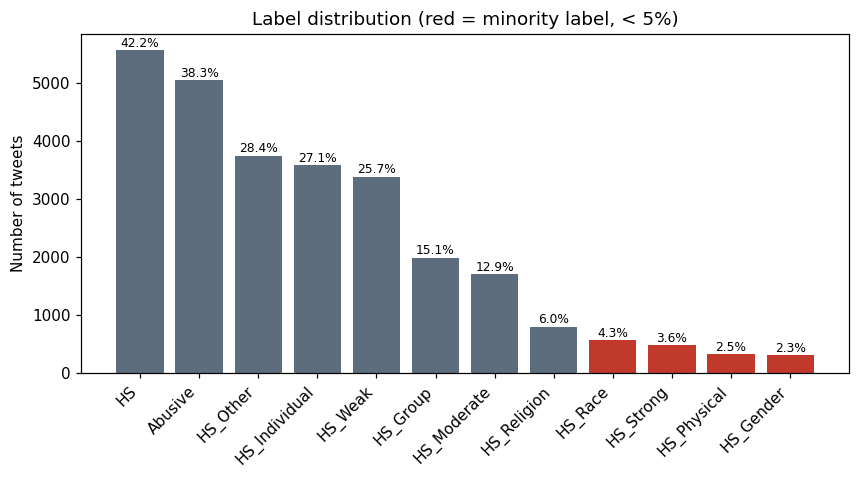

In [145]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = [
    "#c0392b" if is_minority else "#5d6d7e" for is_minority in label_counts["minority_lt_5pct"]
]
ax.bar(label_counts["label"], label_counts["count"], color=colors)
for position, (count, percent) in enumerate(zip(label_counts["count"], label_counts["percent"])):
    ax.text(position, count + 60, f"{percent:.1f}%", ha="center", fontsize=8)
ax.set_ylabel("Number of tweets")
ax.set_title("Label distribution (red = minority label, < 5%)")
plt.xticks(rotation=45, ha="right")
fig.savefig(FIG / "eda_label_distribution.png")
plt.show()

## Label Cardinality and Label Sets

Label cardinality is the mean number of labels per tweet, and label density divides it by the number of labels.

### Count Labels per Tweet

In [146]:
labels_per_tweet = Y_raw.sum(axis=1)
cardinality = labels_per_tweet.mean()
labelsets = pd.Series(["".join(map(str, row)) for row in Y_raw])
cardinality_summary = pd.DataFrame(
    {
        "metric": [
            "n_tweets",
            "label_cardinality",
            "label_density",
            "n_unique_labelsets",
            "n_labelsets_seen_once",
        ],
        "value": [
            len(raw),
            round(cardinality, 3),
            round(cardinality / Y_raw.shape[1], 3),
            labelsets.nunique(),
            int((labelsets.value_counts() == 1).sum()),
        ],
    }
)
tweets_by_n_labels = (
    pd.Series(labels_per_tweet)
    .value_counts()
    .sort_index()
    .rename_axis("n_labels")
    .reset_index(name="n_tweets")
)

### Cardinality and Label Sets

In [147]:
cardinality_summary

,metric,value
0,n_tweets,13169.000
1,label_cardinality,2.085
2,label_density,0.174
3,n_unique_labelsets,57.000
4,n_labelsets_seen_once,13.000


### Tweets by Number of Labels

In [148]:
tweets_by_n_labels

,n_labels,n_tweets
0,0,5860
1,1,1748
2,4,2208
3,5,3251
4,6,95
5,7,7


## Hierarchy Consistency

The rows that break each annotation rule, and the number of categories of each hate speech tweet.

### Check the Annotation Rules

In [149]:
raw_violations = pd.Series(count_hierarchy_violations(Y_raw)).to_frame("n_rows")
categories_per_hs_tweet = (
    raw[raw.HS == 1][CATEGORY_LABELS]
    .sum(axis=1)
    .value_counts()
    .sort_index()
    .rename_axis("n_categories")
    .to_frame("n_hate_speech_tweets")
)

### Rule Violations

In [150]:
raw_violations

,n_rows
hs0_but_child1,0
hs1_target_not_exactly_one,0
hs1_level_not_exactly_one,0
hs1_no_category,0
other_with_specific,0
any_violation_rows,0


### Categories per Hate Speech Tweet

In [151]:
categories_per_hs_tweet

,n_hate_speech_tweets
n_categories,
1,5401
2,153
3,7


# Preprocessing and Deduplication

The preprocessing for the classical models is applied without stemming and without stopword removal, and duplicates are removed.

## Apply Preprocessing

Every tweet is cleaned and normalised. Five examples are shown with abusive words masked.

### Clean and Normalise

In [152]:
preprocess = build_preprocessor(slang_dict)
raw["text_clean"] = raw.Tweet.map(preprocess)
example_idx = raw.sample(5, random_state=RANDOM_STATE).index
preprocessing_examples = pd.DataFrame(
    {
        "original": raw.loc[example_idx, "Tweet"],
        "cleaned": raw.loc[example_idx, "Tweet"].map(clean_text),
        "normalized": raw.loc[example_idx, "text_clean"],
    }
).apply(lambda column: column.map(lambda text: mask_abusive_words(text, abusive_lexicon)))

### Preprocessing Examples

In [153]:
preprocessing_examples

,original,cleaned,normalized
4847,Usir Dubes Myanmar dr Negri ini. Ksh peringatan ummat Budha di neg kita agar mrk menghimbau utk menghentikan penyiks...,usir dubes myanmar dr negri ini ksh peringatan ummat budha di neg kita agar mrk menghimbau utk menghentikan penyiksa...,usir duta besar myanmar dari negeri ini kasih peringatan umat buddha di tawar kita agar mereka mengimbau untuk mengh...
6178,"USER Ancaman bom dari mata s****, juga lucu2an ya... ?\n\n#LUCULUCUAN'",ancaman bom dari mata s***t juga lucu lucuan ya luculucuan,ancaman bom dari mata s***t juga lucu lucuan ya lucu lucuan
4894,Pria Belanda Ini Jadi Mualaf Usai Ikuti Perjalanan Islam Nusantara Oleh NU di Eropa,pria belanda ini jadi mualaf usai ikuti perjalanan islam nusantara oleh nu di eropa,pria belanda ini jadi mualaf usai ikuti perjalanan islam nusantara oleh nu di eropa
5790,USER J****k j*****',j****k j****k,j****k j****k
11539,USER Eh nurull kuliah dimana? Jurusan apa? Ha bahasa mandarin? Berarti kerja sama dong sama k*****s ? Wah masih saud...,eh nurull kuliah dimana jurusan apa ha bahasa mandarin berarti kerja sama dong sama k*****s wah masih saudaraan dong...,eh nurul kuliah dimana jurusan apa apa bahasa mandarin berarti kerja sama dong sama k*****s wah masih bersaudara don...


## Deduplicate and Save

Duplicates are removed and the final data are saved to data/processed/data_clean.csv, which the experiment runner reads. The value rows_final is the dataset size reported in the paper.

### Remove Duplicates and Save

In [154]:
data, dedup_report = deduplicate(raw[["Tweet", "text_clean"] + LABELS])
data.insert(0, "id", np.arange(len(data)))
assert count_hierarchy_violations(label_matrix(data))["any_violation_rows"] == 0
data.to_csv(PROC / "data_clean.csv", index=False)

### Describe the Final Data

The label frequencies, imbalance ratios and label cardinality of the deduplicated data.

In [155]:
Y_final = label_matrix(data)
MEAN_IR_FINAL = mean_ir(Y_final)
final_counts = pd.DataFrame({"label": LABELS, "count": Y_final.sum(axis=0)})
final_counts["percent"] = (final_counts["count"] / len(data) * 100).round(2)
final_counts["IRLbl"] = irlbl(Y_final).round(2)
final_counts["IRLbl_gt_MeanIR"] = final_counts["IRLbl"] > MEAN_IR_FINAL
final_data_summary = pd.DataFrame(
    {
        "MeanIR (final data)": [round(MEAN_IR_FINAL, 2)],
        "label_cardinality": [round(Y_final.sum(axis=1).mean(), 3)],
    }
)

### Deduplication Report

In [156]:
pd.Series(dedup_report).to_frame("value")

,value
rows_raw,13169
rows_empty_after_clean,46
conflicting_texts,39
rows_dropped_conflict,84
rows_dropped_same_label_dup,266
rows_final,12773


### Final Data Summary

In [157]:
final_data_summary

,MeanIR (final data),label_cardinality
0,6.42,2.078


### Final Label Frequency

In [158]:
show_table(final_counts, decimals=2)

,label,count,percent,IRLbl,IRLbl_gt_MeanIR
0,HS,5379,42.11,1.00,False
1,Abusive,4864,38.08,1.11,False
2,HS_Individual,3446,26.98,1.56,False
3,HS_Group,1933,15.13,2.78,False
4,HS_Religion,761,5.96,7.07,True
5,HS_Race,552,4.32,9.74,True
6,HS_Physical,305,2.39,17.64,True
7,HS_Gender,294,2.30,18.30,True
8,HS_Other,3625,28.38,1.48,False
9,HS_Weak,3255,25.48,1.65,False


# Cross-Validation Folds

The folds come from MultilabelStratifiedKFold, the iterative stratification of Sechidis et al. (2011), with five folds, shuffling and random state 42. The file results/folds.json stores row ids rather than positions, so the folds stay valid if the order of the data file changes.

## Create or Load Folds

If folds.json exists it is loaded and no new folds are created. Delete the file only after the team agrees.

### Create or Load the Folds

In [159]:
folds_created = not FOLDS_PATH.exists()
if folds_created:
    ids = data["id"].to_numpy()
    splitter = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    folds = [
        {
            "fold": fold_number,
            "train_ids": ids[train_index].tolist(),
            "test_ids": ids[test_index].tolist(),
        }
        for fold_number, (train_index, test_index) in enumerate(
            splitter.split(np.zeros(len(data)), label_matrix(data))
        )
    ]
    FOLDS_PATH.write_text(json.dumps(folds))
else:
    folds = json.loads(FOLDS_PATH.read_text())

### Check the Folds

Every id must be in exactly one test fold, and training and test ids never overlap. The data and folds are then read back exactly as the experiment runner reads them.

In [160]:
all_test_ids = np.concatenate([fold["test_ids"] for fold in folds])
assert len(all_test_ids) == len(set(all_test_ids)) == len(data)
for fold in folds:
    assert not set(fold["train_ids"]) & set(fold["test_ids"])
    assert len(fold["train_ids"]) + len(fold["test_ids"]) == len(data)
data, folds = load_inputs(ROOT)
Y = label_matrix(data)
fold_sizes = pd.DataFrame(
    [
        {
            "fold": fold["fold"],
            "train_size": len(fold["train_ids"]),
            "test_size": len(fold["test_ids"]),
            "folds_file": "created" if folds_created else "loaded",
        }
        for fold in folds
    ]
)

### Fold Sizes

In [161]:
fold_sizes

,fold,train_size,test_size,folds_file
0,0,10218,2555,loaded
1,1,10218,2555,loaded
2,2,10219,2554,loaded
3,3,10218,2555,loaded
4,4,10219,2554,loaded


## Label Distribution per Fold

Counts each label in each test fold, and how much the share of each label varies across folds, in percentage points.

### Count Labels per Fold

In [162]:
fold_label_rows = []
for fold in folds:
    _, test_rows = fold_rows(data, fold)
    fold_label_rows.append(
        {
            "fold": fold["fold"],
            "n_test": len(test_rows),
            **{
                label: int(Y[test_rows, label_index].sum())
                for label_index, label in enumerate(LABELS)
            },
        }
    )
fold_label_dist = pd.DataFrame(fold_label_rows).set_index("fold")
label_share = fold_label_dist[LABELS].div(fold_label_dist.n_test, axis=0) * 100
label_share_range = (label_share.max() - label_share.min()).round(2).to_frame("range_pp").T

### Label Counts per Fold

In [163]:
fold_label_dist

,n_test,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
fold,,,,,,,,,,,,,
0,2555,1077,973,690,387,152,111,61,59,720,651,333,93
1,2555,1072,972,686,386,152,110,61,59,716,651,328,93
2,2554,1079,973,692,387,153,110,61,59,741,651,334,94
3,2555,1075,973,689,386,152,111,61,59,721,651,331,93
4,2554,1076,973,689,387,152,110,61,58,727,651,331,94


### Range of Label Shares

In [164]:
label_share_range

,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
range_pp,0.29,0.05,0.25,0.05,0.04,0.04,0.0,0.04,0.99,0.01,0.24,0.04


# MLSMOTE Inspection

The original MLSMOTE is compared with MLSMOTE plus hierarchy repair on the training data of fold 0. The features and MLSMOTE are fitted on that training data only.

## Resample Fold 0

Both versions of MLSMOTE are run on the training data of fold 0.

### Build the Features of Fold 0

In [165]:
train_rows_f0, _ = fold_rows(data, folds[0])
texts_f0 = data.text_clean.iloc[train_rows_f0]
X_train_f0 = transform_features(fit_features(texts_f0), texts_f0)
Y_train_f0 = Y[train_rows_f0]

### Run Both Versions

Runs MLSMOTE without and with repair and summarises the synthetic instances of each version.

In [166]:
mlsmote_runs = {}
for name, repair in [("mlsmote_original", False), ("mlsmote_repair", True)]:
    start_time = time.time()
    _, Y_resampled, summary = mlsmote(X_train_f0, Y_train_f0, n_neighbours=5, repair=repair)
    mlsmote_runs[name] = {"seconds": time.time() - start_time, "summary": summary, "Y": Y_resampled}
fold0_summary = pd.DataFrame(
    [
        {
            "training_rows": X_train_f0.shape[0],
            "features": X_train_f0.shape[1],
            "MeanIR (fold 0 training data)": round(
                mlsmote_runs["mlsmote_original"]["summary"]["mean_ir"], 2
            ),
        }
    ]
)
mlsmote_summary = pd.DataFrame(
    {
        name: {
            "seconds": round(run["seconds"], 2),
            "n_train_before": len(train_rows_f0),
            "n_synthetic": run["summary"]["n_synthetic"],
            "n_repaired": run["summary"]["n_repaired"],
            "n_synthetic_violating_hierarchy": count_hierarchy_violations(
                run["Y"][len(train_rows_f0) :]
            )["any_violation_rows"],
            "processed_labels": ", ".join(
                LABELS[label_index] for label_index in run["summary"]["processed_labels"]
            ),
        }
        for name, run in mlsmote_runs.items()
    }
).T

### Fold 0 Training Data

In [167]:
fold0_summary

,training_rows,features,MeanIR (fold 0 training data)
0,10218,5000,6.42


### MLSMOTE Summary

In [168]:
mlsmote_summary

,seconds,n_train_before,n_synthetic,n_repaired,n_synthetic_violating_hierarchy,processed_labels
mlsmote_original,0.64,10218,2062,0,326,"HS_Religion, HS_Race, HS_Physical, HS_Gender, HS_Strong"
mlsmote_repair,0.73,10218,2094,290,0,"HS_Religion, HS_Race, HS_Physical, HS_Gender, HS_Strong"


## Label Counts Before and After

Label counts and imbalance ratios before and after both MLSMOTE versions.

### Count the Labels

In [169]:
original_run, repair_run = mlsmote_runs["mlsmote_original"], mlsmote_runs["mlsmote_repair"]
mlsmote_label_counts = pd.DataFrame(
    [
        {
            "label": label,
            "count_before": int(Y_train_f0[:, label_index].sum()),
            "count_original": int(original_run["Y"][:, label_index].sum()),
            "count_repair": int(repair_run["Y"][:, label_index].sum()),
            "IRLbl_before": round(original_run["summary"]["irlbl_before"][label_index], 2),
            "IRLbl_original": round(original_run["summary"]["irlbl_after"][label_index], 2),
            "IRLbl_repair": round(repair_run["summary"]["irlbl_after"][label_index], 2),
        }
        for label_index, label in enumerate(LABELS)
    ]
)

### Label Counts

In [170]:
mlsmote_label_counts

,label,count_before,count_original,count_repair,IRLbl_before,IRLbl_original,IRLbl_repair
0,HS,4302,6364,6396,1.00,1.00,1.00
1,Abusive,3891,4796,4794,1.11,1.33,1.33
2,HS_Individual,2756,3508,3603,1.56,1.81,1.78
3,HS_Group,1546,2646,2793,2.78,2.41,2.29
4,HS_Religion,609,1502,1510,7.06,4.24,4.24
5,HS_Race,441,1173,1255,9.76,5.43,5.10
6,HS_Physical,244,545,545,17.63,11.68,11.74
7,HS_Gender,235,490,490,18.31,12.99,13.05
8,HS_Other,2905,3069,3070,1.48,2.07,2.08
9,HS_Weak,2604,3251,3356,1.65,1.96,1.91


### Minority Labels Chart

The minority labels before and after MLSMOTE with repair.

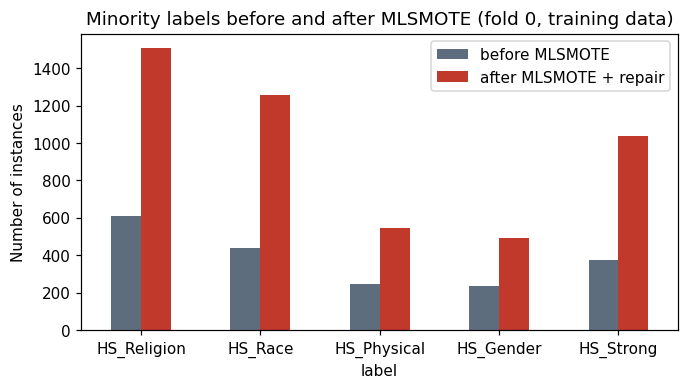

In [171]:
to_plot = mlsmote_label_counts.set_index("label").loc[
    MINORITY_LABELS, ["count_before", "count_repair"]
]
to_plot.columns = ["before MLSMOTE", "after MLSMOTE + repair"]
ax = to_plot.plot.bar(figsize=(7, 3.5), color=["#5d6d7e", "#c0392b"])
ax.set_title("Minority labels before and after MLSMOTE (fold 0, training data)")
ax.set_ylabel("Number of instances")
plt.xticks(rotation=0)
plt.savefig(FIG / "mlsmote_fold0_before_after.png")
plt.show()

## Design Decision

One pass of MLSMOTE, as in the paper, adds one synthetic instance per minority instance per label. The imbalance ratio drops, but labels such as HS_Gender remain minority labels. This is the behaviour of the original algorithm, not a bug.

In the original version, some synthetic instances break the label hierarchy, as shown in the column n_synthetic_violating_hierarchy. The main grid therefore uses the repair version, and the original version is evaluated in the repair ablation. Claims about MLSMOTE in the paper refer to MLSMOTE with hierarchy repair, and to the original algorithm only through that ablation.

# Classical Model Grid

The grid crosses four algorithms, namely Complement Naive Bayes, LinearSVC, XGBoost and the MLP, with two multi-label strategies, Binary Relevance and Classifier Chains. Label Powerset is run only for the baseline comparison, with Complement Naive Bayes, LinearSVC and the random forest.

The imbalance treatments are none, class weighting and MLSMOTE with hierarchy repair. The original MLSMOTE without repair is run as an ablation. Every configuration is run in the fixed and full tuning modes on five folds of iterative stratification with seed 42. Complement Naive Bayes and LinearSVC also run in the thresholds-only mode, which separates threshold tuning from the hyperparameter search. This gives 325 runs. XGBoost and the MLP run only when RUN_GPU_MODELS is true, and their stored results are used otherwise.

## Build the Grid

The runs of the main experiment, the fixed hyperparameters and the tuning candidates.

### Main Grid

In [172]:
CLASSICAL_ALGOS = ["cnb", "svm"] + (["xgb", "mlp"] if RUN_GPU_MODELS else [])
main_grid = build_grid(
    CLASSICAL_ALGOS, ["br", "cc"], ["none", "weight", "mlsmote"], tuning=("fixed", "tuned")
)
main_grid += build_grid(
    [algo for algo in CLASSICAL_ALGOS if algo in THRESHOLD_ONLY_ALGOS],
    ["br", "cc"],
    ["none", "weight", "mlsmote"],
    tuning=("thr",),
)
main_grid += build_grid(["cnb", "svm", "rf"], ["lp"], ["none"])
main_grid += build_grid(["cnb", "svm"], ["br"], ["mlsmote_raw"])

### Runs per Algorithm and Tuning Mode

In [173]:
(
    pd.DataFrame(main_grid, columns=["algo", "strategy", "condition", "tuning", "features", "fold"])
    .groupby(["algo", "tuning"])
    .size()
    .unstack(fill_value=0)
)

tuning,fixed,thr,tuned
algo,,,
cnb,40,30,30
mlp,30,0,30
rf,5,0,0
svm,40,30,30
xgb,30,0,30


### Fixed Hyperparameters

In [174]:
pd.DataFrame({algo: [params] for algo, params in BASE_PARAMS.items()}).T.rename(
    columns={0: "fixed hyperparameters"}
)

,fixed hyperparameters
cnb,{'alpha': 1.0}
svm,"{'C': 1.0, 'max_iter': 5000, 'random_state': 42}"
xgb,"{'n_estimators': 300, 'learning_rate': 0.1, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.5, 'min_child_we..."
mlp,"{'hidden': 256, 'dropout': 0.3, 'lr': 0.001, 'weight_decay': 1e-05, 'batch_size': 128, 'max_epochs': 30, 'patience':..."
rf,"{'n_estimators': 100, 'random_state': 42, 'n_jobs': -1}"


### Tuning Candidates

In [175]:
pd.Series(HYPERPARAMETER_GRID, name="tuning candidates").to_frame()

,tuning candidates
cnb,"[{'alpha': 0.1}, {'alpha': 0.3}, {'alpha': 1.0}]"
svm,"[{'C': 0.1}, {'C': 0.3}, {'C': 1.0}, {'C': 3.0}]"
xgb,"[{'max_depth': 4}, {'max_depth': 6}, {'max_depth': 8}]"
mlp,"[{'hidden': 128}, {'hidden': 256}, {'hidden': 512}]"
rf,[{}]


## Check for Stale Runs

Counts the stale runs and the XGBoost and MLP runs made on another device in both run logs. Stale runs are removed when REMOVE_STALE_RUNS is true and runs from another device when REMOVE_OTHER_DEVICE_RUNS is true, so that the grid runs them again here. Every XGBoost and MLP run records the name of its GPU, so runs made on this machine are never removed and the notebook can be restarted safely after an interruption. Nothing is removed for XGBoost and the MLP when they do not run on this machine.

### Remove Outdated Runs

In [176]:
removal_rows = []
for csv_name, preds_subdir in [(RESULTS_CSV, "preds"), (EXTENDED_CSV, "preds_ext")]:
    path = RES / csv_name
    if not path.exists():
        continue
    runs = pd.read_csv(path)
    stale = runs.index.isin(find_stale_runs(path).index)
    other_device = runs.algo.isin(GPU_ALGOS) & (runs.device != DEVICE_LABEL)
    remove = (REMOVE_STALE_RUNS & stale) | (REMOVE_OTHER_DEVICE_RUNS & other_device)
    if not RUN_GPU_MODELS:
        remove &= ~runs.algo.isin(GPU_ALGOS)
    if remove.any():
        remove_runs(path, runs[remove], preds_subdir)
    removal_rows.append(
        {
            "run_log": csv_name,
            "stale_runs": int(stale.sum()),
            "gpu_runs_from_other_devices": int(other_device.sum()),
            "removed": int(remove.sum()),
        }
    )
removal_summary = pd.DataFrame(removal_rows)

### Removed Runs

In [177]:
removal_summary

,run_log,stale_runs,gpu_runs_from_other_devices,removed
0,experiments.csv,0,0,0
1,experiments_ext.csv,0,0,0


## Run the Grid

Runs that are already in experiments.csv are skipped. This is the longest step of the notebook.

### Run the Main Grid

In [178]:
if RUN_GRID:
    run_grid(
        ROOT,
        main_grid,
        n_jobs_cpu=N_JOBS_CPU,
        csv_name=RESULTS_CSV,
        preds_subdir="preds",
        verbose=False,
    )
main_log = pd.read_csv(RES / RESULTS_CSV)

experiments.csv: 325 runs in grid, 272 done, 53 to run | device: cuda


### Runs in the Log

In [179]:
main_log.groupby("algo").agg(configurations=("config", "nunique"), runs=("config", "size"))

,configurations,runs
algo,,
bert,4,20
cnb,20,100
mlp,12,60
rf,1,5
svm,20,100
xgb,12,60


# Evaluation and Statistical Tests

Every comparison uses the paired permutation test on the out-of-fold predictions and the corrected resampled t-test on the five folds, with the 95 percent interval of the difference in macro F1 and an equivalence test against the margin set in the configuration. The verdicts are explained in the Statistical Tests part. Per-label results are descriptions, not statistical units.

## Load Results

Loads the complete runs of the main grid without the rows of the earlier IndoBERTweet protocol, and both run logs together for the reference configurations. The corrected resampled t-test uses the sizes of the outer training and test folds.

### Evaluation Settings

The columns that identify a configuration, the imbalance treatments of the main grid and the metrics of the main table.

In [180]:
KEY = ["algo", "strategy", "condition", "tuning"]
CONDITIONS_MAIN = ["none", "weight", "mlsmote"]
MAIN_METRICS = [
    "macro_f1",
    "micro_f1",
    "minority_macro_f1",
    "jaccard_acc",
    "hamming_loss",
    "pred_hierarchy_violation_rate",
    "total_time_s",
]

### Load the Runs

In [181]:
results = load_complete_runs(RES / RESULTS_CSV)
results = results[results.algo != "bert"]
all_runs = load_all_runs()
ALGOS = [algo for algo in ["cnb", "svm", "xgb", "mlp"] if algo in results.algo.unique()]
N_TRAIN = int(np.mean([len(fold["train_ids"]) for fold in folds]))
N_TEST = int(np.mean([len(fold["test_ids"]) for fold in folds]))

### Loaded Runs

In [182]:
pd.DataFrame(
    [
        {
            "configurations": results.config.nunique(),
            "runs": len(results),
            "outer_train_size": N_TRAIN,
            "outer_test_size": N_TEST,
        }
    ]
)

,configurations,runs,outer_train_size,outer_test_size
0,65,325,10218,2554


## Main Table

Mean and standard deviation over five folds for every configuration of the main grid, sorted by macro F1.

### Compute Mean and Standard Deviation

In [183]:
grouped = results.groupby(KEY)[MAIN_METRICS]
config_mean, config_std = grouped.mean(), grouped.std()
config_mean_flat = config_mean.reset_index()
main_table = (
    config_mean.round(4).astype(str) + " ± " + config_std.round(4).astype(str)
).reset_index()
main_table["algo"] = main_table.algo.map(ALGO_NAMES)
main_table = main_table.loc[config_mean_flat.macro_f1.sort_values(ascending=False).index]

### Configurations Sorted by Macro F1

In [184]:
show_table(main_table, decimals=None)

,algo,strategy,imbalance_treatment,tuning,macro_f1,micro_f1,minority_macro_f1,jaccard_acc,hamming_loss,pred_hierarchy_violation_rate,total_time_s
39,LinearSVC,br,none,tuned,0.684 ± 0.008,0.7456 ± 0.0081,0.6334 ± 0.0141,0.7153 ± 0.0108,0.0918 ± 0.0031,0.2528 ± 0.0126,9.146 ± 0.2618
48,LinearSVC,cc,none,tuned,0.683 ± 0.0172,0.7454 ± 0.0118,0.6379 ± 0.0248,0.7598 ± 0.01,0.0921 ± 0.0039,0.0258 ± 0.0231,9.326 ± 0.2155
60,XGBoost,cc,mlsmote,tuned,0.6781 ± 0.0131,0.7368 ± 0.0083,0.6393 ± 0.0221,0.7607 ± 0.0085,0.0928 ± 0.0047,0.0262 ± 0.0216,226.414 ± 52.0774
51,LinearSVC,cc,weight,tuned,0.6779 ± 0.0228,0.7458 ± 0.0125,0.6231 ± 0.0354,0.7599 ± 0.0147,0.0921 ± 0.006,0.0289 ± 0.0137,10.03 ± 0.3506
64,XGBoost,cc,weight,tuned,0.6778 ± 0.0173,0.7369 ± 0.0106,0.6349 ± 0.0257,0.7596 ± 0.0119,0.0938 ± 0.0048,0.0456 ± 0.0347,206.24 ± 10.475
45,LinearSVC,cc,mlsmote,tuned,0.6753 ± 0.0155,0.7415 ± 0.01,0.6244 ± 0.0255,0.758 ± 0.0126,0.092 ± 0.0042,0.0188 ± 0.0222,10.756 ± 0.2648
42,LinearSVC,br,weight,tuned,0.6741 ± 0.0078,0.7422 ± 0.0052,0.6109 ± 0.0135,0.7059 ± 0.0037,0.0945 ± 0.0013,0.2745 ± 0.0162,9.65 ± 0.325
47,LinearSVC,cc,none,thr,0.6734 ± 0.0155,0.7378 ± 0.0118,0.6286 ± 0.0191,0.7527 ± 0.0131,0.0932 ± 0.0042,0.0233 ± 0.0146,5.572 ± 0.2317
35,LinearSVC,br,mlsmote,tuned,0.6729 ± 0.0071,0.7381 ± 0.0085,0.6201 ± 0.0133,0.6986 ± 0.0109,0.0946 ± 0.0033,0.2771 ± 0.0176,10.064 ± 0.135
62,XGBoost,cc,none,tuned,0.6723 ± 0.0103,0.735 ± 0.0105,0.6268 ± 0.0077,0.758 ± 0.0121,0.0929 ± 0.0049,0.0165 ± 0.0181,107.05 ± 9.1604


## Imbalance Treatment Chart

Macro F1 and minority macro F1 across imbalance treatments for Binary Relevance, in the three tuning modes.

### Chart Panels

The metric of each row of panels with its title, and the tuning mode of each column.

In [185]:
IMBALANCE_CHART_METRICS = {"macro_f1": "Macro-F1", "minority_macro_f1": "Minority macro-F1"}
IMBALANCE_CHART_TUNINGS = ["fixed", "thr", "tuned"]

### Prepare the Panels

One table of algorithms by imbalance treatment for every metric and tuning mode. Panels without complete runs are left out.

In [186]:
imbalance_panels = {}
for metric, tuning in product(IMBALANCE_CHART_METRICS, IMBALANCE_CHART_TUNINGS):
    subset = config_mean_flat[
        (config_mean_flat.strategy == "br")
        & (config_mean_flat.tuning == tuning)
        & config_mean_flat.condition.isin(CONDITIONS_MAIN)
    ]
    if subset.empty:
        continue
    pivot = subset.pivot(index="algo", columns="condition", values=metric).reindex(
        index=ALGOS, columns=CONDITIONS_MAIN
    )
    pivot.index = pivot.index.map(ALGO_NAMES)
    pivot.columns = [IMBALANCE_NAMES[condition] for condition in pivot.columns]
    imbalance_panels[(metric, tuning)] = pivot

### Bar Chart per Tuning Mode

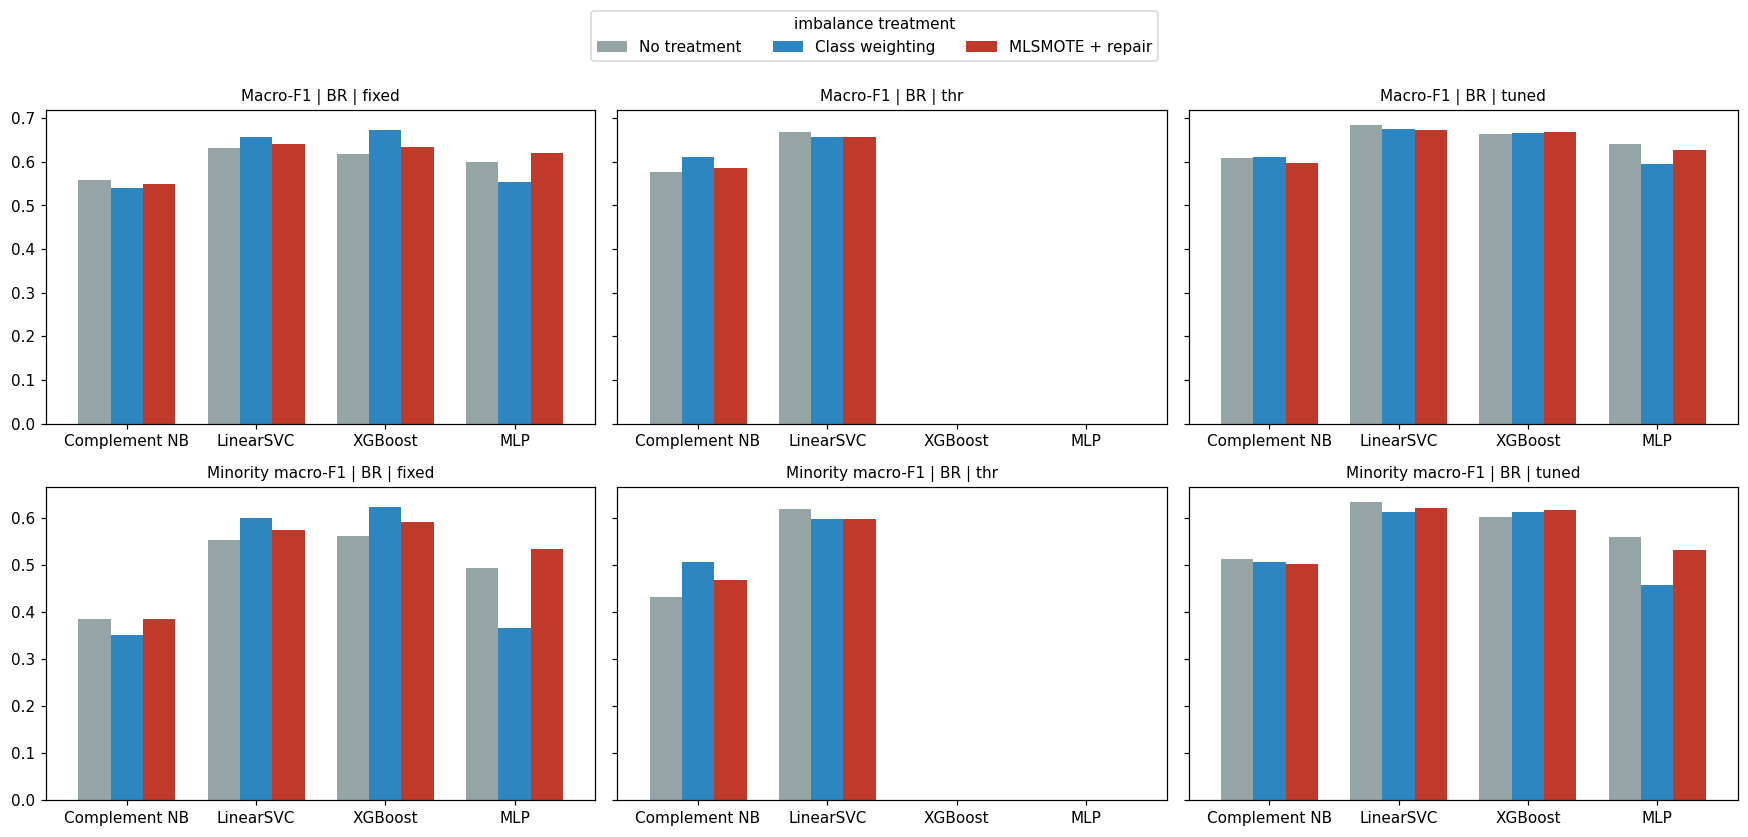

In [187]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharey="row")
for (row, metric), (column, tuning) in product(
    enumerate(IMBALANCE_CHART_METRICS), enumerate(IMBALANCE_CHART_TUNINGS)
):
    ax = axes[row, column]
    if (metric, tuning) not in imbalance_panels:
        ax.set_visible(False)
        continue
    imbalance_panels[(metric, tuning)].plot.bar(
        ax=ax, color=["#95a5a6", "#2e86c1", "#c0392b"], width=0.75, legend=False
    )
    ax.set_title(f"{IMBALANCE_CHART_METRICS[metric]} | BR | {tuning}", fontsize=10)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    legend_labels,
    title="imbalance treatment",
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 1.09),
)
fig.tight_layout()
fig.savefig(FIG / "macro_f1_by_condition.png")
plt.show()

## RQ2 Imbalance Treatment and Tuning

The comparisons are paired within the same algorithm and strategy. The imbalance family compares none with weight, none with mlsmote and weight with mlsmote, all in the fixed mode. The threshold tuning family compares fixed with thr, the hyperparameter tuning family compares thr with tuned, and the full tuning family compares fixed with tuned, for each imbalance treatment. The threshold tuning and hyperparameter tuning families exist for Complement Naive Bayes and LinearSVC, the algorithms that run in the thresholds-only mode.

### Comparison Pairs

Each entry of RQ2_SETTINGS pairs setting A with setting B, as imbalance treatment and tuning mode, and names its family. The pairs repeat every entry for every algorithm and strategy.

In [188]:
RQ2_SETTINGS = (
    [
        ((treatment_a, "fixed"), (treatment_b, "fixed"), "imbalance")
        for treatment_a, treatment_b in [
            ("none", "weight"),
            ("none", "mlsmote"),
            ("weight", "mlsmote"),
        ]
    ]
    + [
        ((condition, "fixed"), (condition, "thr"), "threshold tuning")
        for condition in CONDITIONS_MAIN
    ]
    + [
        ((condition, "thr"), (condition, "tuned"), "hyperparameter tuning")
        for condition in CONDITIONS_MAIN
    ]
    + [((condition, "fixed"), (condition, "tuned"), "full tuning") for condition in CONDITIONS_MAIN]
)
rq2_pairs = [
    {
        "family": family,
        "algo": ALGO_NAMES[algo],
        "strategy": strategy.upper(),
        "A": f"{condition_a}/{tuning_a}",
        "B": f"{condition_b}/{tuning_b}",
        "config_a": config_id(algo, strategy, condition_a, tuning_a),
        "config_b": config_id(algo, strategy, condition_b, tuning_b),
    }
    for algo, strategy, ((condition_a, tuning_a), (condition_b, tuning_b), family) in product(
        ALGOS, ["br", "cc"], RQ2_SETTINGS
    )
]

### Run the Comparisons

Pairs whose configurations are not complete yet are skipped.

In [189]:
rq2 = add_verdicts(compare_configs(rq2_pairs, results, data, N_TRAIN, N_TEST), by="family")

### Verdicts per Family

In [190]:
pd.crosstab(rq2.family, rq2.verdict)

verdict,B better,equivalent,inconclusive
family,,,
full tuning,11,0,13
hyperparameter tuning,4,2,6
imbalance,3,0,21
threshold tuning,6,1,5


### All Comparisons

In [191]:
show_table(rq2.drop(columns=["config_a", "config_b"]))

,family,algo,strategy,A,B,macro_f1_a,macro_f1_b,delta_macro_f1,ci95_low,ci95_high,n_labels_improved,p_permutation,p_corrected_t,p_equivalence,p_permutation_holm,p_corrected_t_holm,p_equivalence_holm,verdict
0,imbalance,Complement NB,BR,none/fixed,weight/fixed,0.5585,0.5399,-0.0185,-0.0339,-0.0032,0,0.0002,0.0284,0.9013,0.0048,0.3125,1.0000,inconclusive
1,imbalance,Complement NB,BR,none/fixed,mlsmote/fixed,0.5585,0.5482,-0.0103,-0.0205,-0.0001,3,0.0002,0.0493,0.5260,0.0048,0.4927,1.0000,inconclusive
2,imbalance,Complement NB,BR,weight/fixed,mlsmote/fixed,0.5399,0.5482,0.0083,0.0019,0.0146,5,0.0002,0.0223,0.2451,0.0048,0.2893,1.0000,inconclusive
3,threshold tuning,Complement NB,BR,none/fixed,none/thr,0.5585,0.5766,0.0181,0.0029,0.0334,6,0.0002,0.0298,0.8937,0.0024,0.1490,1.0000,inconclusive
4,threshold tuning,Complement NB,BR,weight/fixed,weight/thr,0.5399,0.6108,0.0709,0.0520,0.0898,11,0.0002,0.0005,0.9996,0.0024,0.0045,1.0000,B better
5,threshold tuning,Complement NB,BR,mlsmote/fixed,mlsmote/thr,0.5482,0.5847,0.0365,0.0269,0.0460,9,0.0002,0.0005,0.9992,0.0024,0.0045,1.0000,B better
6,hyperparameter tuning,Complement NB,BR,none/thr,none/tuned,0.5766,0.6095,0.0329,0.0242,0.0417,7,0.0002,0.0005,0.9991,0.0024,0.0052,1.0000,B better
7,hyperparameter tuning,Complement NB,BR,weight/thr,weight/tuned,0.6108,0.6108,0.0000,0.0000,0.0000,0,1.0000,1.0000,0.0000,1.0000,1.0000,0.0000,equivalent
8,hyperparameter tuning,Complement NB,BR,mlsmote/thr,mlsmote/tuned,0.5847,0.5981,0.0134,-0.0014,0.0282,8,0.0002,0.0655,0.7213,0.0024,0.3931,1.0000,inconclusive
9,full tuning,Complement NB,BR,none/fixed,none/tuned,0.5585,0.6095,0.0510,0.0401,0.0620,8,0.0002,0.0002,0.9998,0.0048,0.0045,1.0000,B better


### Comparison Chart

Every comparison as a difference in macro F1 with its 95 percent interval, one panel per family.

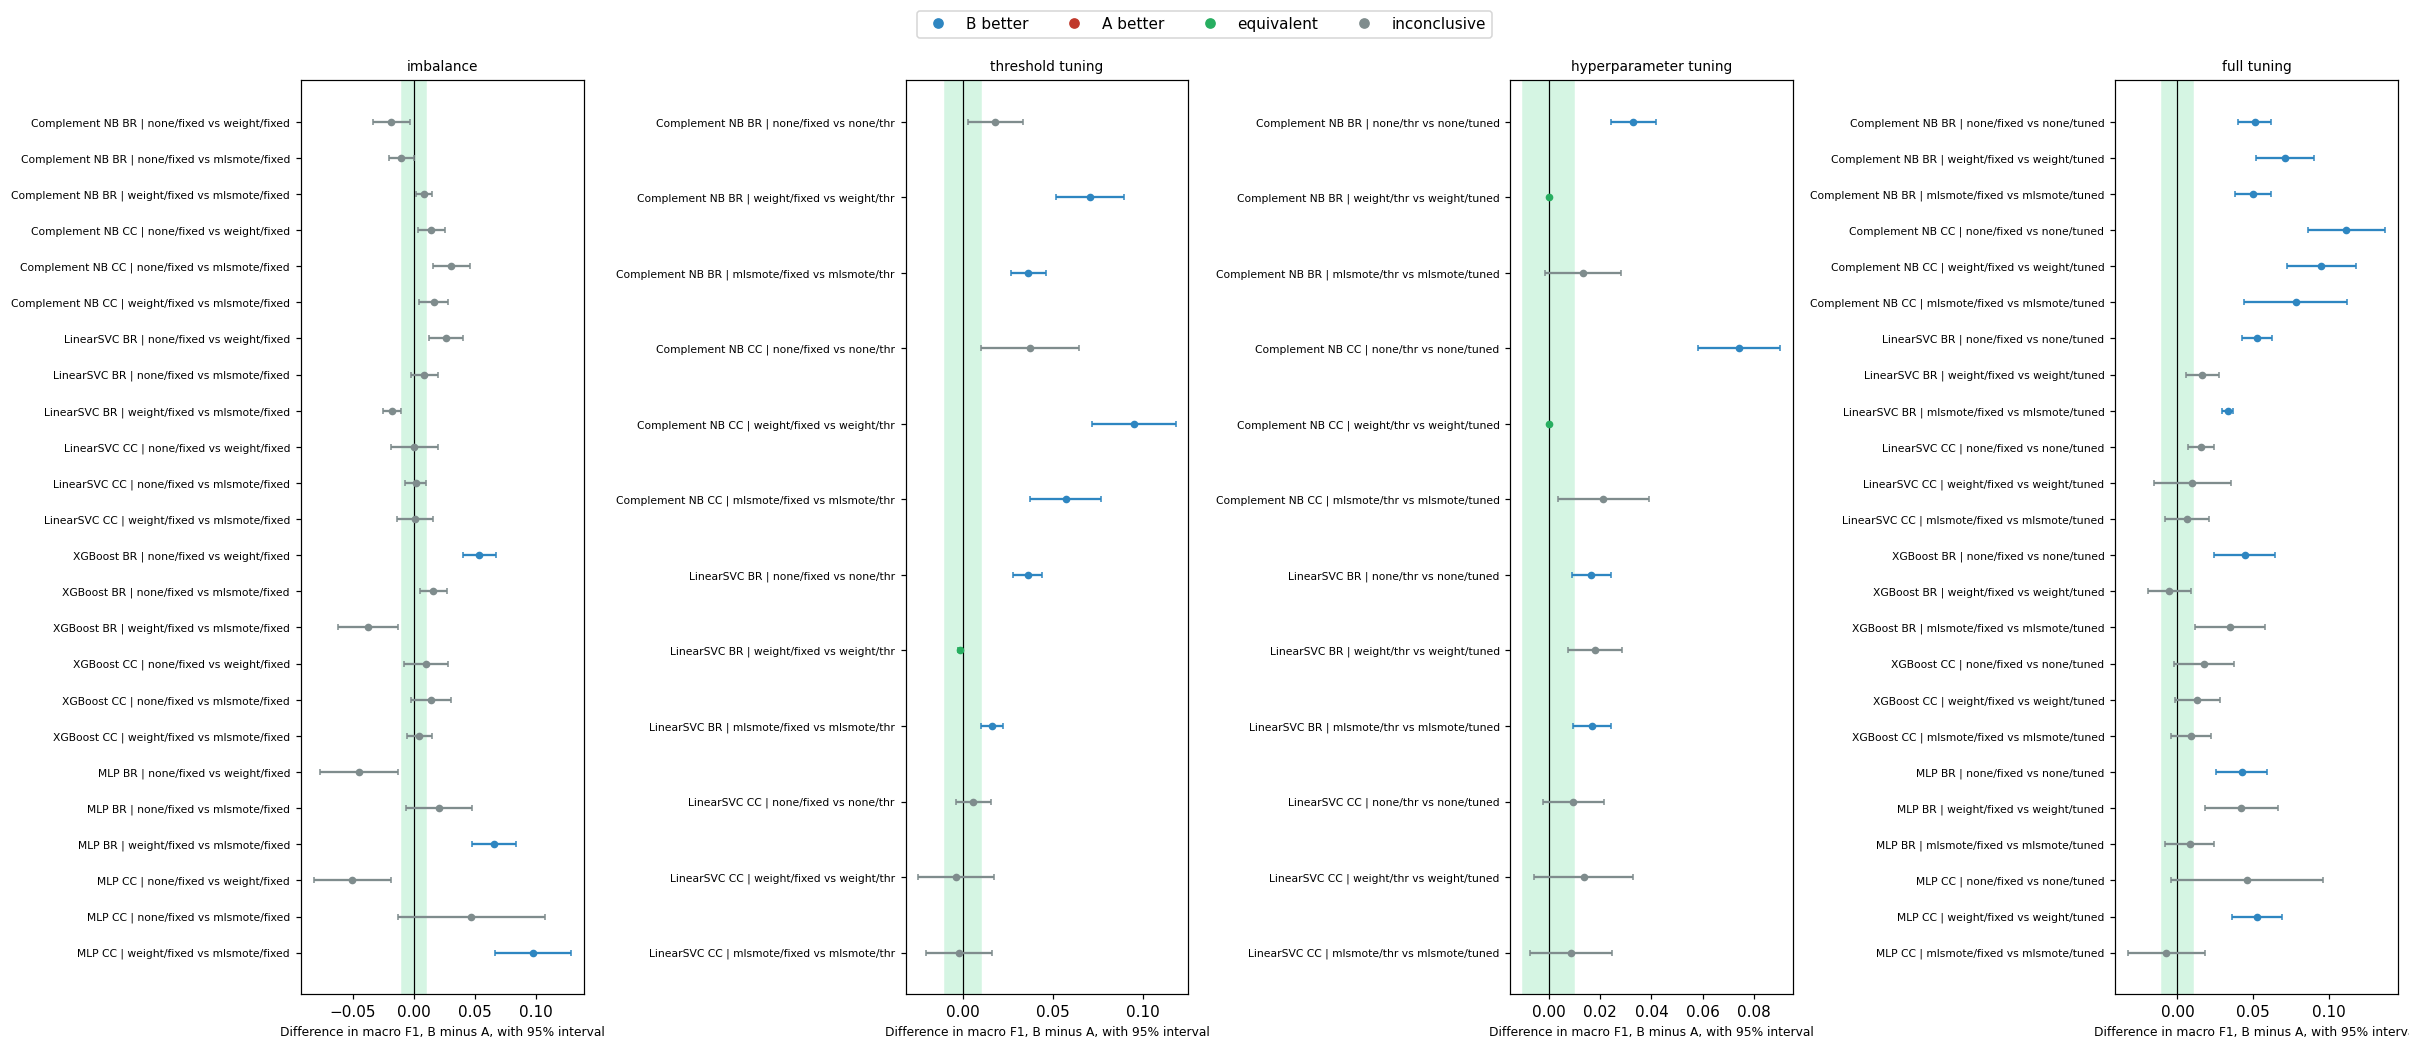

In [192]:
families = list(rq2.family.unique())
fig, axes = plt.subplots(
    1,
    len(families),
    figsize=(5.5 * len(families), 0.3 * rq2.family.value_counts().max() + 2),
    squeeze=False,
)
for ax, family in zip(axes[0], families):
    subset = rq2[rq2.family == family].assign(
        label=lambda table: table.algo + " " + table.strategy + " | " + table.A + " vs " + table.B
    )
    plot_comparisons(subset, "label", family, ax)
handles = [
    plt.Line2D([], [], marker="o", ls="", color=color, label=verdict)
    for verdict, color in VERDICT_COLORS.items()
]
fig.legend(handles=handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
fig.savefig(FIG / "rq2_comparisons.png")
plt.show()

## RQ3 Algorithms Across Settings

Mean macro F1 of the four classical algorithms in every setting of the main grid, with the best algorithm of each setting, and how often each algorithm is best. These tables are descriptive.

### Find the Best Algorithm per Setting

In [193]:
settings = config_mean_flat[
    config_mean_flat.strategy.isin(["br", "cc"]) & config_mean_flat.condition.isin(CONDITIONS_MAIN)
]
algo_by_setting = settings.pivot_table(
    index=["strategy", "condition", "tuning"], columns="algo", values="macro_f1"
)
algo_by_setting = algo_by_setting[
    [algo for algo in ALGOS if algo in algo_by_setting.columns]
].rename(columns=ALGO_NAMES)
algo_by_setting["best"] = algo_by_setting.idxmax(axis=1)
best_counts = (
    algo_by_setting["best"].value_counts().rename_axis("algorithm").to_frame("settings_where_best")
)

### Macro F1 per Setting

In [194]:
show_table(algo_by_setting)

algo                                 Complement NB  LinearSVC  XGBoost     MLP       best
strategy imbalance_treatment tuning                                                      
br       mlsmote             fixed          0.5482     0.6398   0.6344  0.6189  LinearSVC
                             thr            0.5847     0.6560      NaN     NaN  LinearSVC
                             tuned          0.5981     0.6729   0.6693  0.6270  LinearSVC
         none                fixed          0.5585     0.6315   0.6184  0.5984  LinearSVC
                             thr            0.5766     0.6675      NaN     NaN  LinearSVC
                             tuned          0.6095     0.6840   0.6628  0.6407  LinearSVC
         weight              fixed          0.5399     0.6577   0.6721  0.5532    XGBoost
                             thr            0.6108     0.6562      NaN     NaN  LinearSVC
                             tuned          0.6108     0.6741   0.6668  0.5952  LinearSVC
cc       mlsmote             fixed          0.4850     0.6689   0.6692  0.6401    XGBoost
                             thr            0.5420     0.6667      NaN     NaN  LinearSVC
                             tuned          0.5632     0.6753   0.6781  0.6329    XGBoost
         none                fixed          0.4543     0.6676   0.6549  0.5929  LinearSVC
                             thr            0.4916     0.6734      NaN     NaN  LinearSVC
                             tuned          0.5658     0.6830   0.6723  0.6387  LinearSVC
         weight              fixed          0.4687     0.6680   0.6648  0.5424  LinearSVC
                             thr            0.5638     0.6644      NaN     NaN  LinearSVC
                             tuned          0.5638     0.6779   0.6778  0.5948  LinearSVC

### Settings Where Each Algorithm Is Best

In [195]:
show_table(best_counts)

,settings_where_best
algorithm,
LinearSVC,15
XGBoost,3


## RQ3 Reference Comparison

Every pair of reference configurations, fixed in advance, compared with both tests and the Holm-Bonferroni correction over all pairs. This is the confirmatory comparison of the algorithms, including each classical algorithm against IndoBERTweet.

### Compare Every Pair of References

In [196]:
references = reference_models(all_runs, data)
rq3_rows = []
for name_a, name_b in combinations(references, 2):
    (pred_a, folds_a), (pred_b, folds_b) = references[name_a], references[name_b]
    rq3_rows.append(
        {
            "A": name_a,
            "B": name_b,
            **compare_models(Y, pred_a, pred_b, folds_a, folds_b, N_TRAIN, N_TEST),
        }
    )
rq3 = add_verdicts(pd.DataFrame(rq3_rows))

### Reference Comparisons

In [197]:
show_table(rq3)

,A,B,macro_f1_a,macro_f1_b,delta_macro_f1,ci95_low,ci95_high,n_labels_improved,p_permutation,p_corrected_t,p_equivalence,p_permutation_holm,p_corrected_t_holm,p_equivalence_holm,verdict
0,Complement NB,LinearSVC,0.6095,0.6840,0.0745,0.0521,0.0969,12,0.0002,0.0008,0.9993,0.002,0.0038,1.0,B better
1,Complement NB,XGBoost,0.6095,0.6628,0.0533,0.0343,0.0723,12,0.0002,0.0015,0.9984,0.002,0.0059,1.0,B better
2,Complement NB,MLP,0.6095,0.6407,0.0312,0.0143,0.0481,12,0.0002,0.0069,0.9873,0.002,0.0208,1.0,B better
3,Complement NB,IndoBERTweet,0.6095,0.7569,0.1474,0.1177,0.1771,12,0.0002,0.0002,0.9999,0.002,0.0013,1.0,B better
4,LinearSVC,XGBoost,0.6840,0.6628,-0.0212,-0.0362,-0.0062,1,0.0002,0.0172,0.9467,0.002,0.0344,1.0,A better
5,LinearSVC,MLP,0.6840,0.6407,-0.0433,-0.0555,-0.0311,0,0.0002,0.0006,0.9992,0.002,0.0036,1.0,A better
6,LinearSVC,IndoBERTweet,0.6840,0.7569,0.0729,0.0631,0.0827,12,0.0002,0.0000,1.0000,0.002,0.0003,1.0,B better
7,XGBoost,MLP,0.6628,0.6407,-0.0221,-0.0392,-0.0049,3,0.0002,0.0233,0.9388,0.002,0.0344,1.0,A better
8,XGBoost,IndoBERTweet,0.6628,0.7569,0.0941,0.0743,0.1139,12,0.0002,0.0002,0.9999,0.002,0.0013,1.0,B better
9,MLP,IndoBERTweet,0.6407,0.7569,0.1162,0.0980,0.1344,12,0.0002,0.0001,1.0000,0.002,0.0005,1.0,B better


## Reference Summary

Mean macro F1 of every reference configuration over the five folds, with a 95 percent interval that uses the variance correction of Nadeau and Bengio (2003).

### Compute Mean and Interval

In [198]:
reference_summary = pd.DataFrame(
    [
        {
            "model": name,
            "config": REFERENCE_CONFIGS[name],
            "macro_f1": fold_f1.mean(),
            "ci95_half_width": stats.t.ppf(0.975, 4)
            * np.sqrt((1 / 5 + N_TEST / N_TRAIN) * fold_f1.var(ddof=1)),
        }
        for name, (_, fold_f1) in references.items()
    ]
)

### Reference Table

In [199]:
show_table(reference_summary)

,model,config,macro_f1,ci95_half_width
0,Complement NB,cnb__br__none__tuned,0.6095,0.0240
1,LinearSVC,svm__br__none__tuned,0.6840,0.0149
2,XGBoost,xgb__br__none__tuned,0.6628,0.0139
3,MLP,mlp__br__none__tuned,0.6407,0.0235
4,IndoBERTweet,tf__indobertweet_v2__tuned,0.7569,0.0173


### Reference Chart

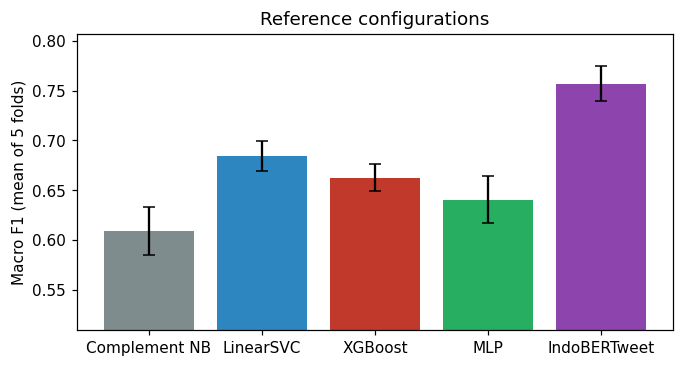

In [200]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(
    reference_summary.model,
    reference_summary.macro_f1,
    yerr=reference_summary.ci95_half_width,
    capsize=4,
    color=[ALGO_COLORS[model] for model in reference_summary.model],
)
ax.set_ylim(
    max(0, reference_summary.macro_f1.min() - 0.1), min(1, reference_summary.macro_f1.max() + 0.05)
)
ax.set_ylabel("Macro F1 (mean of 5 folds)")
ax.set_title("Reference configurations")
fig.savefig(FIG / "reference_macro_f1.png")
plt.show()

## Reference F1 per Label

F1 of each label for every reference configuration. This is descriptive.

### Collect the F1 per Label

In [201]:
reference_f1 = pd.DataFrame(
    {name: per_label_and_folds(all_runs, REFERENCE_CONFIGS[name])[0] for name in references},
    index=LABELS,
).T

### F1 Table

In [202]:
show_table(reference_f1, decimals=3)

,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
Complement NB,0.801,0.837,0.667,0.585,0.545,0.615,0.421,0.354,0.721,0.647,0.494,0.626
LinearSVC,0.827,0.885,0.706,0.631,0.641,0.716,0.532,0.509,0.754,0.682,0.556,0.769
XGBoost,0.813,0.893,0.685,0.615,0.635,0.702,0.494,0.443,0.747,0.661,0.537,0.729
MLP,0.819,0.864,0.696,0.595,0.590,0.683,0.437,0.391,0.743,0.670,0.509,0.692
IndoBERTweet,0.878,0.910,0.786,0.737,0.726,0.779,0.563,0.612,0.817,0.767,0.686,0.821


### F1 Heatmap

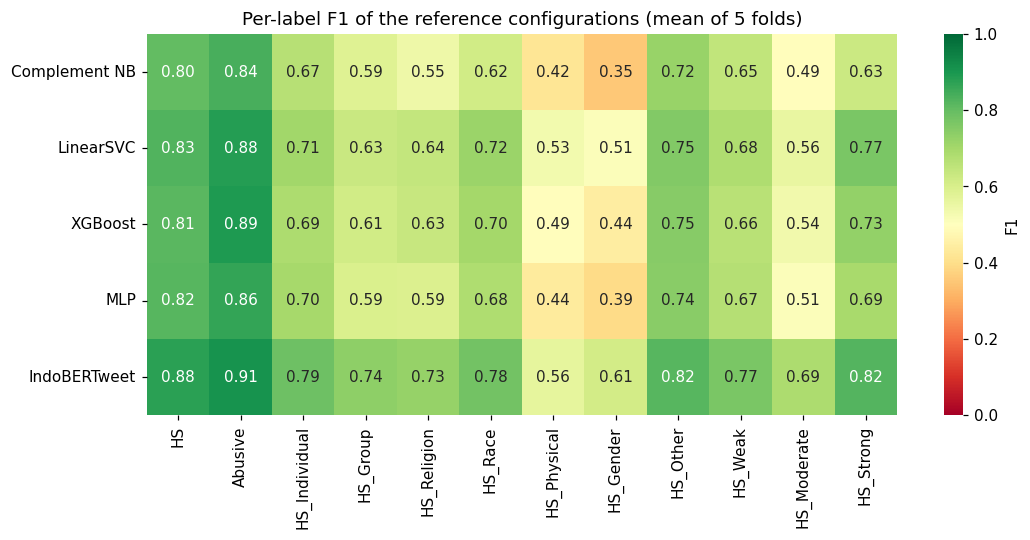

In [203]:
fig, ax = plt.subplots(figsize=(11, 0.6 * len(reference_f1) + 1.5))
sns.heatmap(
    reference_f1,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "F1"},
    ax=ax,
)
ax.set_title("Per-label F1 of the reference configurations (mean of 5 folds)")
fig.savefig(FIG / "reference_f1_per_label.png")
plt.show()

## Baseline Comparison

The baseline of Ibrohim and Budi (2019) uses a random forest with Label Powerset and word unigrams and reaches an accuracy of 66.12 percent on 12 labels with 10 folds. Accuracy in that paper is the Jaccard index per document, their Equation 1. The replication below uses the same folds as every other model here, so it is comparable within this study. The published 66.12 percent comes from a different protocol, with ten folds, no deduplication and unigram features, so the difference to it is descriptive only.

### Published Baseline

In [204]:
BASELINE_JACCARD_PCT = 66.12

### Collect the Label Powerset Results

In [205]:
lp_table = config_mean_flat[config_mean_flat.strategy == "lp"][
    ["algo", "jaccard_acc", "macro_f1", "minority_macro_f1"]
].copy()
lp_table["algo"] = lp_table.algo.map(ALGO_NAMES)
lp_table["diff_vs_published_baseline_pp"] = (
    lp_table.jaccard_acc * 100 - BASELINE_JACCARD_PCT
).round(2)

### Baseline Table

In [206]:
show_table(lp_table)

,algo,jaccard_acc,macro_f1,minority_macro_f1,diff_vs_published_baseline_pp
19,Complement NB,0.7198,0.5778,0.4693,5.86
32,Random Forest,0.7065,0.5099,0.4017,4.53
52,LinearSVC,0.7496,0.6192,0.5429,8.84


## Hierarchy Violations of Predictions

Share of predicted label sets that break the annotation rules, by algorithm and strategy, over all settings of the main grid.

### Compute the Violation Rates

In [207]:
violations = (
    results[results.strategy.isin(["br", "cc"])]
    .groupby(["algo", "strategy"])
    .pred_hierarchy_violation_rate.agg(["mean", "min", "max"])
    .unstack("strategy")
)
violations.index = violations.index.map(ALGO_NAMES)

### Violation Table

In [208]:
show_table(violations)

mean             min             max        
strategy           br      cc      br      cc      br      cc
algo                                                         
Complement NB  0.3665  0.1786  0.2642  0.0646  0.5164  0.7143
MLP            0.3228  0.0228  0.2286  0.0000  0.4775  0.0951
LinearSVC      0.2758  0.0155  0.2231  0.0000  0.3370  0.0579
XGBoost        0.2729  0.0148  0.2090  0.0000  0.3209  0.0912

## MLSMOTE Repair Ablation

The original MLSMOTE against MLSMOTE with hierarchy repair, for Complement Naive Bayes and LinearSVC with Binary Relevance.

### Average the Scores

In [209]:
ablation = results[
    (results.strategy == "br")
    & (results.tuning == "fixed")
    & results.condition.isin(["mlsmote", "mlsmote_raw"])
    & results.algo.isin(["cnb", "svm"])
]
ablation = ablation.groupby(["algo", "condition"])[
    [
        "macro_f1",
        "minority_macro_f1",
        "jaccard_acc",
        "pred_hierarchy_violation_rate",
        "n_synthetic",
        "n_repaired",
    ]
].mean()

### Ablation Table

In [210]:
show_table(ablation)

macro_f1  minority_macro_f1  jaccard_acc  pred_hierarchy_violation_rate  n_synthetic  n_repaired
algo imbalance_treatment                                                                                                  
cnb  mlsmote                0.5482             0.3838       0.5662                         0.4452       2108.8       335.0
     mlsmote_raw            0.5479             0.3858       0.5646                         0.4416       2072.2         0.0
svm  mlsmote                0.6398             0.5735       0.7115                         0.2582       2108.8       335.0
     mlsmote_raw            0.6367             0.5713       0.7108                         0.2620       2072.2         0.0

## Computation Cost

Training time comes from the run logs and was measured on different machines, so it is descriptive. Prediction time is measured here on one machine for 1,000 tweets, including feature extraction or tokenisation. The final model is an ensemble of four transformers of similar size, so its prediction time is estimated as four times one transformer.

### Collect the Training Cost

In [211]:
training_cost = pd.DataFrame(
    [
        {
            "model": name,
            "config": config,
            "train_time_s": all_runs[all_runs.config == config].train_time_s.mean(),
            "tune_time_s": all_runs[all_runs.config == config].tune_time_s.mean(),
            "device": ", ".join(
                sorted(all_runs[all_runs.config == config].device.dropna().astype(str).unique())
            ),
        }
        for name, config in REFERENCE_CONFIGS.items()
    ]
)

### Time the Predictions

Runs only when RUN_INFERENCE_BENCHMARK is true. The transformer is timed only when the transformers library is installed.

In [212]:
inference_time = None
if RUN_INFERENCE_BENCHMARK:
    inference_rows = [
        {
            "model": ALGO_NAMES[algo],
            "device": DEVICE_LABEL if algo in GPU_ALGOS else "cpu",
            "seconds_per_1000_tweets": time_classical_inference(algo, data, folds),
        }
        for algo in REFERENCE_ALGOS
    ]
    if AutoTokenizer is not None:
        transformer_texts = data.Tweet.iloc[:1000].map(normalize_for_transformer)
        transformer_seconds = time_transformer_inference(
            TRANSFORMER_DEFAULTS["model"], transformer_texts
        )
        inference_rows += [
            {
                "model": "IndoBERTweet",
                "device": DEVICE_LABEL,
                "seconds_per_1000_tweets": transformer_seconds,
            },
            {
                "model": "Final model (4 transformers, estimated)",
                "device": DEVICE_LABEL,
                "seconds_per_1000_tweets": 4 * transformer_seconds,
            },
        ]
    inference_time = pd.DataFrame(inference_rows)

[transformers] You passed `num_labels=12` which is incompatible to the `id2label` map of length `2`.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9240.29it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; 

### Training Cost Table

In [213]:
show_table(training_cost, decimals=2)

,model,config,train_time_s,tune_time_s,device
0,Complement NB,cnb__br__none__tuned,0.02,5.64,cpu
1,LinearSVC,svm__br__none__tuned,0.23,8.02,cpu
2,XGBoost,xgb__br__none__tuned,46.67,112.89,cuda (NVIDIA GeForce RTX 3050 Laptop GPU)
3,MLP,mlp__br__none__tuned,40.05,114.73,cuda (NVIDIA GeForce RTX 3050 Laptop GPU)
4,IndoBERTweet,tf__indobertweet_v2__tuned,436.88,0.00,cuda


### Inference Time

In [214]:
if inference_time is not None:
    show_table(inference_time)

,model,device,seconds_per_1000_tweets
0,Complement NB,cpu,0.0510
1,LinearSVC,cpu,0.0488
2,XGBoost,cuda (NVIDIA GeForce RTX 3050 Laptop GPU),0.2232
3,MLP,cuda (NVIDIA GeForce RTX 3050 Laptop GPU),0.4513
4,IndoBERTweet,cuda (NVIDIA GeForce RTX 3050 Laptop GPU),2.5336
5,"Final model (4 transformers, estimated)",cuda (NVIDIA GeForce RTX 3050 Laptop GPU),10.1344


### Inference Chart

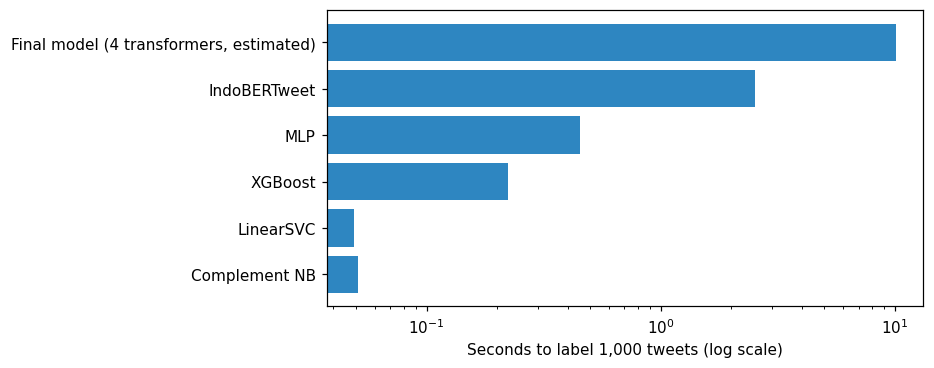

In [215]:
if inference_time is not None:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.barh(inference_time.model, inference_time.seconds_per_1000_tweets, color="#2e86c1")
    ax.set_xscale("log")
    ax.set_xlabel("Seconds to label 1,000 tweets (log scale)")
    fig.savefig(FIG / "inference_time.png")
    plt.show()

# Feature Inspection and Error Analysis

This part lists the most influential LinearSVC features for the minority labels, shows out-of-fold false negatives as examples, and tests whether the models flag non-hateful tweets that mention an identity group more often. Abusive words are masked. The false negatives are examples only, because their causes were not coded by several annotators with a fixed scheme.

## Select Configuration

The LinearSVC reference configuration, fixed in advance.

### Inspected Configuration

In [216]:
INSPECT_CONFIG = REFERENCE_CONFIGS["LinearSVC"]
INSPECT_CONDITION = INSPECT_CONFIG.split("__")[2]

## Most Influential Features

The ten words with the largest LinearSVC coefficients for each minority label, from a model with the fixed hyperparameters trained on the training data of fold 0.

### Train on Fold 0

In [217]:
inspect_vectorizers = fit_features(texts_f0)
X_inspect, Y_inspect = transform_features(inspect_vectorizers, texts_f0), Y[train_rows_f0]
if INSPECT_CONDITION in RESAMPLING_CONDITIONS:
    X_inspect, Y_inspect, _ = resample(X_inspect, Y_inspect, INSPECT_CONDITION)
inspect_models = fit_binary_relevance(
    "svm", X_inspect, Y_inspect, weight=(INSPECT_CONDITION == "weight")
)

### Find the Largest Coefficients

In [218]:
vocabulary = np.array(inspect_vectorizers[0].get_feature_names_out())
top_feature_lists = {}
for label in MINORITY_LABELS:
    coef = inspect_models[LABEL_INDEX[label]].coef_.ravel()
    top = np.argsort(coef)[::-1][:10]
    top_feature_lists[label] = [
        f"{mask_abusive_words(vocabulary[feature], abusive_lexicon)} ({coef[feature]:.2f})"
        for feature in top
    ]
top_features = pd.DataFrame(top_feature_lists)

### Top Features

In [219]:
top_features

,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Strong
0,k***r (3.82),cina (3.97),p***k (3.80),b***i (3.36),bubarkan (4.31)
1,islam (2.84),k*****s (3.57),b***k (2.66),h**o (3.12),lengserkan (3.80)
2,buddha (2.39),myanmar (2.35),i***t (2.61),p***n (2.17),usir (3.65)
3,anti (1.92),usir (1.98),muka (2.39),cabul (2.11),hancurkan (2.18)
4,muslim (1.91),a***g cina (1.94),bolot (2.28),b*****g (2.01),ganyang (2.09)
5,mengaji (1.77),r***m k*****s (1.80),wajahnya (1.77),mesum (1.81),bubarkan saja (1.98)
6,abu janda (1.75),indonesia (1.58),tampang (1.71),p***k (1.63),lengserkan jokowi (1.95)
7,isis (1.70),a***k k*****s (1.54),mukanya (1.67),muka (1.49),turunkan (1.83)
8,zionis (1.67),batak (1.53),c***t (1.64),j****y (1.49),tangkap (1.69)
9,usir (1.66),ganyang (1.50),c****r (1.56),l**t (1.34),ganyang partai (1.68)


## False Negatives

Out-of-fold false negatives of the LinearSVC reference for the minority labels. The counts are complete, and the first ten of a random sample of examples are shown.

### Build the Out-of-Fold Predictions

In [220]:
row_of_id = pd.Series(np.arange(len(data)), index=data["id"])
oof_scores = np.zeros_like(Y, dtype=float)
for fold in range(5):
    test_ids, fold_scores = load_fold_scores(INSPECT_CONFIG, fold)
    oof_scores[row_of_id[test_ids].to_numpy()] = fold_scores
oof_pred = (oof_scores > 0).astype(int)

### Count the Errors

In [221]:
error_counts = pd.DataFrame(
    {
        label: {
            "positives": int(Y[:, LABEL_INDEX[label]].sum()),
            "false_negatives": int(
                ((Y[:, LABEL_INDEX[label]] == 1) & (oof_pred[:, LABEL_INDEX[label]] == 0)).sum()
            ),
            "false_positives": int(
                ((Y[:, LABEL_INDEX[label]] == 0) & (oof_pred[:, LABEL_INDEX[label]] == 1)).sum()
            ),
        }
        for label in MINORITY_LABELS
    }
).T

### Sample False Negatives

Up to ten random false negatives per minority label.

In [222]:
fn_rows, rng_fn = [], np.random.default_rng(RANDOM_STATE)
for label in MINORITY_LABELS:
    label_index = LABEL_INDEX[label]
    false_negatives = np.where((Y[:, label_index] == 1) & (oof_pred[:, label_index] == 0))[0]
    for row in rng_fn.choice(false_negatives, size=min(10, len(false_negatives)), replace=False):
        fn_rows.append(
            {
                "label": label,
                "id": int(data.id.iloc[row]),
                "score": round(oof_scores[row, label_index], 3),
                "true_labels": ", ".join(name for name, value in zip(LABELS, Y[row]) if value),
                "predicted_labels": ", ".join(
                    name for name, value in zip(LABELS, oof_pred[row]) if value
                )
                or "-",
                "tweet_masked": mask_abusive_words(data.Tweet.iloc[row], abusive_lexicon),
            }
        )
fn_examples = pd.DataFrame(fn_rows)

### Error Counts

In [223]:
error_counts

,positives,false_negatives,false_positives
HS_Religion,761,249,326
HS_Race,552,146,176
HS_Physical,305,130,184
HS_Gender,294,124,210
HS_Strong,467,96,128


### Examples

Only the first ten rows are shown.

In [224]:
show_table(fn_examples, head=10)

,label,id,score,true_labels,predicted_labels,tweet_masked
0,HS_Religion,12502,-0.649,"HS, HS_Individual, HS_Religion, HS_Weak","HS_Individual, HS_Other, HS_Weak",Sejak kepemimpinan jokowi banyak ormas yg tidak akur rakyat juga saling hujat dan menista agama di sosmed
1,HS_Religion,9694,-0.691,"HS, Abusive, HS_Individual, HS_Religion, HS_Weak",-,aku sendiri akui Jesus Kristus tapi aku tidak suka caranya . Bikin org banyak yg percaya padanya hidup miskin dan me...
2,HS_Religion,1121,-0.358,"HS, Abusive, HS_Group, HS_Religion, HS_Gender, HS_Moderate","Abusive, HS_Gender","Sebelum Tentara Saudi Tiba di Suriah, ISIS B***I LARI ke Libya URL URL"
3,HS_Religion,8354,-0.081,"HS, Abusive, HS_Individual, HS_Religion, HS_Race, HS_Weak","HS, Abusive, HS_Individual, HS_Race, HS_Weak",CWE CAKEP TP BEGO.PANTES GK LAKU.SI AHOK CINA BAU TAI.MAKAN BUBUR ENCER.AHOK FAHAM KOMUNIS.MENISTA ISLAM & KRISTEN
4,HS_Religion,5031,-0.522,"HS, HS_Group, HS_Religion, HS_Moderate",-,USER Pembacaan Pancasila dalam setiap upacara tak masalah diganti Syahadat NKRI yang berisi initi dari Pancasila
5,HS_Religion,5003,-0.175,"HS, HS_Group, HS_Religion, HS_Moderate","HS, HS_Individual, HS_Other, HS_Weak",Yusril: Kelompok Islam Tertindas di Era Jokowi.? #Fakta #2019GantiPresiden
6,HS_Religion,8980,-0.374,"HS, HS_Group, HS_Religion, HS_Moderate",-,kristen sdh di tapir2in diharam-haramin !!
7,HS_Religion,1173,-0.091,"HS, HS_Group, HS_Religion, HS_Moderate",-,"USER Jika ada tokoh agama, Lalu berpolitik praktis untuk jabatan2 publik?, Dengan menggunakan identitas keagamaan?. ..."
8,HS_Religion,2221,-0.535,"HS, HS_Group, HS_Religion, HS_Moderate","HS, HS_Group, HS_Moderate",USER Kl k*****s sdh tdk laku dimana2. Isu ini cuma jualan a***k orba saja dan para pendukung penerapan negara islam/...
9,HS_Religion,10771,-0.177,"HS, Abusive, HS_Group, HS_Religion, HS_Moderate","HS, Abusive, HS_Group, HS_Other, HS_Moderate","Begitulah media''yahudi a***k dajjal penjilat klo ga menggoreng issu mereka kelaparan,semangat trs bang jonru...abai..."


## Missed Categories

When a category is missed, the table shows which category was predicted instead and how often HS itself was missed.

### Count the Predictions for Missed Categories

In [225]:
missed_rows = {}
for label in ["HS_Gender", "HS_Physical", "HS_Race", "HS_Religion"]:
    missed = (Y[:, LABEL_INDEX[label]] == 1) & (oof_pred[:, LABEL_INDEX[label]] == 0)
    missed_rows[label] = {
        category: int(oof_pred[missed, LABEL_INDEX[category]].sum()) for category in CATEGORY_LABELS
    } | {
        "not_predicted_HS": int((oof_pred[missed, HS_INDEX] == 0).sum()),
        "total_FN": int(missed.sum()),
    }
category_confusion = pd.DataFrame(missed_rows).T

### Categories Predicted Instead

In [226]:
category_confusion

,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,not_predicted_HS,total_FN
HS_Gender,13,3,5,0,45,40,124
HS_Physical,6,0,0,6,58,37,130
HS_Race,23,0,1,0,47,36,146
HS_Religion,0,19,5,5,82,94,249


## Identity Terms

The identity terms below were written before the bias test was run. They name religious, ethnic and gender groups in neutral words, without slurs, in the cleaned and normalised form of the text. The team should review the list before the first run and must not change it after seeing the results.

### Term Groups

In [227]:
IDENTITY_TERMS = {
    "religion": [
        "islam",
        "muslim",
        "muslimah",
        "kristen",
        "katolik",
        "protestan",
        "nasrani",
        "hindu",
        "buddha",
        "budha",
        "konghucu",
        "yahudi",
    ],
    "ethnicity": [
        "cina",
        "china",
        "tionghoa",
        "arab",
        "jawa",
        "sunda",
        "batak",
        "minang",
        "padang",
        "bugis",
        "madura",
        "papua",
        "betawi",
        "ambon",
        "india",
        "pribumi",
    ],
    "gender": [
        "perempuan",
        "wanita",
        "cewek",
        "pria",
        "cowok",
        "gay",
        "lesbian",
        "lesbi",
        "lgbt",
        "transgender",
    ],
}

### Term List

In [228]:
pd.Series(
    {group: ", ".join(terms) for group, terms in IDENTITY_TERMS.items()}, name="terms"
).to_frame()

,terms
religion,"islam, muslim, muslimah, kristen, katolik, protestan, nasrani, hindu, buddha, budha, konghucu, yahudi"
ethnicity,"cina, china, tionghoa, arab, jawa, sunda, batak, minang, padang, bugis, madura, papua, betawi, ambon, india, pribumi"
gender,"perempuan, wanita, cewek, pria, cowok, gay, lesbian, lesbi, lgbt, transgender"


## Identity Term Bias

Among tweets that are not hate speech, the false positive rate of the HS label is compared between tweets with an identity term and tweets without one, following the unintended bias evaluation of Dixon et al. (2018). Fisher's exact test checks the difference, with the Holm-Bonferroni correction over all rows. A higher rate with identity terms means that the model reacts to the group name itself.

### Find Tweets With Identity Terms

One mask per group of terms, one for any term, and the mask of tweets that are not hate speech.

In [229]:
tokens = data.text_clean.str.split().map(set)
group_masks = {
    group: tokens.map(
        lambda tweet_tokens, terms=frozenset(terms): bool(tweet_tokens & terms)
    ).to_numpy()
    for group, terms in IDENTITY_TERMS.items()
}
group_masks["any identity term"] = np.logical_or.reduce(list(group_masks.values()))
not_hate = Y[:, HS_INDEX] == 0

### Run the Fisher Tests

One test for every reference configuration and group of terms.

In [230]:
bias_rows = []
for (name, (pred, _)), (group, mask) in product(references.items(), group_masks.items()):
    false_positive = (pred[:, HS_INDEX] == 1) & not_hate
    with_term, without_term = not_hate & mask, not_hate & ~mask
    fp_with, fp_without = int(false_positive[with_term].sum()), int(
        false_positive[without_term].sum()
    )
    odds_ratio, p_value = stats.fisher_exact(
        [
            [fp_with, int(with_term.sum()) - fp_with],
            [fp_without, int(without_term.sum()) - fp_without],
        ]
    )
    bias_rows.append(
        {
            "model": name,
            "group": group,
            "non_hate_tweets_with_term": int(with_term.sum()),
            "fpr_with_term": fp_with / max(int(with_term.sum()), 1),
            "fpr_without_term": fp_without / max(int(without_term.sum()), 1),
            "odds_ratio": odds_ratio,
            "p_fisher": p_value,
        }
    )
identity_bias = add_holm_columns(pd.DataFrame(bias_rows), ["p_fisher"])

### Bias Table

In [231]:
show_table(identity_bias)

,model,group,non_hate_tweets_with_term,fpr_with_term,fpr_without_term,odds_ratio,p_fisher,p_fisher_holm
0,Complement NB,religion,893,0.0963,0.1903,0.4535,0.0000,0.0000
1,Complement NB,ethnicity,501,0.1198,0.1832,0.6065,0.0002,0.0016
2,Complement NB,gender,276,0.0616,0.1835,0.2921,0.0000,0.0000
3,Complement NB,any identity term,1535,0.1003,0.1995,0.4474,0.0000,0.0000
4,LinearSVC,religion,893,0.1008,0.1661,0.5626,0.0000,0.0000
5,LinearSVC,ethnicity,501,0.1417,0.1594,0.8705,0.3109,1.0000
6,LinearSVC,gender,276,0.0797,0.1613,0.4504,0.0001,0.0011
7,LinearSVC,any identity term,1535,0.1127,0.1702,0.6194,0.0000,0.0000
8,XGBoost,religion,893,0.0896,0.1572,0.5275,0.0000,0.0000
9,XGBoost,ethnicity,501,0.1417,0.1496,0.9388,0.6966,1.0000


### Bias Chart

The false positive rates for any identity term.

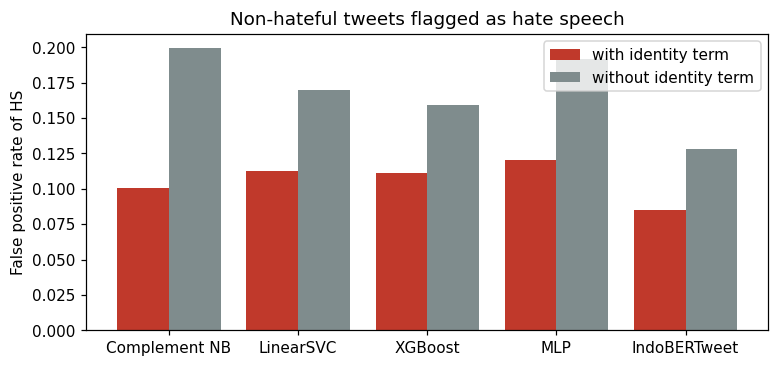

In [232]:
any_term = identity_bias[identity_bias.group == "any identity term"]
positions = np.arange(len(any_term))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(positions - 0.2, any_term.fpr_with_term, 0.4, label="with identity term", color="#c0392b")
ax.bar(
    positions + 0.2, any_term.fpr_without_term, 0.4, label="without identity term", color="#7f8c8d"
)
ax.set_xticks(positions)
ax.set_xticklabels(any_term.model)
ax.set_ylabel("False positive rate of HS")
ax.set_title("Non-hateful tweets flagged as hate speech")
ax.legend()
fig.savefig(FIG / "identity_bias.png")
plt.show()

# Follow-Up Experiments

These experiments answer reviewer style questions and test improvements from the literature. All runs go to results/experiments_ext.csv, with decision scores in results/preds_ext, so the main analysis does not change.

The follow-up experiments ask whether post-processing with the annotation hierarchy improves the predictions without retraining, whether random oversampling with ML-ROS fails like MLSMOTE, whether character n-grams help the classical models, why oversampling fails, and whether the transformer can be improved with epoch selection, another model and ensembles. They end with the choice of the threshold strategy and the final model, and a comparison of the final model with the references.

Every choice of hyperparameters, thresholds, epochs, ensemble thresholds and final configuration uses only the inner validation data of the outer training fold. The transformer configurations were developed step by step after earlier results were seen, so the final model is exploratory, and every configuration that was tried is reported.

## Transformer Settings

The transformer configurations and ensembles of the protocol, keyed by configuration name. An ensemble averages the member probabilities and tunes thresholds on the pooled inner validation data.

### Transformer Configurations

Each configuration overrides some of the protocol defaults.

In [233]:
TRANSFORMER_CONFIGS = {
    "indobertweet_v2": {"model": "indolem/indobertweet-base-uncased"},
    "indobert_p1_v2": {"model": "indobenchmark/indobert-base-p1"},
    "indobertweet_v2_e10": {"model": "indolem/indobertweet-base-uncased", "epochs": 10},
    "indobertweet_v2_s1": {"model": "indolem/indobertweet-base-uncased", "seed": 1},
    "indobertweet_v2_s2": {"model": "indolem/indobertweet-base-uncased", "seed": 2},
    "indobertweet_v2_e10_s1": {
        "model": "indolem/indobertweet-base-uncased",
        "epochs": 10,
        "seed": 1,
    },
    "indobertweet_v2_e10_s2": {
        "model": "indolem/indobertweet-base-uncased",
        "epochs": 10,
        "seed": 2,
    },
    "indobert_p1_v2_e10": {"model": "indobenchmark/indobert-base-p1", "epochs": 10},
}

### Ensembles

The member configurations of each ensemble.

In [234]:
TRANSFORMER_ENSEMBLES = {
    "indobertweet+indobert_p1": ["indobertweet_v2", "indobert_p1_v2"],
    "indobertweet_x3": ["indobertweet_v2", "indobertweet_v2_s1", "indobertweet_v2_s2"],
    "indobertweet_x3+indobert_p1": [
        "indobertweet_v2",
        "indobertweet_v2_s1",
        "indobertweet_v2_s2",
        "indobert_p1_v2",
    ],
    "e10_indobertweet+indobert_p1": ["indobertweet_v2_e10", "indobert_p1_v2_e10"],
    "e10_indobertweet_x3": [
        "indobertweet_v2_e10",
        "indobertweet_v2_e10_s1",
        "indobertweet_v2_e10_s2",
    ],
    "e10_indobertweet_x3+indobert_p1": [
        "indobertweet_v2_e10",
        "indobertweet_v2_e10_s1",
        "indobertweet_v2_e10_s2",
        "indobert_p1_v2_e10",
    ],
}

### Configuration Table

In [235]:
pd.DataFrame(TRANSFORMER_CONFIGS).T.fillna("default")

,model,epochs,seed
indobertweet_v2,indolem/indobertweet-base-uncased,default,default
indobert_p1_v2,indobenchmark/indobert-base-p1,default,default
indobertweet_v2_e10,indolem/indobertweet-base-uncased,10,default
indobertweet_v2_s1,indolem/indobertweet-base-uncased,default,1
indobertweet_v2_s2,indolem/indobertweet-base-uncased,default,2
indobertweet_v2_e10_s1,indolem/indobertweet-base-uncased,10,1
indobertweet_v2_e10_s2,indolem/indobertweet-base-uncased,10,2
indobert_p1_v2_e10,indobenchmark/indobert-base-p1,10,default


### Ensemble Members

In [236]:
pd.Series(
    {name: " + ".join(members) for name, members in TRANSFORMER_ENSEMBLES.items()}, name="members"
).to_frame()

,members
indobertweet+indobert_p1,indobertweet_v2 + indobert_p1_v2
indobertweet_x3,indobertweet_v2 + indobertweet_v2_s1 + indobertweet_v2_s2
indobertweet_x3+indobert_p1,indobertweet_v2 + indobertweet_v2_s1 + indobertweet_v2_s2 + indobert_p1_v2
e10_indobertweet+indobert_p1,indobertweet_v2_e10 + indobert_p1_v2_e10
e10_indobertweet_x3,indobertweet_v2_e10 + indobertweet_v2_e10_s1 + indobertweet_v2_e10_s2
e10_indobertweet_x3+indobert_p1,indobertweet_v2_e10 + indobertweet_v2_e10_s1 + indobertweet_v2_e10_s2 + indobert_p1_v2_e10


## Apply Post-Processing

Applies the rules of the Hierarchy Post-Processing part to every complete Binary Relevance, Classifier Chains and transformer configuration. The reference configurations are also tested against their own predictions without post-processing.

### Post-Process Every Configuration

In [237]:
all_runs = load_all_runs()
all_runs["tuning"] = tuning_label(all_runs)
n_folds = all_runs[all_runs.strategy.isin(["br", "cc", "mo"])].groupby("config").fold.nunique()
postprocessing_rows, reference_test_rows = [], []
for config in n_folds[n_folds == 5].index:
    oof, fold_metrics = postprocess_config(config, data)
    postprocessing_rows.append(
        postprocessing_row(config, all_runs[all_runs.config == config].iloc[0], fold_metrics)
    )
    if config in REFERENCE_CONFIGS.values():
        folds_original = np.array(
            [fold_result["macro_f1"] for fold_result in fold_metrics["original"]]
        )
        folds_topdown = np.array(
            [fold_result["macro_f1"] for fold_result in fold_metrics["topdown"]]
        )
        reference_test_rows.append(
            {
                "A": f"{config} original",
                "B": f"{config} topdown",
                **compare_models(
                    Y,
                    oof["original"],
                    oof["topdown"],
                    folds_original,
                    folds_topdown,
                    N_TRAIN,
                    N_TEST,
                ),
            }
        )
postprocessing = pd.DataFrame(postprocessing_rows)

### Summarise the Results

How many configurations improve, the mean change by algorithm and strategy, and the verdicts of the reference tests.

In [238]:
postprocessing_counts = pd.DataFrame(
    [
        {
            "configurations": len(postprocessing),
            "macro_f1_up_topdown": int((postprocessing.delta_macro__topdown > 0).sum()),
            "jaccard_up_topdown": int((postprocessing.delta_jacc__topdown > 0).sum()),
        }
    ]
)
postprocessing_by_algo = postprocessing.groupby(["algo", "strategy"])[
    ["delta_macro__topdown", "delta_jacc__topdown", "delta_macro__bottomup", "delta_jacc__bottomup"]
].mean()
postprocessing_tests = (
    add_verdicts(pd.DataFrame(reference_test_rows)) if reference_test_rows else None
)

### Configurations That Improve

In [239]:
postprocessing_counts

,configurations,macro_f1_up_topdown,jaccard_up_topdown
0,102,43,99


### Mean Change by Algorithm and Strategy

In [240]:
show_table(postprocessing_by_algo)

delta_macro__topdown  delta_jacc__topdown  delta_macro__bottomup  delta_jacc__bottomup
algo strategy                                                                                        
cnb  br                      0.0315               0.0848                -0.0104                0.0189
     cc                      0.0064               0.0805                -0.0257                0.0048
ens  mo                     -0.0050               0.0063                -0.0046                0.0039
mlp  br                      0.0288               0.0619                 0.0095                0.0251
     cc                     -0.0009               0.0016                -0.0020               -0.0001
svm  br                      0.0083               0.0531                -0.0073                0.0220
     cc                     -0.0014               0.0011                -0.0020                0.0002
tf   mo                     -0.0046               0.0047                -0.0039                0.0031
xgb  br                      0.0096               0.0544                -0.0002                0.0231
     cc                     -0.0045              -0.0002                -0.0047               -0.0004

### Per Configuration

Only the first ten rows, sorted by macro F1 without post-processing, are shown.

In [241]:
show_table(postprocessing.sort_values("macro_f1__original", ascending=False), head=10)

,config,algo,strategy,variant,tuning,macro_f1__original,minority_macro_f1__original,jaccard_acc__original,subset_acc__original,pred_hierarchy_violation_rate__original,macro_f1__topdown,minority_macro_f1__topdown,jaccard_acc__topdown,subset_acc__topdown,pred_hierarchy_violation_rate__topdown,macro_f1__bottomup,minority_macro_f1__bottomup,jaccard_acc__bottomup,subset_acc__bottomup,pred_hierarchy_violation_rate__bottomup,delta_macro__topdown,delta_jacc__topdown,n_labels_improved__topdown,delta_macro__bottomup,delta_jacc__bottomup,n_labels_improved__bottomup
26,ens__e10_indobertweet_x3+indobert_p1,ens,mo,e10_indobertweet_x3+indobert_p1,fixed,0.7775,0.7363,0.8289,0.7449,0.0568,0.7721,0.7291,0.8326,0.7641,0.0,0.7716,0.7292,0.8302,0.7607,0.0,-0.0054,0.0037,1,-0.0059,0.0013,1
29,ens__indobertweet+indobert_p1,ens,mo,indobertweet+indobert_p1,fixed,0.7720,0.7257,0.8292,0.7375,0.0765,0.7641,0.7108,0.8358,0.7667,0.0,0.7686,0.7191,0.8345,0.7641,0.0,-0.0079,0.0066,0,-0.0034,0.0053,2
27,ens__e10_indobertweet_x3+indobert_p1__tuned,ens,mo,e10_indobertweet_x3+indobert_p1,tuned,0.7717,0.7250,0.8244,0.7311,0.0824,0.7702,0.7261,0.8311,0.7592,0.0,0.7672,0.7199,0.8284,0.7550,0.0,-0.0016,0.0066,3,-0.0045,0.0039,3
32,ens__indobertweet_x3+indobert_p1,ens,mo,indobertweet_x3+indobert_p1,fixed,0.7716,0.7227,0.8284,0.7364,0.0694,0.7616,0.7055,0.8320,0.7604,0.0,0.7659,0.7129,0.8316,0.7590,0.0,-0.0100,0.0036,0,-0.0057,0.0032,1
24,ens__e10_indobertweet+indobert_p1__tuned,ens,mo,e10_indobertweet+indobert_p1,tuned,0.7713,0.7249,0.8231,0.7238,0.0992,0.7634,0.7121,0.8329,0.7602,0.0,0.7635,0.7143,0.8276,0.7527,0.0,-0.0079,0.0098,1,-0.0078,0.0045,1
25,ens__e10_indobertweet_x3,ens,mo,e10_indobertweet_x3,fixed,0.7711,0.7274,0.8247,0.7412,0.0511,0.7712,0.7290,0.8295,0.7611,0.0,0.7692,0.7265,0.8267,0.7573,0.0,0.0001,0.0048,5,-0.0019,0.0020,2
23,ens__e10_indobertweet+indobert_p1,ens,mo,e10_indobertweet+indobert_p1,fixed,0.7705,0.7232,0.8268,0.7340,0.0774,0.7631,0.7106,0.8333,0.7627,0.0,0.7657,0.7168,0.8307,0.7590,0.0,-0.0074,0.0065,1,-0.0048,0.0039,3
28,ens__e10_indobertweet_x3__tuned,ens,mo,e10_indobertweet_x3,tuned,0.7697,0.7266,0.8202,0.7242,0.0835,0.7682,0.7226,0.8271,0.7553,0.0,0.7648,0.7163,0.8243,0.7510,0.0,-0.0014,0.0069,5,-0.0049,0.0040,1
30,ens__indobertweet+indobert_p1__tuned,ens,mo,indobertweet+indobert_p1,tuned,0.7676,0.7154,0.8241,0.7216,0.1051,0.7618,0.7063,0.8342,0.7611,0.0,0.7623,0.7093,0.8298,0.7549,0.0,-0.0058,0.0100,3,-0.0053,0.0057,2
33,ens__indobertweet_x3+indobert_p1__tuned,ens,mo,indobertweet_x3+indobert_p1,tuned,0.7651,0.7116,0.8221,0.7244,0.0918,0.7598,0.7018,0.8288,0.7552,0.0,0.7610,0.7046,0.8279,0.7537,0.0,-0.0053,0.0067,1,-0.0041,0.0058,3


### Reference Tests

In [242]:
if postprocessing_tests is not None:
    show_table(postprocessing_tests)

,A,B,macro_f1_a,macro_f1_b,delta_macro_f1,ci95_low,ci95_high,n_labels_improved,p_permutation,p_corrected_t,p_equivalence,p_permutation_holm,p_corrected_t_holm,p_equivalence_holm,verdict
0,cnb__br__none__tuned original,cnb__br__none__tuned topdown,0.6095,0.6112,0.0017,-0.0112,0.0145,6,0.6473,0.7346,0.0733,0.8332,1.0000,0.2932,inconclusive
1,mlp__br__none__tuned original,mlp__br__none__tuned topdown,0.6407,0.6400,-0.0007,-0.0229,0.0214,8,0.2777,0.9311,0.1548,0.8332,1.0000,0.4643,inconclusive
2,svm__br__none__tuned original,svm__br__none__tuned topdown,0.6840,0.6807,-0.0033,-0.0242,0.0177,4,0.3681,0.6874,0.2109,0.8332,1.0000,0.4643,inconclusive
3,tf__indobertweet_v2__tuned original,tf__indobertweet_v2__tuned topdown,0.7569,0.7509,-0.0059,-0.0107,-0.0012,1,0.0002,0.0259,0.0386,0.0010,0.1295,0.1932,inconclusive
4,xgb__br__none__tuned original,xgb__br__none__tuned topdown,0.6628,0.6566,-0.0061,-0.0201,0.0079,6,0.0044,0.2907,0.2431,0.0176,1.0000,0.4643,inconclusive


## ML-ROS and Character Features Grid

ML-ROS clones minority instances up to 20 percent of the training data, close to the share added by MLSMOTE. If both ML-ROS and MLSMOTE fail to help, the conclusion that oversampling does not suit TF-IDF features on this data is stronger and does not depend on the MLSMOTE implementation. Character features and combined word and character features are tested because Ibrohim and Budi (2019) report character features among the best on this data. ML-ROS runs with Complement Naive Bayes and LinearSVC, and character features with LinearSVC, as set in the configuration.

### Extended Grid

In [243]:
extended_grid = build_grid(
    [algo for algo in MLROS_ALGOS if algo in CLASSICAL_ALGOS],
    ["br", "cc"],
    ["mlros"],
    tuning=("fixed", "tuned"),
)
extended_grid += build_grid(
    [algo for algo in CHAR_FEATURE_ALGOS if algo in CLASSICAL_ALGOS],
    ["br", "cc"],
    ["none"],
    tuning=("tuned",),
    features=("char", "wordchar"),
)

### Run the Extended Grid

Runs that are already in experiments_ext.csv are skipped. The run logs are then loaded again with the new runs.

In [244]:
if RUN_EXTENDED_GRID:
    run_grid(
        ROOT,
        extended_grid,
        n_jobs_cpu=N_JOBS_CPU,
        csv_name=EXTENDED_CSV,
        preds_subdir="preds_ext",
        verbose=False,
    )
extended = load_extended()
all_runs = load_all_runs()
complete_configs = {
    config for config, n_done in all_runs.groupby("config").fold.nunique().items() if n_done == 5
}
EXTENDED_ALGOS = [algo for algo in ["cnb", "svm", "xgb", "mlp"] if algo in set(extended.algo)]

experiments_ext.csv: 60 runs in grid, 60 done, 0 to run | device: cuda


### Runs in the Log

In [245]:
extended.groupby("algo").agg(configurations=("config", "nunique"), runs=("config", "size"))

,configurations,runs
algo,,
cnb,4,20
ens,12,60
svm,8,40
tf,16,80


## ML-ROS and Feature Comparisons

ML-ROS against the other imbalance treatments in the same tuning mode, and character features against word features, with both tests and the Holm-Bonferroni correction within each family.

### Comparison Pairs

In [246]:
mlros_pairs = [
    {
        "family": "ML-ROS",
        "algo": ALGO_NAMES[algo],
        "strategy": strategy.upper(),
        "config_a": config_id(algo, strategy, other, tuning),
        "config_b": config_id(algo, strategy, "mlros", tuning),
    }
    for algo, strategy, tuning, other in product(
        EXTENDED_ALGOS, ["br", "cc"], ["fixed", "tuned"], ["none", "mlsmote", "weight"]
    )
]
feature_pairs = [
    {
        "family": "features",
        "algo": ALGO_NAMES[algo],
        "strategy": strategy.upper(),
        "config_a": config_id(algo, strategy, "none", "tuned"),
        "config_b": config_id(algo, strategy, "none", "tuned", features),
    }
    for algo, strategy, features in product(CHAR_FEATURE_ALGOS, ["br", "cc"], ["char", "wordchar"])
]

### Run the Comparisons

Pairs whose configurations are not complete yet are skipped.

In [247]:
extended_comparisons = add_verdicts(
    compare_configs(mlros_pairs + feature_pairs, all_runs, data, N_TRAIN, N_TEST), by="family"
)

### Verdicts per Family

In [248]:
pd.crosstab(extended_comparisons.family, extended_comparisons.verdict)

verdict,equivalent,inconclusive
family,,
ML-ROS,1,23
features,0,4


### All Comparisons

In [249]:
show_table(extended_comparisons)

,family,algo,strategy,config_a,config_b,macro_f1_a,macro_f1_b,delta_macro_f1,ci95_low,ci95_high,n_labels_improved,p_permutation,p_corrected_t,p_equivalence,p_permutation_holm,p_corrected_t_holm,p_equivalence_holm,verdict
0,ML-ROS,Complement NB,BR,cnb__br__none,cnb__br__mlros,0.5585,0.5409,-0.0176,-0.0318,-0.0034,1,0.0002,0.0264,0.8938,0.0048,0.5742,1.0000,inconclusive
1,ML-ROS,Complement NB,BR,cnb__br__mlsmote,cnb__br__mlros,0.5482,0.5409,-0.0073,-0.0150,0.0003,6,0.0002,0.0568,0.1941,0.0048,1.0000,1.0000,inconclusive
2,ML-ROS,Complement NB,BR,cnb__br__weight,cnb__br__mlros,0.5399,0.5409,0.0009,-0.0032,0.0051,5,0.6003,0.5648,0.0019,1.0000,1.0000,0.0455,equivalent
3,ML-ROS,Complement NB,BR,cnb__br__none__tuned,cnb__br__mlros__tuned,0.6095,0.5982,-0.0113,-0.0203,-0.0023,1,0.0002,0.0250,0.6458,0.0048,0.5742,1.0000,inconclusive
4,ML-ROS,Complement NB,BR,cnb__br__mlsmote__tuned,cnb__br__mlros__tuned,0.5981,0.5982,0.0001,-0.0168,0.0170,6,0.7940,0.9836,0.0900,1.0000,1.0000,1.0000,inconclusive
5,ML-ROS,Complement NB,BR,cnb__br__weight__tuned,cnb__br__mlros__tuned,0.6108,0.5982,-0.0126,-0.0289,0.0037,3,0.0002,0.0983,0.6605,0.0048,1.0000,1.0000,inconclusive
6,ML-ROS,Complement NB,CC,cnb__cc__none,cnb__cc__mlros,0.4543,0.4754,0.0211,0.0016,0.0405,5,0.0002,0.0398,0.9050,0.0048,0.7968,1.0000,inconclusive
7,ML-ROS,Complement NB,CC,cnb__cc__mlsmote,cnb__cc__mlros,0.4850,0.4754,-0.0096,-0.0211,0.0019,7,0.0002,0.0807,0.4666,0.0048,1.0000,1.0000,inconclusive
8,ML-ROS,Complement NB,CC,cnb__cc__weight,cnb__cc__mlros,0.4687,0.4754,0.0067,-0.0103,0.0236,6,0.0180,0.3363,0.3066,0.2519,1.0000,1.0000,inconclusive
9,ML-ROS,Complement NB,CC,cnb__cc__none__tuned,cnb__cc__mlros__tuned,0.5658,0.5715,0.0057,-0.0102,0.0216,4,0.0898,0.3780,0.2462,0.7183,1.0000,1.0000,inconclusive


## Minority Precision and Recall

This table tests one explanation of why oversampling does not help, namely that the recall of the minority labels rises while their precision falls further. The values are means over five folds for Binary Relevance with word features, in every tuning mode.

### Collect Precision and Recall per Setting

In [250]:
minority_pr_rows = []
for algo, tuning, condition in product(
    EXTENDED_ALGOS, ["fixed", "thr", "tuned"], ["none", "weight", "mlsmote", "mlros"]
):
    config = config_id(algo, "br", condition, tuning)
    if config not in complete_configs:
        continue
    runs = all_runs[all_runs.config == config]
    row = {"algo": ALGO_NAMES[algo], "tuning": tuning, "condition": condition}
    row |= {f"P_{label}": runs[f"p__{label}"].mean() for label in MINORITY_LABELS}
    row |= {f"R_{label}": runs[f"r__{label}"].mean() for label in MINORITY_LABELS}
    row["P_mean"] = np.mean([row[f"P_{label}"] for label in MINORITY_LABELS])
    row["R_mean"] = np.mean([row[f"R_{label}"] for label in MINORITY_LABELS])
    minority_pr_rows.append(row)
minority_pr = pd.DataFrame(minority_pr_rows)

### Precision and Recall Table

In [251]:
show_table(minority_pr, decimals=3)

,algo,tuning,imbalance_treatment,P_HS_Religion,P_HS_Race,P_HS_Physical,P_HS_Gender,P_HS_Strong,R_HS_Religion,R_HS_Race,R_HS_Physical,R_HS_Gender,R_HS_Strong,P_mean,R_mean
0,Complement NB,fixed,none,0.376,0.372,0.197,0.172,0.346,0.645,0.725,0.357,0.340,0.781,0.293,0.570
1,Complement NB,fixed,weight,0.314,0.311,0.117,0.118,0.296,0.785,0.860,0.711,0.707,0.882,0.231,0.789
2,Complement NB,fixed,mlsmote,0.355,0.360,0.165,0.141,0.322,0.741,0.797,0.584,0.517,0.844,0.268,0.696
3,Complement NB,fixed,mlros,0.345,0.322,0.155,0.140,0.280,0.696,0.799,0.669,0.656,0.871,0.248,0.738
4,Complement NB,thr,none,0.482,0.563,0.256,0.200,0.553,0.549,0.574,0.285,0.292,0.668,0.411,0.474
5,Complement NB,thr,weight,0.548,0.623,0.438,0.357,0.630,0.605,0.585,0.367,0.391,0.597,0.519,0.509
6,Complement NB,thr,mlsmote,0.515,0.588,0.315,0.250,0.563,0.565,0.592,0.397,0.353,0.659,0.446,0.513
7,Complement NB,tuned,none,0.548,0.605,0.432,0.328,0.643,0.584,0.627,0.426,0.414,0.614,0.511,0.533
8,Complement NB,tuned,weight,0.548,0.623,0.438,0.357,0.630,0.605,0.585,0.367,0.391,0.597,0.519,0.509
9,Complement NB,tuned,mlsmote,0.554,0.602,0.509,0.356,0.644,0.550,0.596,0.397,0.390,0.567,0.533,0.500


## Transformer Protocol

Every configuration in TRANSFORMER_CONFIGS is trained with the protocol on the five folds, and the ensembles only use stored probabilities. The final configuration is chosen by inner validation macro F1, not by the test score, and its test score is reported as it is. The preprocessing follows IndoBERTweet (Koto et al., 2021).

### Train and Load

Folds that are already stored are skipped.

In [252]:
if RUN_TRANSFORMERS:
    run_transformer_configs(ROOT, TRANSFORMER_CONFIGS)
    for ensemble_name, members in TRANSFORMER_ENSEMBLES.items():
        ensemble_transformers(ROOT, members, ensemble_name)
extended = load_extended()
transformer_runs = (
    extended[extended.algo.isin(["tf", "ens"])].copy() if len(extended) else pd.DataFrame()
)
HAS_TRANSFORMERS = len(transformer_runs) > 0

skip tf__indobertweet_v2 f0 (already done)
skip tf__indobertweet_v2 f1 (already done)
skip tf__indobertweet_v2 f2 (already done)
skip tf__indobertweet_v2 f3 (already done)
skip tf__indobertweet_v2 f4 (already done)
skip tf__indobert_p1_v2 f0 (already done)
skip tf__indobert_p1_v2 f1 (already done)
skip tf__indobert_p1_v2 f2 (already done)
skip tf__indobert_p1_v2 f3 (already done)
skip tf__indobert_p1_v2 f4 (already done)
skip tf__indobertweet_v2_e10 f0 (already done)
skip tf__indobertweet_v2_e10 f1 (already done)
skip tf__indobertweet_v2_e10 f2 (already done)
skip tf__indobertweet_v2_e10 f3 (already done)
skip tf__indobertweet_v2_e10 f4 (already done)
skip tf__indobertweet_v2_s1 f0 (already done)
skip tf__indobertweet_v2_s1 f1 (already done)
skip tf__indobertweet_v2_s1 f2 (already done)
skip tf__indobertweet_v2_s1 f3 (already done)
skip tf__indobertweet_v2_s1 f4 (already done)
skip tf__indobertweet_v2_s2 f0 (already done)
skip tf__indobertweet_v2_s2 f1 (already done)
skip tf__indobertw

### Stored Transformer Runs

In [253]:
transformer_runs.groupby("algo").agg(configurations=("config", "nunique"), runs=("config", "size"))

,configurations,runs
algo,,
ens,12,60
tf,16,80


## Transformer Summary Table

Every transformer configuration and ensemble with all five folds, and the configuration with the best inner validation macro F1 under tuned thresholds.

### Summarise the Configurations

In [254]:
if HAS_TRANSFORMERS:
    n_folds = transformer_runs.groupby("config").fold.nunique()
    transformer_runs = transformer_runs[transformer_runs.config.isin(n_folds[n_folds == 5].index)]
    columns = [
        "macro_f1",
        "micro_f1",
        "minority_macro_f1",
        "jaccard_acc",
        "inner_macro_f1",
        "train_time_s",
    ]
    transformer_table = transformer_runs.groupby("config")[columns].agg(["mean", "std"])
    transformer_table.columns = [
        f"{metric}_{statistic}" for metric, statistic in transformer_table.columns
    ]
    if "best_epoch" in transformer_runs:
        transformer_table["best_epochs"] = transformer_runs.groupby("config").best_epoch.apply(
            lambda epochs: "/".join(map(str, epochs.astype("Int64")))
        )
    transformer_table = transformer_table.sort_values("macro_f1_mean", ascending=False)
    tuned_runs = transformer_runs[transformer_runs.config.str.endswith("__tuned")]
    picked = tuned_runs[
        tuned_runs.config == tuned_runs.groupby("config").inner_macro_f1.mean().idxmax()
    ]
    best_by_inner = pd.DataFrame(
        [
            {
                "best_by_inner_validation": picked.config.iloc[0],
                "inner_macro_f1": picked.inner_macro_f1.mean(),
                "test_macro_f1": picked.macro_f1.mean(),
                "test_macro_f1_std": picked.macro_f1.std(),
            }
        ]
    )

### All Configurations

In [255]:
if HAS_TRANSFORMERS:
    show_table(transformer_table)

,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,minority_macro_f1_mean,minority_macro_f1_std,jaccard_acc_mean,jaccard_acc_std,inner_macro_f1_mean,inner_macro_f1_std,train_time_s_mean,train_time_s_std,best_epochs
config,,,,,,,,,,,,,
ens__e10_indobertweet_x3+indobert_p1,0.7775,0.0092,0.8248,0.0075,0.7363,0.0124,0.8289,0.0075,0.7931,0.0143,2352.46,242.6304,<NA>/<NA>/<NA>/<NA>/<NA>
ens__indobertweet+indobert_p1,0.7720,0.0109,0.8230,0.0101,0.7257,0.0116,0.8292,0.0085,0.7884,0.0115,903.36,18.4294,<NA>/<NA>/<NA>/<NA>/<NA>
ens__e10_indobertweet_x3+indobert_p1__tuned,0.7717,0.0092,0.8224,0.0069,0.7250,0.0126,0.8244,0.0063,0.7931,0.0143,2352.46,242.6304,<NA>/<NA>/<NA>/<NA>/<NA>
ens__indobertweet_x3+indobert_p1,0.7716,0.0096,0.8233,0.0072,0.7227,0.0145,0.8284,0.0068,0.7842,0.0126,1790.60,16.0565,<NA>/<NA>/<NA>/<NA>/<NA>
ens__e10_indobertweet+indobert_p1__tuned,0.7713,0.0130,0.8223,0.0077,0.7249,0.0206,0.8231,0.0080,0.7931,0.0123,1029.28,95.7942,<NA>/<NA>/<NA>/<NA>/<NA>
ens__e10_indobertweet_x3,0.7711,0.0073,0.8203,0.0076,0.7274,0.0066,0.8247,0.0081,0.7873,0.0131,1921.14,177.8149,<NA>/<NA>/<NA>/<NA>/<NA>
ens__e10_indobertweet+indobert_p1,0.7705,0.0108,0.8222,0.0077,0.7232,0.0169,0.8268,0.0063,0.7931,0.0123,1029.28,95.7942,<NA>/<NA>/<NA>/<NA>/<NA>
ens__e10_indobertweet_x3__tuned,0.7697,0.0085,0.8183,0.0090,0.7266,0.0081,0.8202,0.0113,0.7873,0.0131,1921.14,177.8149,<NA>/<NA>/<NA>/<NA>/<NA>
ens__indobertweet+indobert_p1__tuned,0.7676,0.0107,0.8213,0.0079,0.7154,0.0135,0.8241,0.0075,0.7884,0.0115,903.36,18.4294,<NA>/<NA>/<NA>/<NA>/<NA>


### Best by Inner Validation

In [256]:
if HAS_TRANSFORMERS:
    show_table(best_by_inner)

,best_by_inner_validation,inner_macro_f1,test_macro_f1,test_macro_f1_std
0,ens__e10_indobertweet_x3+indobert_p1__tuned,0.7931,0.7717,0.0092


## Threshold Strategy and Final Model

The strategies and their inner validation estimate are described in the Threshold Strategies part. The configuration and strategy with the highest inner validation estimate become the final model, without retraining.

### Evaluate the Threshold Strategies

Every strategy on every fold of every transformer configuration and ensemble, followed by the choice of the final model.

In [257]:
if HAS_TRANSFORMERS:
    Y_BY_ID = data.set_index("id")[LABELS]
    base_configs = sorted(
        {config.removesuffix("__tuned") for config in transformer_runs.config.unique()}
    )
    threshold_rows, threshold_store = [], {}
    for base, fold in product(base_configs, range(5)):
        evaluation = evaluate_threshold_strategies(
            Y_BY_ID, RES / "preds_ext" / f"{base}__f{fold}.npz", seed=fold
        )
        for strategy, values in evaluation.items():
            threshold_rows.append(
                {
                    "config": base,
                    "fold": fold,
                    "strategy": strategy,
                    "inner_2fold": values["inner_2fold"],
                    "test_macro_f1": values["test_macro_f1"],
                }
            )
            threshold_store[(base, strategy, fold)] = values
    threshold_results = pd.DataFrame(threshold_rows)
    inner_estimate = threshold_results.groupby(["config", "strategy"]).inner_2fold.mean()
    FINAL_CONFIG, FINAL_STRATEGY = inner_estimate.idxmax()

### Predict With the Final Model

The out-of-fold predictions of the final model and its scores on each fold.

In [258]:
if HAS_TRANSFORMERS:
    row_of_id = pd.Series(np.arange(len(data)), index=data["id"])
    final_pred, final_rows = np.zeros_like(Y), []
    for fold in range(5):
        values = threshold_store[(FINAL_CONFIG, FINAL_STRATEGY, fold)]
        rows = row_of_id[values["test_ids"]].to_numpy()
        fold_pred = (values["test_prob"] > values["thresholds"][None, :]).astype(int)
        final_pred[rows] = fold_pred
        final_rows.append({"fold": fold, **evaluate_predictions(Y[rows], fold_pred)})
    final_model_folds = pd.DataFrame(final_rows)
    final_model_summary = pd.DataFrame(
        [
            {
                "final_config": FINAL_CONFIG,
                "threshold_strategy": FINAL_STRATEGY,
                "inner_2fold": inner_estimate.max(),
                "macro_f1": final_model_folds.macro_f1.mean(),
                "macro_f1_std": final_model_folds.macro_f1.std(),
                "minority_macro_f1": final_model_folds.minority_macro_f1.mean(),
                "micro_f1": final_model_folds.micro_f1.mean(),
                "jaccard_acc": final_model_folds.jaccard_acc.mean(),
                "subset_acc": final_model_folds.subset_acc.mean(),
                "hamming_accuracy": 1 - final_model_folds.hamming_loss.mean(),
            }
        ]
    )

### Threshold Strategies

The inner validation estimate and the test macro F1 of every strategy, as means over five folds.

In [259]:
if HAS_TRANSFORMERS:
    show_table(
        threshold_results.groupby(["config", "strategy"])[["inner_2fold", "test_macro_f1"]]
        .mean()
        .unstack("strategy")
    )

inner_2fold                            test_macro_f1                          
strategy                             bootstrap_mean fixed_0.5  shrunk   tuned bootstrap_mean fixed_0.5  shrunk   tuned
config                                                                                                                
ens__e10_indobertweet+indobert_p1            0.7797    0.7827  0.7815  0.7750         0.7724    0.7705  0.7725  0.7713
ens__e10_indobertweet_x3                     0.7765    0.7805  0.7789  0.7749         0.7713    0.7711  0.7719  0.7697
ens__e10_indobertweet_x3+indobert_p1         0.7823    0.7843  0.7842  0.7780         0.7757    0.7775  0.7747  0.7717
ens__indobertweet+indobert_p1                0.7757    0.7816  0.7775  0.7732         0.7699    0.7720  0.7704  0.7676
ens__indobertweet_x3                         0.7656    0.7660  0.7664  0.7617         0.7643    0.7612  0.7647  0.7627
ens__indobertweet_x3+indobert_p1             0.7714    0.7752  0.7744  0.7675         0.7713    0.7716  0.7705  0.7651
tf__indobert_p1_v2                           0.7505    0.7513  0.7512  0.7454         0.7449    0.7442  0.7431  0.7383
tf__indobert_p1_v2_e10                       0.7432    0.7425  0.7425  0.7366         0.7371    0.7311  0.7338  0.7320
tf__indobertweet_v2                          0.7617    0.7606  0.7620  0.7568         0.7569    0.7525  0.7560  0.7569
tf__indobertweet_v2_e10                      0.7718    0.7719  0.7719  0.7660         0.7649    0.7619  0.7631  0.7628
tf__indobertweet_v2_e10_s1                   0.7700    0.7726  0.7709  0.7633         0.7671    0.7634  0.7655  0.7615
tf__indobertweet_v2_e10_s2                   0.7706    0.7688  0.7714  0.7665         0.7639    0.7635  0.7631  0.7619
tf__indobertweet_v2_s1                       0.7627    0.7589  0.7623  0.7570         0.7611    0.7563  0.7594  0.7593
tf__indobertweet_v2_s2                       0.7561    0.7533  0.7556  0.7523         0.7538    0.7497  0.7518  0.7473

### Final Model

In [260]:
if HAS_TRANSFORMERS:
    show_table(final_model_summary)

,final_config,threshold_strategy,inner_2fold,macro_f1,macro_f1_std,minority_macro_f1,micro_f1,jaccard_acc,subset_acc,hamming_accuracy
0,ens__e10_indobertweet_x3+indobert_p1,fixed_0.5,0.7843,0.7775,0.0092,0.7363,0.8248,0.8289,0.7449,0.938


### Final Model per Fold

In [261]:
if HAS_TRANSFORMERS:
    show_table(
        final_model_folds[
            [
                "fold",
                "macro_f1",
                "micro_f1",
                "minority_macro_f1",
                "jaccard_acc",
                "subset_acc",
                "hamming_loss",
            ]
        ]
    )

,fold,macro_f1,micro_f1,minority_macro_f1,jaccard_acc,subset_acc,hamming_loss
0,0,0.7727,0.8196,0.7375,0.8282,0.7440,0.0638
1,1,0.7909,0.8366,0.7488,0.8391,0.7640,0.0576
2,2,0.7813,0.8241,0.7473,0.8247,0.7353,0.0625
3,3,0.7756,0.8263,0.7279,0.8328,0.7503,0.0606
4,4,0.7668,0.8173,0.7198,0.8197,0.7310,0.0654


## Final Model Against the References

The F1 of each label for the final model and every reference configuration, followed by paired tests of the final model against each reference with the Holm-Bonferroni correction.

### Compare With the References

In [262]:
if HAS_TRANSFORMERS:
    final_runs = load_all_runs()
    final_references = reference_models(final_runs, data)
    final_per_label = pd.DataFrame(
        {
            name: per_label_and_folds(final_runs, REFERENCE_CONFIGS[name])[0]
            for name in final_references
        },
        index=LABELS,
    )
    final_per_label["Final model"] = [final_model_folds[f"f1__{label}"].mean() for label in LABELS]
    final_per_label.loc["macro-F1"] = final_per_label.mean()
    folds_final = final_model_folds.sort_values("fold").macro_f1.to_numpy()
    final_comparison = add_verdicts(
        pd.DataFrame(
            [
                {
                    "A": name,
                    "B": "Final model",
                    **compare_models(Y, pred, final_pred, folds, folds_final, N_TRAIN, N_TEST),
                }
                for name, (pred, folds) in final_references.items()
            ]
        )
    )

### F1 per Label

In [263]:
if HAS_TRANSFORMERS:
    show_table(final_per_label, decimals=3)

,Complement NB,LinearSVC,XGBoost,MLP,IndoBERTweet,Final model
HS,0.801,0.827,0.813,0.819,0.878,0.883
Abusive,0.837,0.885,0.893,0.864,0.910,0.925
HS_Individual,0.667,0.706,0.685,0.696,0.786,0.794
HS_Group,0.585,0.631,0.615,0.595,0.737,0.748
HS_Religion,0.545,0.641,0.635,0.590,0.726,0.744
HS_Race,0.615,0.716,0.702,0.683,0.779,0.781
HS_Physical,0.421,0.532,0.494,0.437,0.563,0.641
HS_Gender,0.354,0.509,0.443,0.391,0.612,0.682
HS_Other,0.721,0.754,0.747,0.743,0.817,0.827
HS_Weak,0.647,0.682,0.661,0.670,0.767,0.777


### Tests Against the References

In [264]:
if HAS_TRANSFORMERS:
    show_table(final_comparison)

,A,B,macro_f1_a,macro_f1_b,delta_macro_f1,ci95_low,ci95_high,n_labels_improved,p_permutation,p_corrected_t,p_equivalence,p_permutation_holm,p_corrected_t_holm,p_equivalence_holm,verdict
0,Complement NB,Final model,0.6095,0.7775,0.1679,0.1438,0.1921,12,0.0002,0.0000,1.0000,0.001,0.0001,1.0,B better
1,LinearSVC,Final model,0.6840,0.7775,0.0934,0.0859,0.1010,12,0.0002,0.0000,1.0000,0.001,0.0000,1.0,B better
2,XGBoost,Final model,0.6628,0.7775,0.1147,0.0936,0.1357,12,0.0002,0.0001,0.9999,0.001,0.0002,1.0,B better
3,MLP,Final model,0.6407,0.7775,0.1367,0.1204,0.1531,12,0.0002,0.0000,1.0000,0.001,0.0001,1.0,B better
4,IndoBERTweet,Final model,0.7569,0.7775,0.0206,0.0068,0.0343,12,0.0002,0.0142,0.9501,0.001,0.0142,1.0,B better


# Cross-Corpus Evaluation

The models are trained on all the data of Ibrohim and Budi (2019) and tested on the latest IndoToxic2024 release, IndoDiscourse version 2 by Susanto et al. (2024). It is distributed under the Apache 2.0 licence and downloaded from the HuggingFace dataset Exqrch/IndoDiscourse.

The label mapping is an assumption. HS is mapped to toxicity, which the IndoToxic2024 paper uses as its hate speech task, and to identity_attack, a narrower comparison. Toxicity is a broader construct than hate speech, so this is a transfer to a related construct, and the drop in F1 mixes generalisation with differences in label definitions, platforms, years and prevalence. The F1 of a classifier that always predicts positive shows what F1 the prevalence alone allows. Abusive mapped to profanity_obscenity has a prevalence near 1 percent and a different definition, so it is shown separately and not interpreted.

The models are the four classical reference configurations, with hyperparameters and thresholds from 15 percent inner validation data, plus the transformers, the final model and its comparison ensemble with threshold 0.5.

## Download and Score

Downloads the corpus if it is missing and scores every model on it.

### Download the Corpus

Needs internet access on the first run. The evaluation runs when RUN_CROSS_CORPUS is true, or when it is None and the corpus file exists.

In [265]:
if not CROSS_CORPUS_FILE.exists():
    try:
        from huggingface_hub import hf_hub_download

        CROSS_CORPUS_FILE.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(
            hf_hub_download(
                "Exqrch/IndoDiscourse",
                "indotoxic2024_annotated_data_v2_final.csv",
                repo_type="dataset",
            ),
            CROSS_CORPUS_FILE,
        )
    except Exception as error:
        print("Could not download the 2024 corpus:", repr(error))
if RUN_CROSS_CORPUS is None:
    RUN_CROSS_CORPUS = CROSS_CORPUS_FILE.exists()

### Score Every Model

Trains the four classical references on all the data, which takes several minutes, and reuses the stored transformer probabilities.

In [266]:
if RUN_CROSS_CORPUS:
    corpus_2024, cross_corpus, oov_summary, oov_top = run_cross_corpus(
        ROOT, run_transformers=RUN_TRANSFORMERS
    )
    corpus_summary = pd.DataFrame(
        [
            {
                "texts": len(corpus_2024),
                "toxicity_rate": corpus_2024.toxicity.mean(),
                "identity_attack_rate": corpus_2024.identity_attack.mean(),
                "profanity_rate": corpus_2024.profanity_obscenity.mean(),
            }
        ]
    ).round(3)

### Corpus Summary

The corpus after aggregation of the annotations.

In [267]:
if RUN_CROSS_CORPUS:
    display(corpus_summary)

,texts,toxicity_rate,identity_attack_rate,profanity_rate
0,27076,0.085,0.03,0.01


## In-Domain Comparison

Adds the in-domain F1 of the same label from cross-validation on Ibrohim and Budi and the drop to the 2024 corpus.

### Add the In-Domain F1

In [268]:
if RUN_CROSS_CORPUS:
    cross_runs = load_all_runs()
    cross_corpus["f1_in_domain_cv"] = [
        in_domain_f1(cross_runs, model, label)
        for model, label in zip(cross_corpus.model, cross_corpus.source_label)
    ]
    cross_corpus["f1_drop"] = cross_corpus.f1_in_domain_cv - cross_corpus.f1_pos
    hate_mappings = cross_corpus[cross_corpus.target_label != "profanity_obscenity"]
    profanity_mapping = cross_corpus[cross_corpus.target_label == "profanity_obscenity"]

### Hate Speech Mappings

In [269]:
if RUN_CROSS_CORPUS:
    show_table(hate_mappings)

,model,source_label,target_label,f1_pos,f1_ci95_low,f1_ci95_high,precision,recall,average_precision,prevalence,f1_always_positive,predicted_positive_rate,n,f1_in_domain_cv,f1_drop
0,cnb__br__none__word__tuned,HS,toxicity,0.2350,0.2201,0.2495,0.1873,0.3155,0.1722,0.0850,0.1567,0.1432,25243,0.8012,0.5661
1,cnb__br__none__word__tuned,HS,identity_attack,0.0948,0.0833,0.1062,0.0572,0.2766,0.0520,0.0299,0.0581,0.1447,26107,0.8012,0.7064
3,svm__br__none__word__tuned,HS,toxicity,0.2100,0.1952,0.2244,0.1702,0.2740,0.1555,0.0850,0.1567,0.1369,25243,0.8268,0.6168
4,svm__br__none__word__tuned,HS,identity_attack,0.0752,0.0646,0.0859,0.0457,0.2113,0.0432,0.0299,0.0581,0.1382,26107,0.8268,0.7516
6,xgb__br__none__word__tuned,HS,toxicity,0.1844,0.1718,0.1963,0.1352,0.2898,0.1328,0.0850,0.1567,0.1822,25243,0.8128,0.6284
7,xgb__br__none__word__tuned,HS,identity_attack,0.0646,0.0554,0.0739,0.0375,0.2305,0.0380,0.0299,0.0581,0.1837,26107,0.8128,0.7482
9,mlp__br__none__word__tuned,HS,toxicity,0.2154,0.2019,0.2283,0.1595,0.3318,0.1567,0.0850,0.1567,0.1769,25243,0.8190,0.6036
10,mlp__br__none__word__tuned,HS,identity_attack,0.0773,0.0676,0.0874,0.0451,0.2689,0.0441,0.0299,0.0581,0.1782,26107,0.8190,0.7417
12,tf__indobertweet_v2 (threshold 0.5),HS,toxicity,0.3936,0.3758,0.4115,0.3568,0.4390,0.3119,0.0850,0.1567,0.1046,25243,0.8785,0.4849
13,tf__indobertweet_v2 (threshold 0.5),HS,identity_attack,0.1647,0.1489,0.1804,0.1048,0.3841,0.0857,0.0299,0.0581,0.1096,26107,0.8785,0.7138


### Profanity Mapping

This mapping is not interpreted, so only the first five rows are shown.

In [270]:
if RUN_CROSS_CORPUS:
    show_table(profanity_mapping, head=5)

,model,source_label,target_label,f1_pos,f1_ci95_low,f1_ci95_high,precision,recall,average_precision,prevalence,f1_always_positive,predicted_positive_rate,n,f1_in_domain_cv,f1_drop
2,cnb__br__none__word__tuned,Abusive,profanity_obscenity,0.0721,0.0623,0.0824,0.0381,0.6769,0.1141,0.0097,0.0193,0.1732,26673,0.8367,0.7646
5,svm__br__none__word__tuned,Abusive,profanity_obscenity,0.0905,0.0782,0.1026,0.0483,0.7269,0.1527,0.0097,0.0193,0.1469,26673,0.8846,0.7941
8,xgb__br__none__word__tuned,Abusive,profanity_obscenity,0.1232,0.1077,0.1389,0.0670,0.7654,0.2074,0.0097,0.0193,0.1113,26673,0.8926,0.7694
11,mlp__br__none__word__tuned,Abusive,profanity_obscenity,0.0795,0.0691,0.0898,0.0419,0.7692,0.1840,0.0097,0.0193,0.1789,26673,0.8639,0.7844
14,tf__indobertweet_v2 (threshold 0.5),Abusive,profanity_obscenity,0.0947,0.0830,0.1057,0.0501,0.8500,0.1278,0.0097,0.0193,0.1653,26673,0.9125,0.8178


### Vocabulary Overlap

In [271]:
if RUN_CROSS_CORPUS:
    display(pd.DataFrame([oov_summary]).round(3))

,oov_token_rate,oov_type_rate,n_token
0,0.158,0.8,1176810


### Most Frequent Unknown Words

Only the first fifteen rows are shown.

In [272]:
if RUN_CROSS_CORPUS:
    show_table(oov_top, head=15)

,token,frequency
0,hamas,2700
1,gibran,625
2,netanyahu,589
3,unhcr,565
4,odgj,460
5,prize,383
6,gencatan,367
7,taipei,322
8,penampungan,295
9,biden,292


## Cross-Corpus Chart

F1 of the positive class on IndoToxic2024 with its 95 percent bootstrap interval, for the two hate speech mappings. The dashed line is the F1 of a classifier that always predicts positive.

### F1 With Bootstrap Intervals

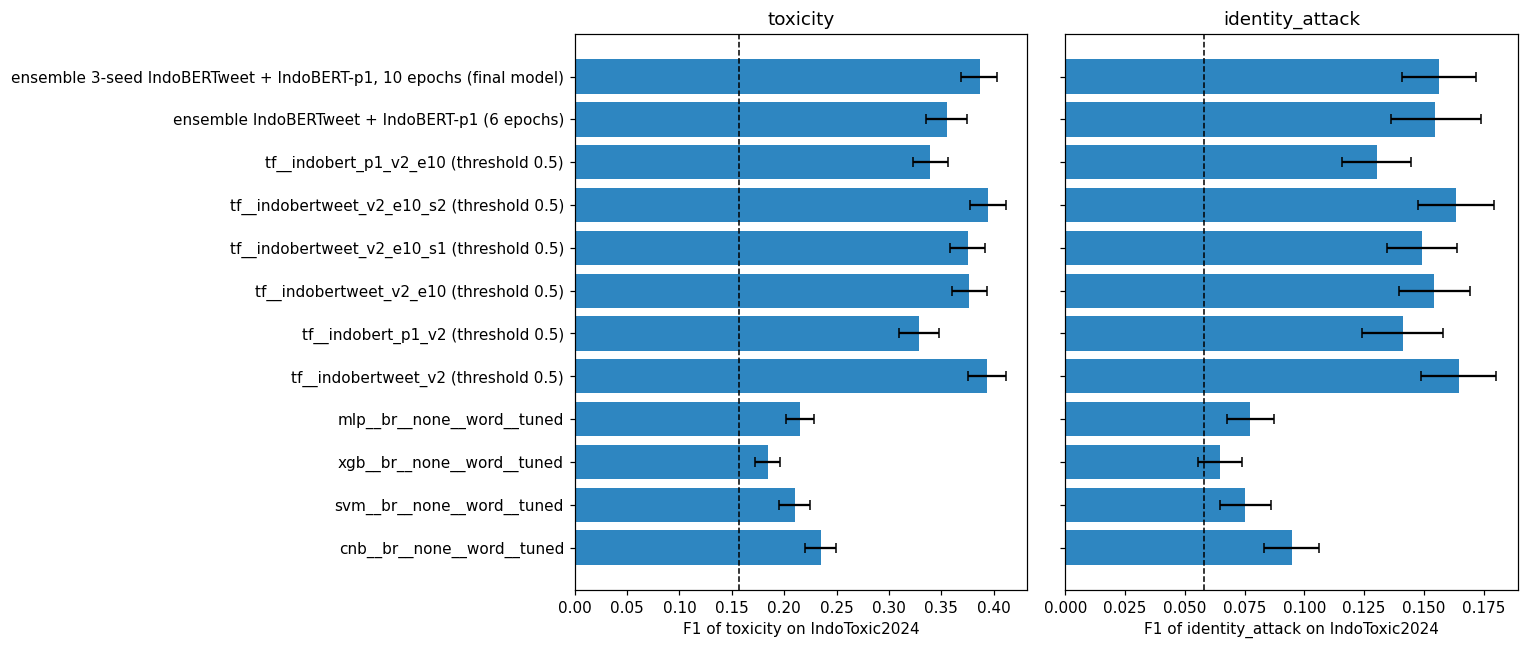

In [273]:
if RUN_CROSS_CORPUS:
    targets = ["toxicity", "identity_attack"]
    fig, axes = plt.subplots(1, len(targets), figsize=(14, 6), sharey=True)
    for ax, target in zip(axes, targets):
        subset = hate_mappings[hate_mappings.target_label == target]
        error = [subset.f1_pos - subset.f1_ci95_low, subset.f1_ci95_high - subset.f1_pos]
        ax.barh(subset.model, subset.f1_pos, xerr=error, capsize=3, color="#2e86c1")
        ax.axvline(subset.f1_always_positive.iloc[0], color="black", ls="--", lw=1)
        ax.set_xlabel(f"F1 of {target} on IndoToxic2024")
        ax.set_title(target)
    fig.tight_layout()
    fig.savefig(FIG / "crosscorpus_f1.png")
    plt.show()